In [1]:
import os
import glob
import re
import warnings
import numpy as np
import scipy.signal as signal
import scipy.stats as stats
import matplotlib.pyplot as plt
import mne

# Suppress MNE verbose logs and warnings
mne.set_log_level('ERROR')
warnings.filterwarnings("ignore")

try:
    import pywt
    HAS_PYWT = True
except ImportError:
    HAS_PYWT = False

# Torch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# Scikit-Learn & XGBoost
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier

In [2]:
# ============================================================
# CONFIGURATION
# ============================================================
DATA_DIR = r"C:\Users\HARISH A R\Documents\research 1\Char\Data"
TARGET_SR = 128                # Native EEG sampling rate (Hz)
EPOCH_SEC = 2.0                # 2-second windows
OVERLAP = 0.5                  # 50% overlap (doubles the data)||
EPOCH_SAMPLES = int(TARGET_SR * EPOCH_SEC)
BATCH_SIZE = 32
EPOCHS = 40
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using device: {DEVICE}")

Using device: cuda


In [3]:
# ============================================================
# STEP 1: LOAD & PREPROCESS EDF FILES
# ============================================================
print("\n" + "=" * 60)
print("STEP 1: Reading and Preprocessing .EDF Files")
print("=" * 60)

def extract_label_from_filename(filename):
    """Extracts label letter (e.g., 'name0_A.edf' -> 'A')"""
    base = os.path.splitext(os.path.basename(filename))[0]
    match = re.search(r'[_-]([A-Za-z0-9]+)$', base)
    return match.group(1) if match else base.split('_')[-1]

edf_files = glob.glob(os.path.join(DATA_DIR, "*.edf")) + glob.glob(os.path.join(DATA_DIR, "*.EDF"))
print(f"Found {len(edf_files)} .edf files.")

if len(edf_files) == 0:
    raise FileNotFoundError(f"No .edf files found in '{DATA_DIR}'. Please check the path.")

all_epochs = []
all_labels = []
target_channels = None

for i, file_path in enumerate(edf_files):
    label = extract_label_from_filename(file_path)
    try:
        raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)
        sfreq = raw.info['sfreq']

        # Safe Nyquist filtering (0.5 Hz to min(40 Hz, Nyquist-1))
        h_cutoff = min(40.0, (sfreq / 2.0) - 1.0)
        raw.filter(l_freq=0.5, h_freq=h_cutoff, verbose=False)

        # Resample if needed
        if sfreq != TARGET_SR:
            raw.resample(TARGET_SR, verbose=False)

        data = raw.get_data()  # (n_channels, n_samples)
        # Clean any NaN/Inf in raw EDF
        data = np.nan_to_num(data, nan=0.0, posinf=0.0, neginf=0.0)
        n_ch = data.shape[0]

        if target_channels is None:
            target_channels = n_ch
            print(f"Channel count per file: {target_channels}")

        # Standardize channel count across all files
        if n_ch > target_channels:
            data = data[:target_channels, :]
        elif n_ch < target_channels:
            pad = np.zeros((target_channels - n_ch, data.shape[1]))
            data = np.vstack([data, pad])

        # Slice into overlapping epochs
        step = int(EPOCH_SAMPLES * (1.0 - OVERLAP))
        n_samples = data.shape[1]

        if n_samples < EPOCH_SAMPLES:
            pad_len = EPOCH_SAMPLES - n_samples
            segment = np.pad(data, ((0, 0), (0, pad_len)), mode='edge')
            all_epochs.append(segment)
            all_labels.append(label)
        else:
            for start in range(0, n_samples - EPOCH_SAMPLES + 1, step):
                segment = data[:, start:start + EPOCH_SAMPLES]
                # Filter out pure flatline segments
                if np.std(segment) > 1e-8:
                    all_epochs.append(segment)
                    all_labels.append(label)

    except Exception as e:
        print(f"  [ERROR] {os.path.basename(file_path)}: {e}")

    if (i + 1) % 100 == 0:
        print(f"  Processed {i + 1}/{len(edf_files)} files...")

X_epochs = np.array(all_epochs, dtype=np.float32)
le = LabelEncoder()
y_all = le.fit_transform(all_labels)
class_names = [str(c) for c in le.classes_]
num_classes = len(class_names)
n_channels = X_epochs.shape[1]

print(f"\nExtracted {len(X_epochs)} total epochs.")
print(f"Epoch Shape: {X_epochs.shape} (Epochs × Channels × TimeSteps)")
print(f"Classes ({num_classes}): {class_names}")


STEP 1: Reading and Preprocessing .EDF Files
Found 460 .edf files.
Channel count per file: 39
  Processed 100/460 files...
  Processed 200/460 files...
  Processed 300/460 files...
  Processed 400/460 files...

Extracted 5210 total epochs.
Epoch Shape: (5210, 39, 256) (Epochs × Channels × TimeSteps)
Classes (10): ['A', 'C', 'F', 'H', 'J', 'M', 'P', 'S', 'T', 'Y']


In [4]:
# ============================================================
# STEP 2: EXTRACT NUMERICAL-SAFE EEG FEATURES
# ============================================================
print("\n" + "=" * 60)
print("STEP 2: Extracting Multi-Channel Clinical EEG Features")
print("=" * 60)

def safe_skew(x):
    if len(x) < 3 or np.std(x) < 1e-8:
        return 0.0
    val = stats.skew(x)
    return float(val) if np.isfinite(val) else 0.0

def safe_kurtosis(x):
    if len(x) < 4 or np.std(x) < 1e-8:
        return 0.0
    val = stats.kurtosis(x)
    return float(val) if np.isfinite(val) else 0.0

def extract_channel_features(sig, fs=TARGET_SR):
    """Safely extracts frequency bandpower, entropy, Hjorth, and Wavelet features."""
    feats = []

    # 1. Welch PSD
    freqs, psd = signal.welch(sig, fs=fs, nperseg=min(len(sig), fs))
    psd = np.nan_to_num(psd, nan=0.0, posinf=0.0, neginf=0.0)
    psd_total = np.sum(psd) + 1e-12

    bands = {
        'delta': (0.5, 4.0),
        'theta': (4.0, 8.0),
        'alpha': (8.0, 13.0),
        'beta':  (13.0, 30.0),
        'gamma': (30.0, 40.0)
    }

    bp = {}
    for name, (low, high) in bands.items():
        idx = (freqs >= low) & (freqs <= high)
        p = np.sum(psd[idx])
        bp[name] = p
        feats.append(p)                           # Absolute power
        feats.append(p / psd_total)               # Relative power
        feats.append(np.log2(p + 1e-12))          # Differential Entropy

    # Clinical ratios
    feats.append(bp['theta'] / (bp['beta'] + 1e-12))
    feats.append(bp['theta'] / (bp['alpha'] + 1e-12))
    feats.append(bp['alpha'] / (bp['beta'] + 1e-12))

    # 2. Spectral Entropy
    p_norm = psd / psd_total
    feats.append(-np.sum(p_norm * np.log2(p_norm + 1e-12)))

    # 3. Hjorth Parameters
    d1 = np.diff(sig)
    d2 = np.diff(d1)
    v0 = np.var(sig)
    v1 = np.var(d1)
    v2 = np.var(d2)
    mob = np.sqrt(v1 / (v0 + 1e-12))
    com = np.sqrt(v2 / (v1 + 1e-12)) / (mob + 1e-12)
    feats.extend([v0, mob, com])

    # 4. Statistical Moments
    feats.append(np.mean(sig))
    feats.append(np.std(sig))
    feats.append(safe_skew(sig))
    feats.append(safe_kurtosis(sig))
    feats.append(np.sqrt(np.mean(sig**2)))
    feats.append(np.max(sig) - np.min(sig))

    # 5. Discrete Wavelet Transform (DWT)
    if HAS_PYWT:
        try:
            coeffs = pywt.wavedec(sig, 'db4', level=4)
            for c in coeffs:
                feats.append(np.sum(c**2))
                feats.append(np.std(c))
                feats.append(safe_skew(c))
        except Exception:
            feats.extend([0.0] * 15)
    else:
        feats.extend([0.0] * 15)

    feats = np.array(feats, dtype=np.float32)
    return np.nan_to_num(feats, nan=0.0, posinf=0.0, neginf=0.0)

def extract_all_channels(epoch_2d):
    all_f = []
    for ch in range(epoch_2d.shape[0]):
        all_f.extend(extract_channel_features(epoch_2d[ch]))

    if epoch_2d.shape[0] > 1:
        v1 = np.var(epoch_2d[0])
        v2 = np.var(epoch_2d[-1])
        all_f.append((v1 - v2) / (v1 + v2 + 1e-12))

    all_f = np.array(all_f, dtype=np.float32)
    return np.nan_to_num(all_f, nan=0.0, posinf=0.0, neginf=0.0)

print("Extracting feature vectors...")
X_features = np.array([extract_all_channels(ep) for ep in X_epochs], dtype=np.float32)

# Impute any missing/NaN values defensively
imputer = SimpleImputer(strategy='median')
X_features = imputer.fit_transform(X_features)
X_features = np.nan_to_num(X_features, nan=0.0, posinf=0.0, neginf=0.0)

print(f"Feature Matrix Shape: {X_features.shape} | NaNs remaining: {np.isnan(X_features).sum()}")


STEP 2: Extracting Multi-Channel Clinical EEG Features
Extracting feature vectors...
Feature Matrix Shape: (5210, 1678) | NaNs remaining: 0


In [5]:
# ============================================================
# STEP 3: TRAIN MACHINE LEARNING MODELS
# ============================================================
print("\n" + "=" * 60)
print("STEP 3: Training Classical ML Classifiers")
print("=" * 60)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_features)
X_scaled = np.nan_to_num(X_scaled, nan=0.0, posinf=0.0, neginf=0.0)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_all, test_size=0.2, random_state=42, stratify=y_all
)

ml_results = {}
ml_preds = {}


STEP 3: Training Classical ML Classifiers


In [6]:
# ------------------------------------------------------------
# 4. KNN (k=5)
# ------------------------------------------------------------
print("\n" + "-" * 60)
print("Model 4: KNN (k=5)")
print("-" * 60)

knn_model = KNeighborsClassifier(n_neighbors=5, weights='distance')
knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)
knn_acc = accuracy_score(y_test, knn_pred)

ml_results["KNN (k=5)"] = knn_acc
ml_preds["KNN (k=5)"] = knn_pred

print(f"KNN (k=5) Test Accuracy: {knn_acc * 100:.2f}%")
print(classification_report(y_test, knn_pred, target_names=class_names, zero_division=0))


------------------------------------------------------------
Model 4: KNN (k=5)
------------------------------------------------------------


KNN (k=5) Test Accuracy: 92.13%
              precision    recall  f1-score   support

           A       0.90      0.90      0.90       102
           C       0.94      0.92      0.93       106
           F       0.89      0.90      0.90       104
           H       0.94      0.90      0.92       104
           J       0.89      0.96      0.93       105
           M       0.96      0.92      0.94       104
           P       0.92      0.94      0.93       104
           S       0.88      0.96      0.92       104
           T       0.90      0.88      0.89       104
           Y       1.00      0.90      0.95       105

    accuracy                           0.92      1042
   macro avg       0.92      0.92      0.92      1042
weighted avg       0.92      0.92      0.92      1042



In [7]:
# ============================================================
# STEP 4: MULTI-SCALE 1D-CNN (DEEP LEARNING)
# ============================================================
print("\n" + "=" * 60)
print("STEP 4: Training Multi-Scale 1D-CNN on Raw Waveforms")
print("=" * 60)

# Per-sample normalization (sanitized)
X_raw_norm = (X_epochs - np.mean(X_epochs, axis=2, keepdims=True)) / (np.std(X_epochs, axis=2, keepdims=True) + 1e-8)
X_raw_norm = np.nan_to_num(X_raw_norm, nan=0.0, posinf=0.0, neginf=0.0)

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_raw_norm, y_all, test_size=0.2, random_state=42, stratify=y_all
)

Xr_train_t = torch.FloatTensor(Xr_train).to(DEVICE)
Xr_test_t  = torch.FloatTensor(Xr_test).to(DEVICE)
yr_train_t = torch.LongTensor(yr_train).to(DEVICE)
yr_test_t  = torch.LongTensor(yr_test).to(DEVICE)

train_loader = DataLoader(TensorDataset(Xr_train_t, yr_train_t), batch_size=BATCH_SIZE, shuffle=True)


STEP 4: Training Multi-Scale 1D-CNN on Raw Waveforms


In [8]:
class MultiScaleEEGNet(nn.Module):
    def __init__(self, in_channels, num_classes, time_len):
        super().__init__()
        
        # Slow oscillations (Delta/Theta)
        self.branch1 = nn.Sequential(
            nn.Conv1d(in_channels, 16, kernel_size=33, padding=16),
            nn.BatchNorm1d(16), nn.ELU(), nn.MaxPool1d(2)
        )
        # Medium oscillations (Alpha/Beta)
        self.branch2 = nn.Sequential(
            nn.Conv1d(in_channels, 16, kernel_size=17, padding=8),
            nn.BatchNorm1d(16), nn.ELU(), nn.MaxPool1d(2)
        )
        # Fast oscillations (Gamma)
        self.branch3 = nn.Sequential(
            nn.Conv1d(in_channels, 16, kernel_size=9, padding=4),
            nn.BatchNorm1d(16), nn.ELU(), nn.MaxPool1d(2)
        )

        self.fuse = nn.Sequential(
            nn.Conv1d(48, 64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64), nn.ELU(),
            nn.MaxPool1d(2),
            nn.Dropout(0.25),

            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128), nn.ELU(),
            nn.AdaptiveAvgPool1d(8),
            nn.Dropout(0.3)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8, 128), nn.ELU(), nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        b1 = self.branch1(x)
        b2 = self.branch2(x)
        b3 = self.branch3(x)
        merged = torch.cat([b1, b2, b3], dim=1)
        feat = self.fuse(merged)
        return self.classifier(feat)

time_len = Xr_train_t.shape[2]
dl_model = MultiScaleEEGNet(n_channels, num_classes, time_len).to(DEVICE)
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = optim.AdamW(dl_model.parameters(), lr=1e-3, weight_decay=1e-3)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)


In [9]:
for epoch in range(EPOCHS):
    dl_model.train()
    running_loss = 0.0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = criterion(dl_model(xb), yb)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    scheduler.step()

    if (epoch + 1) % 10 == 0 or epoch == EPOCHS - 1:
        dl_model.eval()
        with torch.no_grad():
            preds = dl_model(Xr_test_t).argmax(1)
            val_acc = (preds == yr_test_t).float().mean().item()
        print(f"  Epoch {epoch+1:2d}/{EPOCHS} | Loss: {running_loss/len(train_loader):.4f} | Validation Acc: {val_acc*100:.2f}%")

dl_model.eval()
with torch.no_grad():
    cnn_preds = dl_model(Xr_test_t).argmax(1).cpu().numpy()
    cnn_acc = accuracy_score(yr_test, cnn_preds)

  Epoch 10/40 | Loss: 1.1662 | Validation Acc: 62.67%
  Epoch 20/40 | Loss: 0.5427 | Validation Acc: 89.64%
  Epoch 30/40 | Loss: 0.4368 | Validation Acc: 91.94%
  Epoch 40/40 | Loss: 0.4176 | Validation Acc: 92.32%


In [10]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

---
## Approach 1: Neural Network Mimicking KNN

### Generate Sample Data

In [11]:
def build_knn_style_network(input_dim, num_classes):
    model = keras.Sequential([
        layers.Dense(128, activation='relu', input_shape=(input_dim,), name='embedding_1'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),

        layers.Dense(64, activation='relu', name='distance_layer_1'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),

        layers.Dense(32, activation='relu', name='distance_layer_2'),
        layers.BatchNormalization(),

        layers.Dense(num_classes, activation='softmax', name='classification')
    ])
    return model

approach1_model = build_knn_style_network(X_train.shape[1], 10)
approach1_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
approach1_model.summary()

approach1_history = approach1_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

test_loss, test_acc = approach1_model.evaluate(X_test, y_test)
print(f"\nApproach 1 Test Accuracy: {test_acc:.4f}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Dense)             │ (None, 128)            │       214,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ distance_layer_1 (Dense)        │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ distance_layer_2 (Dense)        │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification (Dense)          │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 226,474 (884.66 KB)

 Trainable params: 226,026 (882.91 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.1473 - loss: 2.5465 - val_accuracy: 0.2134 - val_loss: 2.2071
Epoch 2/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.2169 - loss: 2.2215 - val_accuracy: 0.3213 - val_loss: 2.0662
Epoch 3/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.2648 - loss: 2.0733 - val_accuracy: 0.3465 - val_loss: 1.9867
Epoch 4/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.3116 - loss: 1.9663 - val_accuracy: 0.3873 - val_loss: 1.8742
Epoch 5/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.3323 - loss: 1.9185 - val_accuracy: 0.4077 - val_loss: 1.7927
Epoch 6/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3773 - loss: 1.7764 - val_accuracy: 0.4556 - val_loss: 1.6878
Epoch 7/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4157 - loss: 1.6863 - val_accuracy: 0.4832 - val_loss: 1.6198
Epoch 8/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4556 - loss: 1.6003 - val_accuracy: 0

---
## Approach 2: Siamese Network with Distance Learning

### Embedding & Siamese Architecture

In [12]:
# ============================================
# Siamese Network - Learns similarity (core of KNN)
# ============================================

def build_embedding_network(input_dim, embedding_dim=32):
    """Shared embedding network for Siamese architecture."""
    inputs = layers.Input(shape=(input_dim,))
    x = layers.Dense(128, activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(embedding_dim, activation=None)(x)
    # L2 normalize embeddings
    x = layers.Lambda(lambda t: tf.math.l2_normalize(t, axis=1))(x)
    return Model(inputs, x, name='embedding_network')


def build_siamese_network(input_dim, embedding_dim=32):
    """
    Siamese Network: learns whether two inputs are similar or different,
    mimicking the distance computation in KNN.
    """
    embedding_net = build_embedding_network(input_dim, embedding_dim)

    input_a = layers.Input(shape=(input_dim,), name='input_a')
    input_b = layers.Input(shape=(input_dim,), name='input_b')

    embedding_a = embedding_net(input_a)
    embedding_b = embedding_net(input_b)

    distance = layers.Lambda(
        lambda tensors: tf.sqrt(tf.reduce_sum(
            tf.square(tensors[0] - tensors[1]), axis=1, keepdims=True
        ) + 1e-8),
        name='distance_layer'
    )([embedding_a, embedding_b])

    model = Model(inputs=[input_a, input_b], outputs=distance, name='siamese_network')
    return model, embedding_net


def create_pairs(X, y, num_pairs=5000):
    """Create positive and negative pairs for training."""
    pairs_a, pairs_b, labels = [], [], []
    classes = np.unique(y)

    for _ in range(num_pairs):
        if np.random.random() > 0.5:
            # Positive pair (same class)
            cls = np.random.choice(classes)
            indices = np.where(y == cls)[0]
            if len(indices) >= 2:
                i, j = np.random.choice(indices, 2, replace=False)
                pairs_a.append(X[i]); pairs_b.append(X[j]); labels.append(0)  # Similar
        else:
            # Negative pair (different class)
            cls1, cls2 = np.random.choice(classes, 2, replace=False)
            i = np.random.choice(np.where(y == cls1)[0])
            j = np.random.choice(np.where(y == cls2)[0])
            pairs_a.append(X[i]); pairs_b.append(X[j]); labels.append(1)  # Different

    return np.array(pairs_a), np.array(pairs_b), np.array(labels)


def contrastive_loss(y_true, y_pred, margin=1.0):
    """Contrastive loss function."""
    y_true = tf.cast(y_true, tf.float32)
    square_pred = tf.square(y_pred)
    margin_square = tf.square(tf.maximum(margin - y_pred, 0))
    return tf.reduce_mean(
        (1 - y_true) * square_pred + y_true * margin_square
    )


# ---- Build & train ----
approach2_siamese_model, approach2_embedding_net = build_siamese_network(X_train.shape[1])
approach2_siamese_model.compile(optimizer='adam', loss=contrastive_loss)
approach2_siamese_model.summary()

pairs_a, pairs_b, pair_labels = create_pairs(X_train, y_train, num_pairs=10000)

approach2_history = approach2_siamese_model.fit(
    [pairs_a, pairs_b],
    pair_labels,
    epochs=30,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

# ---- Evaluate: KNN classifier on the learned embedding space ----
approach2_train_emb = approach2_embedding_net.predict(X_train)
approach2_test_emb = approach2_embedding_net.predict(X_test)

approach2_knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
approach2_knn.fit(approach2_train_emb, y_train)
approach2_pred = approach2_knn.predict(approach2_test_emb)
approach2_acc = accuracy_score(y_test, approach2_pred)

print(f"\nApproach 2 (Siamese Embedding + KNN) Test Accuracy: {approach2_acc * 100:.2f}%")
print(classification_report(y_test, approach2_pred, target_names=class_names, zero_division=0))


Model: "siamese_network"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_a             │ (None, 1678)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_b             │ (None, 1678)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_network   │ (None, 32)        │    226,016 │ input_a[0][0],    │
│ (Functional)        │                   │            │ input_b[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ distance_layer      │ (None, 1)         │          0 │ embedding_networ… │
│ (Lambda)            │                   │            │ embedding_networ… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 226,016 (882.88 KB)

 Trainable params: 225,632 (881.38 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.6833 - val_loss: 0.4768
Epoch 2/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4245 - val_loss: 0.4381
Epoch 3/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3284 - val_loss: 0.2804
Epoch 4/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2570 - val_loss: 0.2847
Epoch 5/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2492 - val_loss: 0.2798
Epoch 6/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.2458 - val_loss: 0.2712
Epoch 7/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.2418 - val_loss: 0.2752
Epoch 8/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2394 - val_loss: 0.2700
Epoch 9/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.2363 - val_loss: 0.2688
Epoch 10/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.2323 - val_loss: 0.2706
Epoch 11/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2325 - val_loss: 0.2666
Epoch 12/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step

---
## Approach 3: Custom Differentiable KNN Layer

### `KNNLayer` — soft attention over learnable reference points

In [13]:
# ============================================
# Custom KNN Layer in Keras
# ============================================

class KNNLayer(layers.Layer):
    """
    Differentiable KNN Layer that uses soft attention
    based on distances to reference points.
    """
    def __init__(self, n_neighbors=5, n_reference_points=100,
                 feature_dim=32, temperature=1.0, **kwargs):
        super(KNNLayer, self).__init__(**kwargs)
        self.n_neighbors = n_neighbors
        self.n_reference_points = n_reference_points
        self.feature_dim = feature_dim
        self.temperature = temperature

    def build(self, input_shape):
        # Learnable reference points (prototypes)
        self.reference_points = self.add_weight(
            name='reference_points',
            shape=(self.n_reference_points, self.feature_dim),
            initializer='glorot_uniform',
            trainable=True
        )
        # Learnable reference labels (soft labels)
        self.reference_values = self.add_weight(
            name='reference_values',
            shape=(self.n_reference_points, 1),
            initializer='glorot_uniform',
            trainable=True
        )
        super(KNNLayer, self).build(input_shape)

    def call(self, inputs):
        # Expand dims for broadcasting
        expanded_inputs = tf.expand_dims(inputs, 1)        # (B, 1, D)
        expanded_refs = tf.expand_dims(self.reference_points, 0)  # (1, N, D)

        # Euclidean distances
        distances = tf.sqrt(
            tf.reduce_sum(tf.square(expanded_inputs - expanded_refs), axis=-1)
            + 1e-8
        )  # (B, N)

        # Soft KNN: convert distances to attention weights
        attention_weights = tf.nn.softmax(
            -distances / self.temperature, axis=-1
        )  # (B, N)

        # Top-K selection (differentiable approximation)
        top_k_values, top_k_indices = tf.math.top_k(
            -distances, k=self.n_neighbors
        )

        # Mask for top-k
        mask = tf.reduce_sum(
            tf.one_hot(top_k_indices, self.n_reference_points), axis=1
        )  # (B, N)

        masked_attention = attention_weights * mask
        masked_attention = masked_attention / (
            tf.reduce_sum(masked_attention, axis=-1, keepdims=True) + 1e-8
        )

        # Weighted sum of reference values
        output = tf.matmul(masked_attention, self.reference_values)  # (B, 1)
        return output

    def get_config(self):
        config = super(KNNLayer, self).get_config()
        config.update({
            'n_neighbors': self.n_neighbors,
            'n_reference_points': self.n_reference_points,
            'feature_dim': self.feature_dim,
            'temperature': self.temperature,
        })
        return config


class KNNClassificationLayer(layers.Layer):
    """
    KNN-style classification layer with learnable prototypes
    for multi-class problems.
    """
    def __init__(self, n_prototypes_per_class=10, n_classes=3,
                 n_neighbors=5, temperature=0.5, **kwargs):
        super(KNNClassificationLayer, self).__init__(**kwargs)
        self.n_prototypes_per_class = n_prototypes_per_class
        self.n_classes = n_classes
        self.n_neighbors = n_neighbors
        self.temperature = temperature
        self.total_prototypes = n_prototypes_per_class * n_classes

    def build(self, input_shape):
        feature_dim = input_shape[-1]

        # Learnable prototypes
        self.prototypes = self.add_weight(
            name='prototypes',
            shape=(self.total_prototypes, feature_dim),
            initializer='glorot_uniform',
            trainable=True
        )

        # Fixed prototype-to-class assignments
        labels = []
        for c in range(self.n_classes):
            labels.extend([c] * self.n_prototypes_per_class)
        self.prototype_labels = tf.one_hot(labels, self.n_classes)  # (P, C)

        super(KNNClassificationLayer, self).build(input_shape)

    def call(self, inputs):
        expanded_inputs = tf.expand_dims(inputs, 1)          # (B, 1, D)
        expanded_protos = tf.expand_dims(self.prototypes, 0)  # (1, P, D)

        distances = tf.sqrt(
            tf.reduce_sum(tf.square(expanded_inputs - expanded_protos), axis=-1)
            + 1e-8
        )  # (B, P)

        weights = tf.nn.softmax(-distances / self.temperature, axis=-1)  # (B, P)
        class_scores = tf.matmul(weights, self.prototype_labels)  # (B, C)
        return class_scores

    def get_config(self):
        config = super(KNNClassificationLayer, self).get_config()
        config.update({
            'n_prototypes_per_class': self.n_prototypes_per_class,
            'n_classes': self.n_classes,
            'n_neighbors': self.n_neighbors,
            'temperature': self.temperature,
        })
        return config


def build_knn_neural_network(input_dim, n_classes):
    inputs = layers.Input(shape=(input_dim,))

    # Feature extraction backbone
    x = layers.Dense(128, activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(64, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)

    x = layers.Dense(32, activation='relu', name='embedding')(x)
    x = layers.BatchNormalization()(x)

    # KNN Classification Layer
    outputs = KNNClassificationLayer(
        n_prototypes_per_class=15,
        n_classes=n_classes,
        n_neighbors=5,
        temperature=0.5
    )(x)

    model = Model(inputs, outputs, name='KNN_Neural_Network')
    return model


# ---- Build, compile & train ----
approach3_model = build_knn_neural_network(X_train.shape[1], n_classes=num_classes)
approach3_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
approach3_model.summary()

approach3_history = approach3_model.fit(
    X_train, y_train,
    epochs=80,
    batch_size=32,
    validation_split=0.2,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(patience=5, factor=0.5)
    ],
    verbose=1
)

approach3_test_loss, approach3_test_acc = approach3_model.evaluate(X_test, y_test)
print(f"\nApproach 3 (Differentiable KNN Layer) Test Accuracy: {approach3_test_acc * 100:.2f}%")


Model: "KNN_Neural_Network"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 1678)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       214,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ knn_classification_layer        │ (None, 10)             │         4,800 │
│ (KNNClassificationLayer)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 230,944 (902.12 KB)

 Trainable params: 230,496 (900.38 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/80
105/105 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.1533 - loss: 2.2856 - val_accuracy: 0.2038 - val_loss: 2.2533 - learning_rate: 0.0010
Epoch 2/80
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.2352 - loss: 2.2195 - val_accuracy: 0.2626 - val_loss: 2.1656 - learning_rate: 0.0010
Epoch 3/80
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3257 - loss: 2.1125 - val_accuracy: 0.3285 - val_loss: 2.0420 - learning_rate: 0.0010
Epoch 4/80
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3572 - loss: 1.9925 - val_accuracy: 0.3885 - val_loss: 1.9135 - learning_rate: 0.0010
Epoch 5/80
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4109 - loss: 1.8580 - val_accuracy: 0.4161 - val_loss: 1.7848 - learning_rate: 0.0010
Epoch 6/80
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4556 - loss: 1.7270 - val_accuracy: 0.4496 - val_loss: 1.6724 - learning_rate: 0.0010
Epoch 7/80
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4952 - loss: 1.6014 -

In [14]:
# ============================================
# Approach 3 (improved): warm-start backbone + k-means prototype init + fine-tune
# ============================================
from sklearn.cluster import KMeans

def build_backbone(input_dim):
    backbone_inputs = layers.Input(shape=(input_dim,))
    x = layers.Dense(128, activation='relu')(backbone_inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(32, activation='relu', name='embedding')(x)
    x = layers.BatchNormalization()(x)
    return backbone_inputs, x

# ---- Step 1: warm-start the backbone with a plain softmax head ----
backbone_inputs, embed = build_backbone(X_train.shape[1])
warm_head = layers.Dense(num_classes, activation='softmax')(embed)
warm_model = Model(backbone_inputs, warm_head)
warm_model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
warm_model.fit(X_train, y_train, epochs=25, batch_size=32, validation_split=0.2, verbose=0)

# ---- Step 2: attach the KNN classification head to the SAME trained backbone ----
N_PROTO_PER_CLASS = 15
knn_head = KNNClassificationLayer(
    n_prototypes_per_class=N_PROTO_PER_CLASS,
    n_classes=num_classes,
    n_neighbors=5,
    temperature=0.5
)(embed)
approach3_model_im = Model(backbone_inputs, knn_head, name='KNN_Neural_Network_v2')

# ---- Step 3: initialize prototypes from k-means centroids per class ----
backbone_only = Model(backbone_inputs, embed)
train_embed = backbone_only.predict(X_train)

proto_init = []
for c in range(num_classes):
    class_embed = train_embed[y_train == c]
    k = min(N_PROTO_PER_CLASS, len(class_embed))
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(class_embed)
    centers = km.cluster_centers_
    if k < N_PROTO_PER_CLASS:          # pad if a class has very few samples
        pad = np.tile(centers[-1], (N_PROTO_PER_CLASS - k, 1))
        centers = np.vstack([centers, pad])
    proto_init.append(centers)
proto_init = np.vstack(proto_init).astype(np.float32)

approach3_model_im.layers[-1].prototypes.assign(proto_init)  # KNNClassificationLayer is the last layer

# ---- Step 4: fine-tune end-to-end at a lower learning rate ----
approach3_model_im.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
approach3_model_im.summary()

approach3_history = approach3_model_im.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True, monitor='val_accuracy'),
        keras.callbacks.ReduceLROnPlateau(patience=7, factor=0.5)
    ],
    verbose=1
)
approach3_test_loss, approach3_test_acc_im = approach3_model_im.evaluate(X_test, y_test)
print(f"\nApproach 3 (improved) Test Accuracy: {approach3_test_acc_im * 100:.2f}%")

131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


Model: "KNN_Neural_Network_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 1678)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       214,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ knn_classification_layer_1      │ (None, 10)             │         4,800 │
│ (KNNClassificationLayer)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 230,944 (902.12 KB)

 Trainable params: 230,496 (900.38 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.8203 - loss: 0.5882 - val_accuracy: 0.8297 - val_loss: 0.5569 - learning_rate: 3.0000e-04
Epoch 2/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8554 - loss: 0.5015 - val_accuracy: 0.8273 - val_loss: 0.5496 - learning_rate: 3.0000e-04
Epoch 3/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8578 - loss: 0.4857 - val_accuracy: 0.8393 - val_loss: 0.5403 - learning_rate: 3.0000e-04
Epoch 4/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8686 - loss: 0.4605 - val_accuracy: 0.8381 - val_loss: 0.5365 - learning_rate: 3.0000e-04
Epoch 5/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8635 - loss: 0.4511 - val_accuracy: 0.8393 - val_loss: 0.5302 - learning_rate: 3.0000e-04
Epoch 6/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8689 - loss: 0.4454 - val_accuracy: 0.8357 - val_loss: 0.5397 - learning_rate: 3.0000e-04
Epoch 7/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - ac

---
## Approach 4: Feature Extractor + Traditional KNN

In [15]:
# ============================================
# Use Neural Network as Feature Extractor + KNN
# ============================================

# ---- Build & train feature extractor ----
approach4_feature_extractor = keras.Sequential([
    layers.Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    layers.BatchNormalization(),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(32, activation='relu', name='features'),
    layers.BatchNormalization(),
    layers.Dense(num_classes, activation='softmax')  # trained end-to-end first
])

approach4_feature_extractor.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

approach4_feature_extractor.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

# ---- Extract features from the intermediate layer ----
approach4_intermediate_model = Model(
    inputs=approach4_feature_extractor.inputs,
    outputs=approach4_feature_extractor.get_layer('features').output  # 32-dim features
)

X_train_features = approach4_intermediate_model.predict(X_train)
X_test_features = approach4_intermediate_model.predict(X_test)

# ---- Apply traditional KNN on the learned features ----
for k in [3, 5, 7, 11]:
    approach4_knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    approach4_knn.fit(X_train_features, y_train)
    acc = approach4_knn.score(X_test_features, y_test)
    print(f"Approach 4 - KNN (k={k}) on Neural Features - Accuracy: {acc * 100:.2f}%")

# Detailed report for the best K
approach4_knn_best = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
approach4_knn_best.fit(X_train_features, y_train)
approach4_pred = approach4_knn_best.predict(X_test_features)
approach4_acc = accuracy_score(y_test, approach4_pred)

print("\nApproach 4 (Feature Extractor + KNN) Classification Report (k=5):")
print(classification_report(y_test, approach4_pred, target_names=class_names, zero_division=0))
print(f"\nApproach 4 Test Accuracy: {approach4_acc * 100:.2f}%")


131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Approach 4 - KNN (k=3) on Neural Features - Accuracy: 85.99%
Approach 4 - KNN (k=5) on Neural Features - Accuracy: 86.18%
Approach 4 - KNN (k=7) on Neural Features - Accuracy: 85.51%
Approach 4 - KNN (k=11) on Neural Features - Accuracy: 85.03%

Approach 4 (Feature Extractor + KNN) Classification Report (k=5):
              precision    recall  f1-score   support

           A       0.80      0.85      0.82       102
           C       0.92      0.88      0.90       106
           F       0.81      0.87      0.84       104
           H       0.89      0.90      0.90       104
           J       0.84      0.88      0.86       105
           M       0.82      0.85      0.83       104
           P       0.87      0.86      0.86       104
           S       0.88      0.88      0.88       104
           T       0.88      0.85      0.86       104
           Y       0.91      0.82      0.86       105

    accurac

In [16]:
from New_KNN_model import Knn_model

pred, acc, approach4_knn_best_im = Knn_model(
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
    num_classes=num_classes,
    class_names=class_names
)




Epoch 1/150
105/105 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.1878 - loss: 2.3806 - val_accuracy: 0.2506 - val_loss: 2.1238 - learning_rate: 0.0010
Epoch 2/150
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3413 - loss: 1.8982 - val_accuracy: 0.3669 - val_loss: 1.8479 - learning_rate: 0.0010
Epoch 3/150
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4511 - loss: 1.6337 - val_accuracy: 0.4712 - val_loss: 1.6325 - learning_rate: 0.0010
Epoch 4/150
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5300 - loss: 1.4117 - val_accuracy: 0.5360 - val_loss: 1.4492 - learning_rate: 0.0010
Epoch 5/150
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6110 - loss: 1.1892 - val_accuracy: 0.6007 - val_loss: 1.2632 - learning_rate: 0.0010
Epoch 6/150
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6728 - loss: 1.0357 - val_accuracy: 0.6811 - val_loss: 1.0933 - learning_rate: 0.0010
Epoch 7/150
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7157 - loss: 0

In [17]:
from novel_eeg_model import Novel_DL_model

SGAFNet_pred, SGAFNet_acc, knn_acc, history, model, knn_pred1, attention_model = Novel_DL_model(
    X_feat_train=X_train, X_feat_test=X_test,
    X_raw_train=Xr_train, X_raw_test=Xr_test,
    y_train=y_train, y_test=y_test,
    num_classes=num_classes, class_names=class_names,
)


Model: "SGAFNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ raw_input           │ (None, 256, 39)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv1d    │ (None, 256, 24)   │      2,169 │ raw_input[0][0]   │
│ (SeparableConv1D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv1d_1  │ (None, 256, 24)   │      1,545 │ raw_input[0][0]   │
│ (SeparableConv1D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv1d_2  │ (None, 256, 24)   │      1,233 │ raw_input[0][0]   │
│ (SeparableConv1D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 24)   │         96 │ separable_conv1d… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 24)   │         96 │ separable_conv1d… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 24)   │         96 │ separable_conv1d… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 256, 24)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 256, 24)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 256, 24)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 24)        │          0 │ activation[0][0]  │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 24)        │          0 │ activation_1[0][… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 24)        │          0 │ activation_2[0][… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 4)         │        100 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_16 (Dense)    │ (None, 4)         │        100 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_18 (Dense)    │ (None, 4)         │        100 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 24)        │        120 │ dense_14[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_17 (Dense)    │ (None, 24)        │        120 │ dense_16[0][0]    │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 742,257 (2.83 MB)

 Trainable params: 740,641 (2.83 MB)

 Non-trainable params: 1,616 (6.31 KB)

Epoch 1/120
56/56 ━━━━━━━━━━━━━━━━━━━━ 13s 145ms/step - classifier_accuracy: 0.1657 - classifier_loss: 2.6694 - embedding_loss: 5.3039 - loss: 4.7866 - val_classifier_accuracy: 0.2748 - val_classifier_loss: 2.2233 - val_embedding_loss: 5.5875 - val_loss: 4.4637 - learning_rate: 0.0010
Epoch 2/120
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 74ms/step - classifier_accuracy: 0.2778 - classifier_loss: 2.1823 - embedding_loss: 5.0032 - loss: 4.1779 - val_classifier_accuracy: 0.3546 - val_classifier_loss: 2.0406 - val_embedding_loss: 5.4266 - val_loss: 4.2084 - learning_rate: 0.0010
Epoch 3/120
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 74ms/step - classifier_accuracy: 0.3944 - classifier_loss: 1.8331 - embedding_loss: 4.7122 - loss: 3.7101 - val_classifier_accuracy: 0.4521 - val_classifier_loss: 1.7755 - val_embedding_loss: 5.1817 - val_loss: 3.8614 - learning_rate: 0.0010
Epoch 4/120
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - classifier_accuracy: 0.5282 - classifier_loss: 1.5239 - embedding_loss: 4.4015 - loss: 3.277


FINAL RESULTS
  Classical KNN            : 97.31% ★ (Best)
  Multi-Scale 1D-CNN       : 92.32%
  Approach 1 (KNN-style NN): 83.40%
  Approach 2 (Siamese + KNN): 34.93%
  Approach 3 (Differentiable KNN Layer): 84.45%
  Approach 3 (Differentiable KNN Layer) [improved version]: 86.18%
  Approach 4 (Feature Extractor + KNN): 86.18%
  Approach 4 (Feature Extractor + KNN) [improved version]: 94.24%
  SGAFNet (ours)           : 95.78%
  SGAFNet (ours) + KNN embedding head: 97.31% ★ (Best)


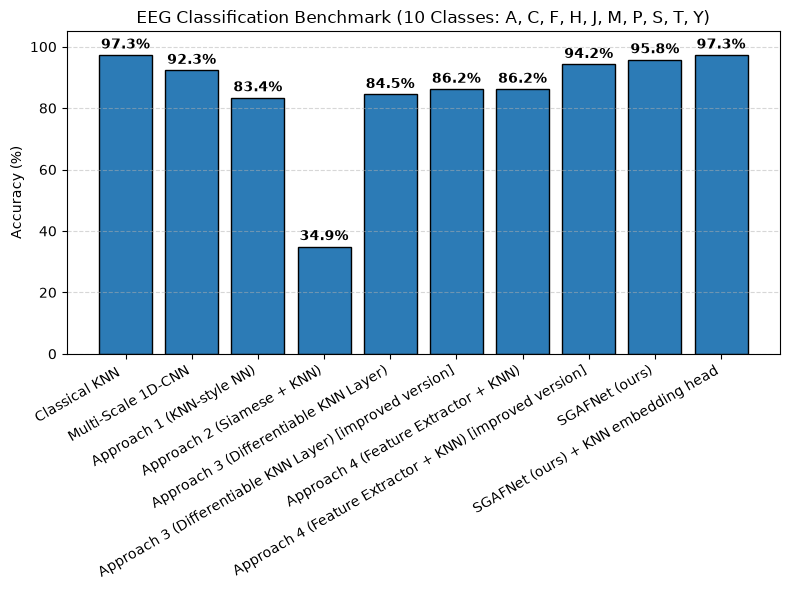

In [18]:
print("\n" + "=" * 60)
print("FINAL RESULTS")
print("=" * 60)

all_results = {
    "Classical KNN " : knn_acc,
    "Multi-Scale 1D-CNN": cnn_acc,
    "Approach 1 (KNN-style NN)": test_acc,
    "Approach 2 (Siamese + KNN)": approach2_acc,
    "Approach 3 (Differentiable KNN Layer)": approach3_test_acc,
    "Approach 3 (Differentiable KNN Layer) [improved version]": approach3_test_acc_im,
    "Approach 4 (Feature Extractor + KNN)": approach4_acc,
    "Approach 4 (Feature Extractor + KNN) [improved version]": acc
}
all_results["SGAFNet (ours)"] = SGAFNet_acc
all_results["SGAFNet (ours) + KNN embedding head"] = knn_acc
for name, acc in all_results.items():
    star = " ★ (Best)" if acc == max(all_results.values()) else ""
    print(f"  {name:25s}: {acc*100:.2f}%{star}")

plt.figure(figsize=(8, 6))
bars = plt.bar(all_results.keys(), [v * 100 for v in all_results.values()], color='#2c7bb6', edgecolor='black')
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, h + 1.0, f"{h:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.ylabel("Accuracy (%)")
plt.title(f"EEG Classification Benchmark (10 Classes: {', '.join(class_names)})")
plt.ylim(0, 105)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("eeg_final_results.png", dpi=150)
plt.show()


COMPREHENSIVE MODEL EVALUATION SUMMARY
Model                                             Test     Prec   Recall       F1
-------------------------------------------------------------------------------------
KNN (k=5)                                       92.13%   92.29%   92.12%   92.14%
Multi-Scale 1D-CNN                              92.32%   92.43%   92.31%   92.32%
Approach 1 (KNN-style NN)                       83.40%   83.48%   83.40%   83.39%
Approach 2 (Siamese + KNN)                      34.93%   37.84%   34.95%   35.38%
Approach 3 (Diff. KNN Layer)                    84.45%   85.26%   84.43%   84.58%
Approach 3 (Diff. KNN Layer - improved)         86.18%   86.43%   86.18%   86.20%
Approach 4 (Feature Extractor + KNN)            86.18%   86.34%   86.18%   86.20%
Approach 4 (NN head)                            83.78%   84.02%   83.78%   83.81%
SGAFNet (ours)                                  95.78%   95.82%   95.76%   95.76%
SGAFNet + KNN embedding head                    97.31%

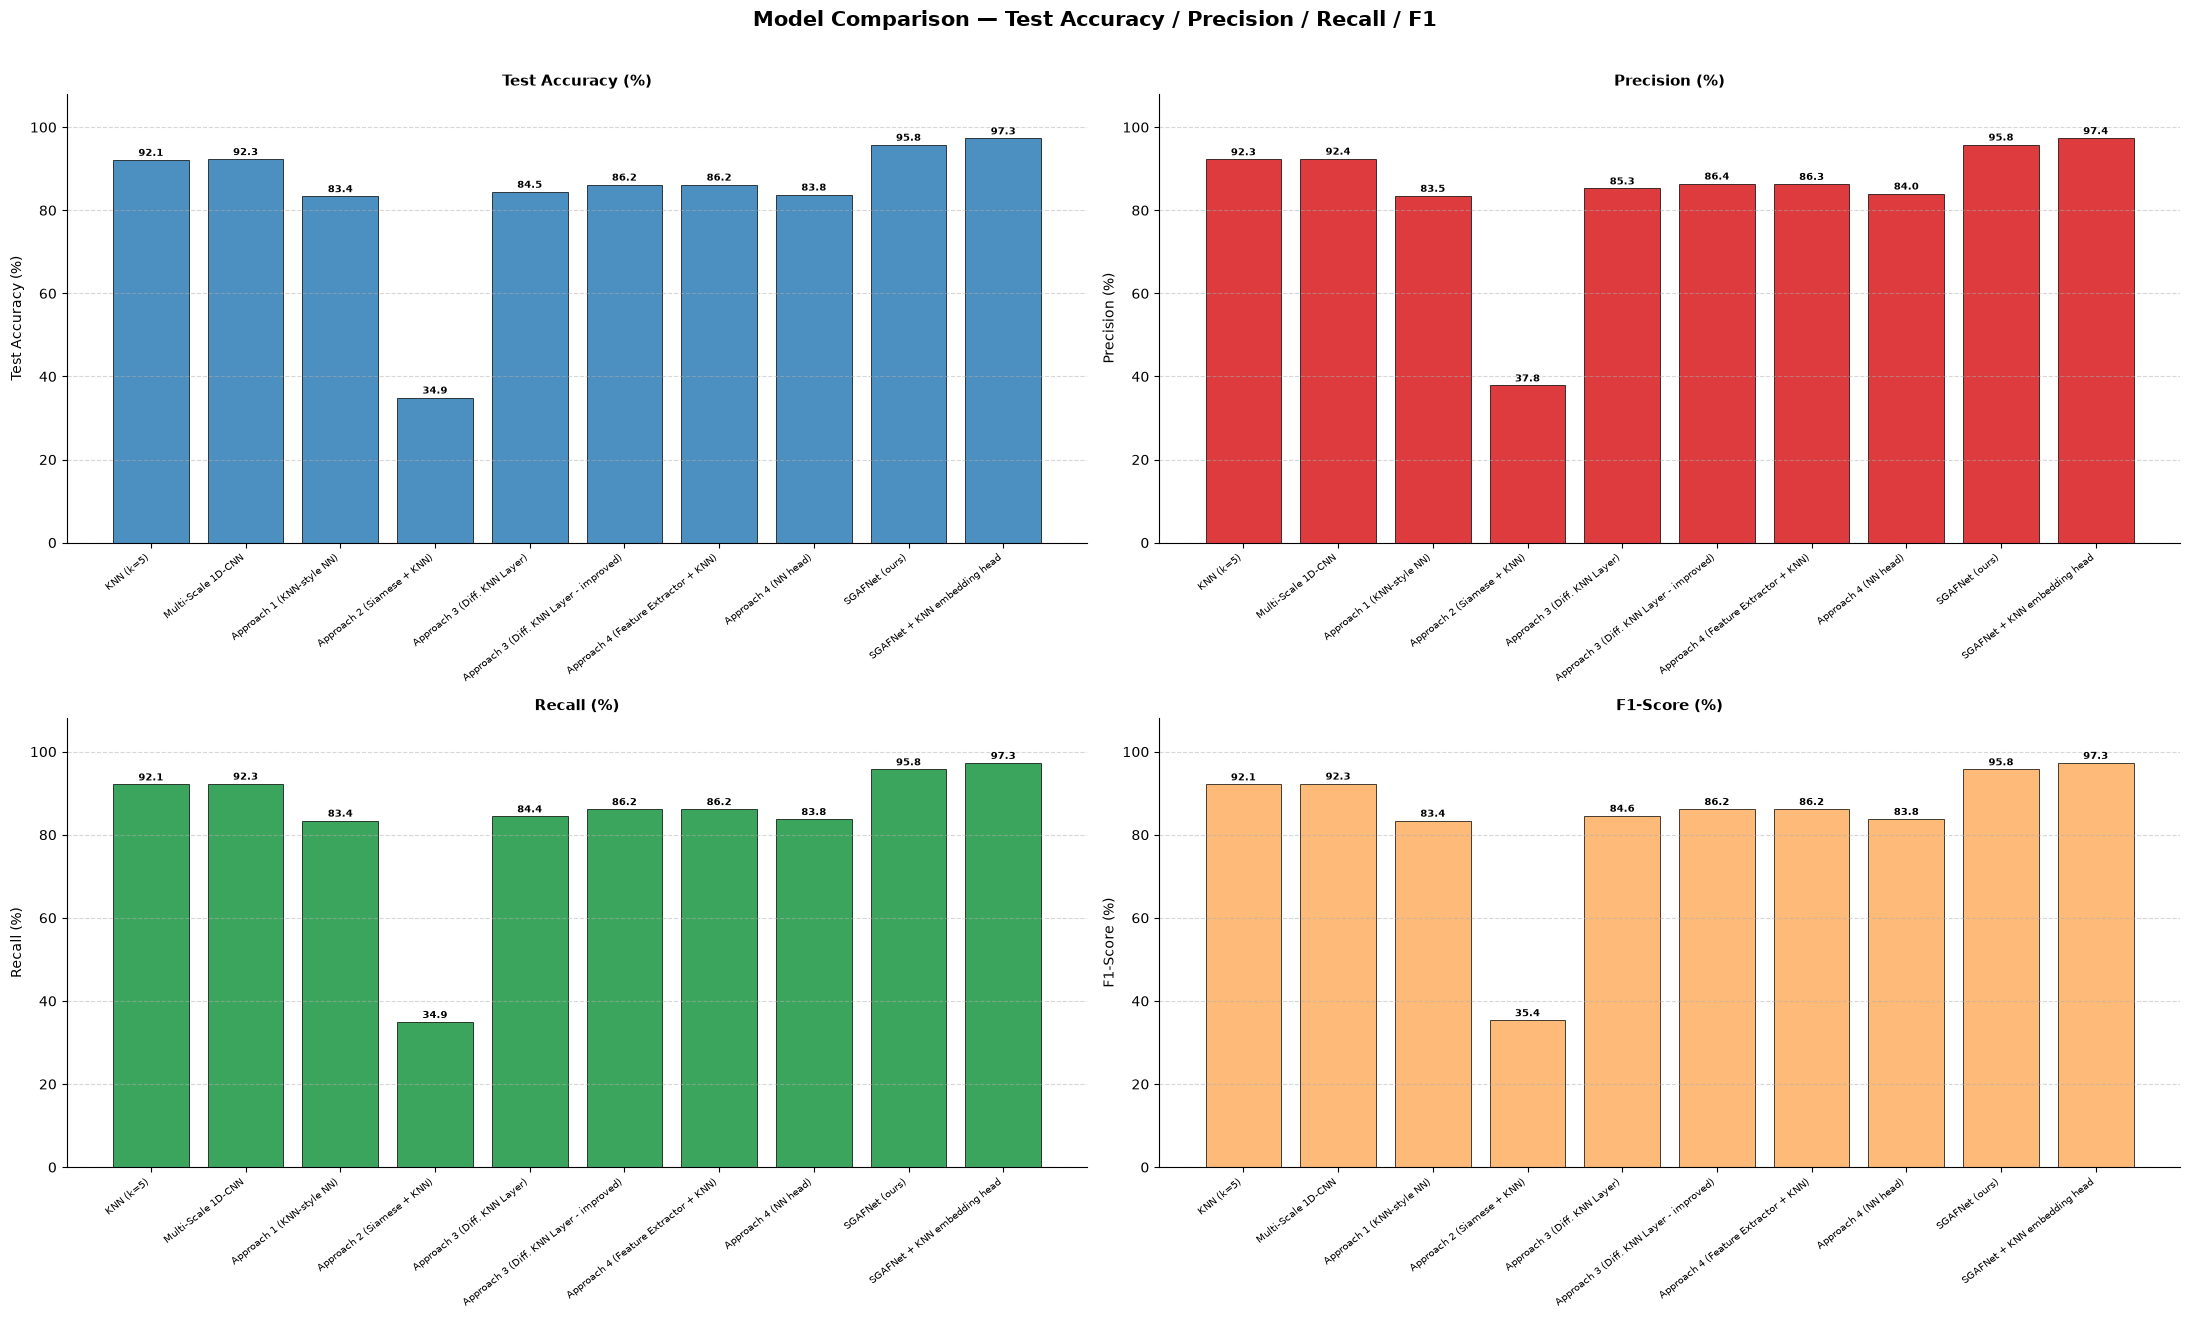

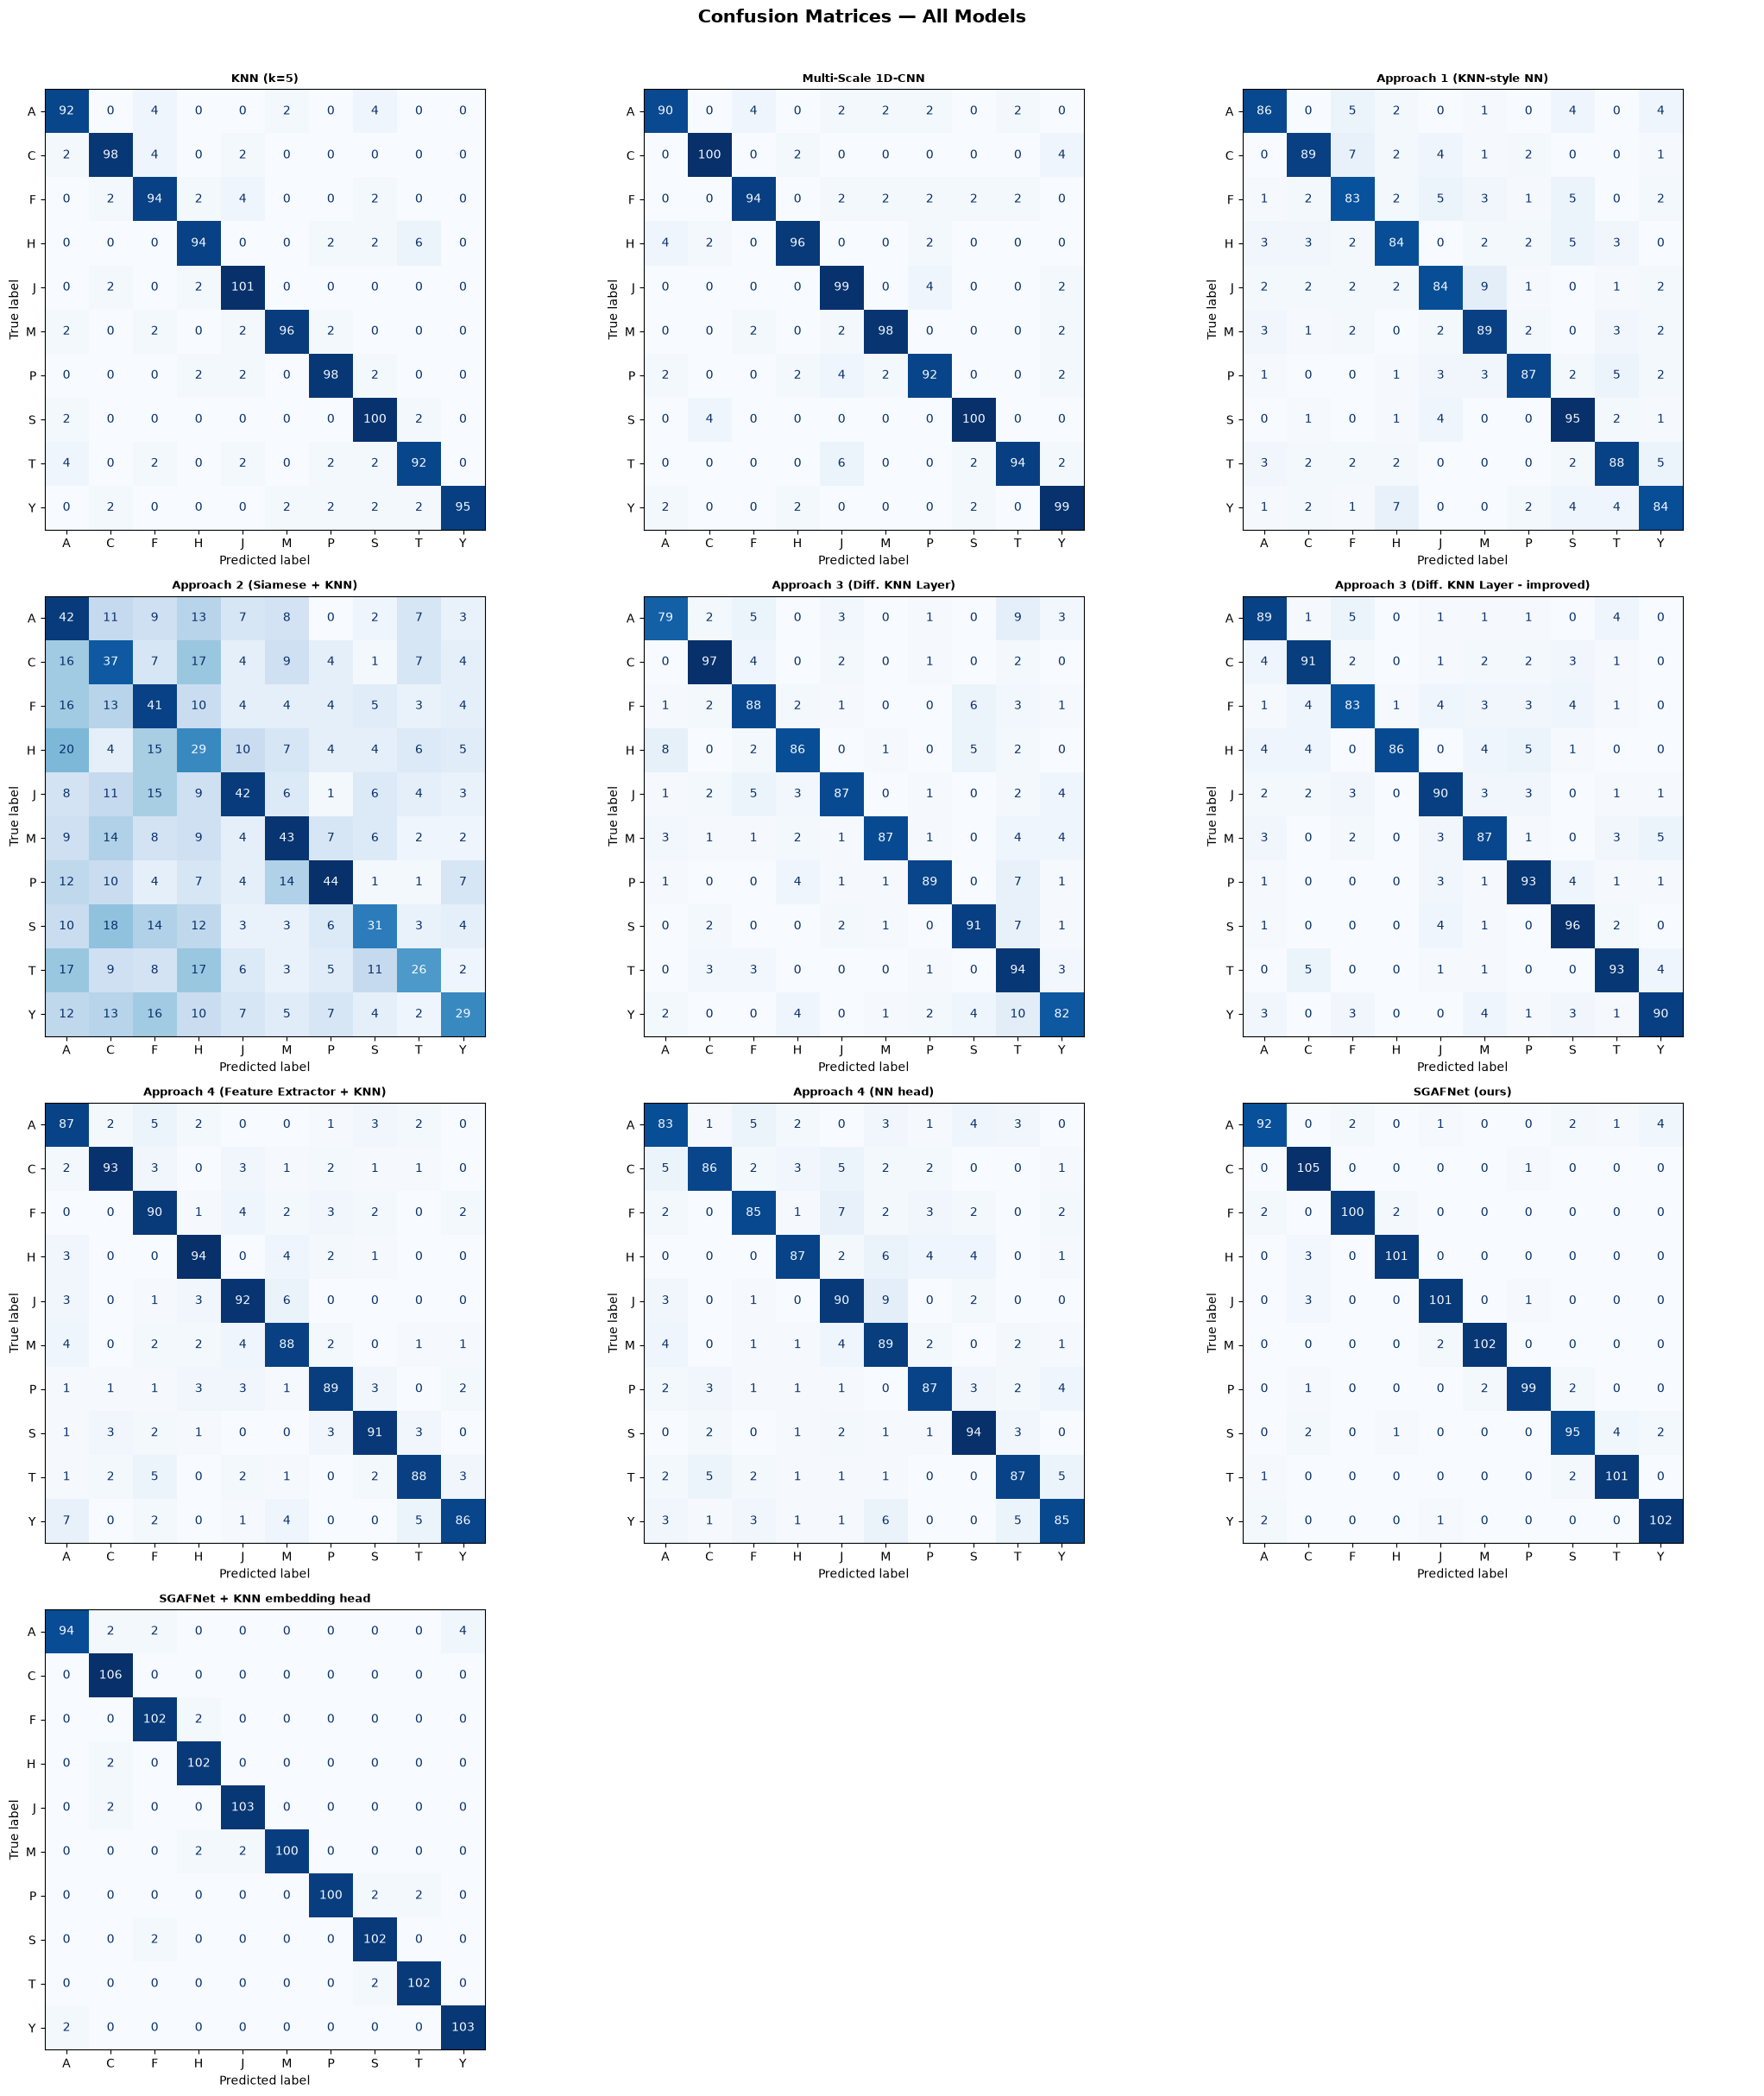

In [19]:
# ============================================================
# COMPREHENSIVE EVALUATION — ALL MODELS
# Training Acc · Validation Acc · Test Acc
# Precision · Recall · F1  (macro-averaged)
# Confusion Matrices · Learning Curves
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# ── Re-generate Keras model predictions ──────────────────────
approach1_pred    = np.argmax(approach1_model.predict(X_test, verbose=0), axis=1)
approach3_pred    = np.argmax(approach3_model_im.predict(X_test, verbose=0), axis=1)
approach3_pred_v1 = np.argmax(approach3_model.predict(X_test, verbose=0), axis=1)
approach4_pred_nn = np.argmax(approach4_feature_extractor.predict(X_test, verbose=0), axis=1)

# ────────────────────────────────────────────────────────────
# MODEL REGISTRY
# (display_name, y_true, y_pred, keras_history_or_None)
# ────────────────────────────────────────────────────────────
MODELS = [
    ("KNN (k=5)",                                y_test,  knn_pred,          None),
    # Deep learning
    ("Multi-Scale 1D-CNN",                       yr_test, cnn_preds,         None),
    ("Approach 1 (KNN-style NN)",                y_test,  approach1_pred,    approach1_history),
    ("Approach 2 (Siamese + KNN)",               y_test,  approach2_pred,    approach2_history),
    ("Approach 3 (Diff. KNN Layer)",             y_test,  approach3_pred_v1, approach3_history),
    ("Approach 3 (Diff. KNN Layer - improved)",  y_test,  approach3_pred,    approach3_history),
    ("Approach 4 (Feature Extractor + KNN)",     y_test,  approach4_pred,    None),
    ("Approach 4 (NN head)",                     y_test,  approach4_pred_nn, None),
    ("SGAFNet (ours)",                           y_test,  SGAFNet_pred,      history),
    ("SGAFNet + KNN embedding head",             y_test,  knn_pred1,         history),
]

# ── Helper: pull final train/val accuracy from Keras History ─
def get_train_val_acc(hist):
    if hist is None or not hasattr(hist, 'history'):
        return None, None
    h = hist.history
    # 'accuracy' key may be absent (e.g. contrastive-loss Siamese model)
    acc_key     = next((k for k in ('accuracy', 'acc') if k in h), None)
    val_acc_key = next((k for k in ('val_accuracy', 'val_acc') if k in h), None)
    train = h[acc_key][-1]     if acc_key     else None
    val   = h[val_acc_key][-1] if val_acc_key else None
    return train, val

# ── Build scalar metrics table ────────────────────────────────
avg  = "macro"
rows = []
for name, y_true, y_pred, hist in MODELS:
    train_acc, val_acc = get_train_val_acc(hist)
    rows.append({
        "Model":      name,
        "Train Acc":  train_acc,
        "Val Acc":    val_acc,
        "Test Acc":   accuracy_score(y_true, y_pred),
        "Precision":  precision_score(y_true, y_pred, average=avg, zero_division=0),
        "Recall":     recall_score(y_true, y_pred, average=avg, zero_division=0),
        "F1":         f1_score(y_true, y_pred, average=avg, zero_division=0),
    })

# ── Console summary table ─────────────────────────────────────
print("\n" + "=" * 85)
print("COMPREHENSIVE MODEL EVALUATION SUMMARY")
print("=" * 85)
print(f"{'Model':<45} {'Test':>8} {'Prec':>8} {'Recall':>8} {'F1':>8}")
print("-" * 85)
best_acc = max(r["Test Acc"] for r in rows)
for r in rows:
    star = " *" if abs(r["Test Acc"] - best_acc) < 1e-9 else ""
    print(f"{r['Model']:<45} "
          f"{r['Test Acc']*100:7.2f}% "
          f"{r['Precision']*100:7.2f}% "
          f"{r['Recall']*100:7.2f}% "
          f"{r['F1']*100:7.2f}%{star}")
print("=" * 85)

# ── Per-class classification reports ─────────────────────────
print("\n\n" + "=" * 80)
print("PER-CLASS CLASSIFICATION REPORTS")
print("=" * 80)
for name, y_true, y_pred, _ in MODELS:
    print(f"\n{'─'*60}\n{name}\n{'─'*60}")
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

# ────────────────────────────────────────────────────────────
# FIGURE 1 — Test Acc / Precision / Recall / F1 bar charts
# ────────────────────────────────────────────────────────────
model_names = [r["Model"]     for r in rows]
test_accs   = [r["Test Acc"]  for r in rows]
precisions  = [r["Precision"] for r in rows]
recalls     = [r["Recall"]    for r in rows]
f1s         = [r["F1"]        for r in rows]
x           = np.arange(len(model_names))
palette     = ["#2c7bb6", "#d7191c", "#1a9641", "#fdae61"]

fig1, axes1 = plt.subplots(2, 2, figsize=(22, 13))
fig1.suptitle("Model Comparison — Test Accuracy / Precision / Recall / F1",
              fontsize=15, fontweight="bold", y=1.01)

for ax, vals, title, color in [
    (axes1[0, 0], test_accs,  "Test Accuracy (%)",  palette[0]),
    (axes1[0, 1], precisions, "Precision (%)",       palette[1]),
    (axes1[1, 0], recalls,    "Recall (%)",          palette[2]),
    (axes1[1, 1], f1s,        "F1-Score (%)",        palette[3]),
]:
    bars = ax.bar(x, [v * 100 for v in vals], color=color,
                  edgecolor="black", linewidth=0.6, alpha=0.85)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.4,
                f"{h:.1f}", ha="center", va="bottom", fontsize=7, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(model_names, rotation=38, ha='right', fontsize=7.5)
    ax.set_ylabel(title, fontsize=10)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_ylim(0, 108)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# ────────────────────────────────────────────────────────────
# FIGURE 2 — Confusion matrices (all models, 3-column grid)
# ────────────────────────────────────────────────────────────
n_models = len(MODELS)
n_cols   = 3
n_rows   = int(np.ceil(n_models / n_cols))

fig2, axes2 = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 6 * n_rows))
fig2.suptitle("Confusion Matrices — All Models",
              fontsize=15, fontweight="bold", y=1.01)
axes2 = axes2.ravel()

for ax, (name, y_true, y_pred, _) in zip(axes2, MODELS):
    cm   = confusion_matrix(y_true, y_pred, labels=range(num_classes))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name, fontweight='bold', fontsize=9)

for ax in axes2[n_models:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.mplot3d import Axes3D          # noqa: F401 (registers 3d projection)
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, f1_score, precision_score, recall_score,
    roc_curve, auc, accuracy_score,
)
from sklearn.preprocessing import label_binarize, normalize
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore")

# ── Publication-quality defaults ─────────────────────────────────────────────
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.1,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "lines.linewidth": 1.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

COLORS = {
    "sgafnet": "#1565C0",
    "knn":     "#E53935",
    "accent1": "#43A047",
    "accent2": "#8E24AA",
    "accent3": "#FF8F00",
    "accent4": "#00838F",
    "dark":    "#263238",
    "light":   "#ECEFF1",
}

# Class palette (up to 10 classes)
CLASS_PALETTE = [
    "#1565C0", "#E53935", "#43A047", "#8E24AA", "#FF8F00",
    "#00838F", "#6D4C41", "#00796B", "#AD1457", "#558B2F",
]


# ══════════════════════════════════════════════════════════════════════════════
# INTERNAL HELPERS
# ══════════════════════════════════════════════════════════════════════════════

def _get_embeddings(sgafnet_model, Xr, Xf):
    """Return (logits, embeddings) from SGAFNet."""
    logits, embeddings = sgafnet_model.predict([Xr, Xf], verbose=0)
    return logits, embeddings


def _norm_embeddings(sgafnet_model, Xr_train, Xf_train, Xr_test, Xf_test):
    """Return l2-normalized train & test embeddings."""
    _, tr_emb = _get_embeddings(sgafnet_model, Xr_train, Xf_train)
    _, te_emb = _get_embeddings(sgafnet_model, Xr_test,  Xf_test)
    return normalize(tr_emb), normalize(te_emb)


def _fit_knn(train_embed_n, y_train, k=5):
    """Fit a cosine-distance KNN on normalized embeddings."""
    knn = KNeighborsClassifier(n_neighbors=k, weights="distance", metric="cosine")
    knn.fit(train_embed_n, y_train)
    return knn


# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 1 – Training & Validation Accuracy / Loss Curves
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure1_training_curves(history):
    """Fig 1: Classifier accuracy and total loss over epochs."""
    h = history.history
    epochs = range(1, len(h["classifier_accuracy"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # — Accuracy —
    ax = axes[0]
    ax.plot(epochs, h["classifier_accuracy"],     color=COLORS["sgafnet"], label="Train Acc")
    ax.plot(epochs, h["val_classifier_accuracy"], color=COLORS["knn"],
            linestyle="--", label="Val Acc")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.set_title("(a) Classifier Head Accuracy")
    ax.legend()

    # — Loss —
    ax = axes[1]
    total_train = np.array(h["loss"])
    total_val   = np.array(h["val_loss"])
    ax.plot(epochs, total_train, color=COLORS["sgafnet"], label="Train Loss (total)")
    ax.plot(epochs, total_val,   color=COLORS["knn"], linestyle="--", label="Val Loss (total)")
    if "classifier_loss" in h:
        ax.plot(epochs, h["classifier_loss"], color=COLORS["accent1"],
                linestyle=":", label="CE Loss")
    if "embedding_loss" in h:
        ax.plot(epochs, h["embedding_loss"], color=COLORS["accent2"],
                linestyle=":", label="Contrastive Loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_title("(b) Loss Components")
    ax.legend()

    plt.suptitle("Figure 1: SGAFNet Training Curves", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 2 – Confusion Matrix (KNN embedding head)
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure2_confusion_matrix(y_test, knn_pred1, class_names):
    """Fig 2: Confusion matrix for the KNN embedding head."""
    cm = confusion_matrix(y_test, knn_pred1)
    fig, ax = plt.subplots(figsize=(10, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=ax, cmap="Blues", colorbar=True, values_format="d")
    ax.set_title("Figure 2: Confusion Matrix — SGAFNet + KNN Embedding Head",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 3 – Per-Class F1 Score Bar Chart
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure3_per_class_f1(y_test, knn_pred1, SGAFNet_pred, class_names):
    """Fig 3: Per-class F1 for KNN head vs softmax head."""
    from sklearn.metrics import f1_score
    f1_knn  = f1_score(y_test, knn_pred1,    average=None, zero_division=0)
    f1_soft = f1_score(y_test, SGAFNet_pred, average=None, zero_division=0)

    x   = np.arange(len(class_names))
    w   = 0.35
    fig, ax = plt.subplots(figsize=(13, 5))

    bars1 = ax.bar(x - w / 2, f1_knn  * 100, w, color=COLORS["sgafnet"],
                   alpha=0.85, edgecolor="black", linewidth=0.5, label="KNN Embedding Head")
    bars2 = ax.bar(x + w / 2, f1_soft * 100, w, color=COLORS["knn"],
                   alpha=0.85, edgecolor="black", linewidth=0.5, label="Softmax Head")

    for bar in list(bars1) + list(bars2):
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.5,
                f"{h:.1f}", ha="center", va="bottom", fontsize=7.5, fontweight="bold")

    ax.set_xticks(x)
    ax.set_xticklabels(class_names, fontsize=11)
    ax.set_ylabel("F1 Score (%)")
    ax.set_ylim(0, 112)
    ax.set_title("Figure 3: Per-Class F1 Score — KNN Embedding Head vs Softmax Head",
                 fontsize=13, fontweight="bold")
    ax.legend()
    ax.axhline(np.mean(f1_knn) * 100, color=COLORS["sgafnet"],
               linestyle="--", alpha=0.5, label="KNN macro-avg")
    ax.axhline(np.mean(f1_soft) * 100, color=COLORS["knn"],
               linestyle="--", alpha=0.5, label="Softmax macro-avg")
    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 4 – SGAFNet Architecture Diagram
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure4_architecture_diagram():
    """Fig 4: SGAFNet block-level architecture."""
    fig, ax = plt.subplots(figsize=(18, 7))
    ax.set_xlim(0, 20)
    ax.set_ylim(0, 8)
    ax.axis("off")

    def block(x, y, w, h, text, fc, fontsize=7.5):
        rect = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.12",
                              facecolor=fc, edgecolor="#37474F", linewidth=1.5, alpha=0.88)
        ax.add_patch(rect)
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center",
                fontsize=fontsize, fontweight="bold",
                color="white" if sum(int(fc[i:i+2], 16)
                                     for i in (1, 3, 5)) < 400 else "#263238")

    def arrow(x1, y1, x2, y2):
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle="->", color="#37474F", lw=1.8))

    # Raw waveform branch
    block(0.2, 5.2, 1.6, 0.9, "Raw EEG\n(N,T,C)", "#FFECB3", fontsize=7)
    arrow(1.8, 5.65, 2.2, 5.65)
    block(2.2, 4.7, 2.8, 1.9,
          "Temporal Branch\nSepConv×3 (k=31,15,7)\nSE-Block\nConcat→Conv1D→Pool",
          "#BBDEFB", fontsize=7)
    arrow(5.0, 5.65, 5.5, 5.65)
    block(5.5, 5.2, 1.8, 0.9, "Sequence\n(T', 128)", "#E8F5E9", fontsize=7)

    # Spectral branch
    block(0.2, 2.2, 1.6, 0.9, "Feat Vec\n(N,1678)", "#FFECB3", fontsize=7)
    arrow(1.8, 2.65, 2.2, 2.65)
    block(2.2, 2.0, 2.8, 1.3,
          "Spectral Branch\nDense(256)→BN\nDense(128)→BN",
          "#F3E5F5", fontsize=7)
    arrow(5.0, 2.65, 5.5, 2.65)
    block(5.5, 2.2, 1.8, 0.9, "Vec (128)", "#E8F5E9", fontsize=7)

    # Fusion module
    block(7.7, 3.5, 3.5, 2.5,
          "Spectral-Guided\nAttention Fusion\n──────────────\nQuery←Spectral Vec\nMH-Attention(4 heads)\nGated Concat",
          "#1565C0", fontsize=7)
    arrow(7.3, 5.65, 7.7, 5.0)
    arrow(7.3, 2.65, 7.7, 4.0)

    # Embedding
    arrow(11.2, 4.75, 11.6, 4.75)
    block(11.6, 4.2, 2.2, 1.1, "Fused Embedding\nDense(128)→BN\nDense(128)",
          "#004D40", fontsize=7)

    # Two heads
    arrow(13.8, 4.75, 14.3, 5.8)
    block(14.3, 5.4, 2.5, 0.9,
          "Softmax Head\nDropout(0.35)→Dense(C)",
          "#C62828", fontsize=7)

    arrow(13.8, 4.75, 14.3, 3.5)
    block(14.3, 3.0, 2.5, 0.9,
          "Embedding Head\n(linear, for KNN)",
          "#1B5E20", fontsize=7)

    # KNN read-out
    arrow(16.8, 3.45, 17.2, 3.45)
    block(17.2, 3.0, 2.5, 0.9, "Cosine KNN\n(distance-weighted)",
          "#E65100", fontsize=7)

    # Labels
    ax.text(10, 7.6, "SGAFNet — Spectral-Guided Attention Fusion Network",
            ha="center", fontsize=15, fontweight="bold", style="italic")

    legend_specs = [
        ("Input", "#FFECB3"), ("Temporal / Spectral", "#BBDEFB"),
        ("Fusion (novel)", "#1565C0"), ("Embedding", "#004D40"),
        ("Classifier", "#C62828"), ("KNN head", "#E65100"),
    ]
    for i, (lbl, fc) in enumerate(legend_specs):
        block(0.3 + i * 3.2, 0.2, 2.8, 0.55, lbl, fc, fontsize=7)

    plt.suptitle("Figure 4: SGAFNet Architecture", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 5 – Spectral-Guided Attention Maps
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure5_attention_maps(attention_model, Xr_test, Xf_test, y_test,
                                 class_names, n_samples=6):
    """Fig 5: Multi-head attention scores (spectral query over raw sequence)."""
    indices = []
    for c in range(len(class_names)):
        idx = np.where(np.asarray(y_test) == c)[0]
        if len(idx):
            indices.append(idx[0])
        if len(indices) >= n_samples:
            break

    attn_batch = attention_model.predict(
        [Xr_test[indices], Xf_test[indices]], verbose=0
    )
    # attn_batch shape: (N, num_heads, 1, T')
    attn_avg = attn_batch[:, :, 0, :].mean(axis=1)   # (N, T')

    fig, axes = plt.subplots(2, 3, figsize=(16, 7))
    axes = axes.ravel()

    for i, idx in enumerate(indices):
        ax = axes[i]
        t = np.arange(attn_avg.shape[1])
        ax.fill_between(t, attn_avg[i], alpha=0.65,
                        color=CLASS_PALETTE[y_test[indices[i]] % len(CLASS_PALETTE)])
        ax.plot(t, attn_avg[i], linewidth=0.8,
                color=CLASS_PALETTE[y_test[indices[i]] % len(CLASS_PALETTE)])
        ax.set_title(f"Class: {class_names[y_test[indices[i]]]}  (sample {idx})",
                     fontsize=10)
        ax.set_xlabel("Temporal position (downsampled)")
        ax.set_ylabel("Attention weight")

    plt.suptitle("Figure 5: Spectral-Guided Attention over Raw EEG Sequence",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 6 – t-SNE of Fused Embeddings
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure6_tsne(sgafnet_model, Xr_train, Xf_train, Xr_test, Xf_test,
                      y_train, y_test, class_names, perplexity=40, random_state=42):
    """Fig 6: 2-D t-SNE of train (circles) and test (stars) embeddings."""
    tr_n, te_n = _norm_embeddings(sgafnet_model, Xr_train, Xf_train, Xr_test, Xf_test)
    all_emb = np.vstack([tr_n, te_n])
    all_lbl = np.concatenate([y_train, y_test])
    split   = len(y_train)

    print("Running t-SNE…")
    tsne = TSNE(n_components=2, perplexity=perplexity,
            random_state=random_state, max_iter=1000)
    emb2d = tsne.fit_transform(all_emb)

    fig, ax = plt.subplots(figsize=(11, 9))
    for c in range(len(class_names)):
        mask_tr = (all_lbl[:split] == c)
        mask_te = (all_lbl[split:] == c)
        col = CLASS_PALETTE[c % len(CLASS_PALETTE)]
        if mask_tr.any():
            ax.scatter(emb2d[:split][mask_tr, 0], emb2d[:split][mask_tr, 1],
                       c=col, s=18, alpha=0.55, marker="o")
        if mask_te.any():
            ax.scatter(emb2d[split:][mask_te, 0], emb2d[split:][mask_te, 1],
                       c=col, s=55, alpha=0.9, marker="*", edgecolors="black",
                       linewidths=0.4, label=class_names[c])

    ax.legend(title="Class (★=test)", loc="best", fontsize=9,
              markerscale=1.4, framealpha=0.85)
    ax.set_title("Figure 6: t-SNE of SGAFNet Fused Embeddings\n"
                 "(● train  ★ test)", fontsize=13, fontweight="bold")
    ax.set_xlabel("t-SNE dim 1")
    ax.set_ylabel("t-SNE dim 2")
    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 7 – KNN Nearest-Neighbor Distance Bar (single test sample)
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure7_knn_neighbor_distances(sgafnet_model,
                                         Xr_train, Xf_train,
                                         Xr_test,  Xf_test,
                                         y_train, y_test,
                                         class_names,
                                         sample_idx=0, k=5):
    """Fig 7: Cosine distances to k nearest training neighbours for one test sample."""
    tr_n, te_n = _norm_embeddings(sgafnet_model, Xr_train, Xf_train, Xr_test, Xf_test)
    knn = _fit_knn(tr_n, y_train, k=k)

    sample         = te_n[sample_idx:sample_idx + 1]
    distances, idx = knn.kneighbors(sample)
    nbr_labels     = np.asarray(y_train)[idx[0]]
    nbr_dists      = distances[0]

    true_cls = class_names[y_test[sample_idx]]
    pred_cls = class_names[nbr_labels[0]]

    fig, ax = plt.subplots(figsize=(9, 4.5))
    colors  = [CLASS_PALETTE[l % len(CLASS_PALETTE)] for l in nbr_labels]
    bars    = ax.bar(range(1, k + 1), nbr_dists,
                     color=colors, edgecolor="black", linewidth=0.7)

    for i, bar in enumerate(bars):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.002,
                f"Class: {class_names[nbr_labels[i]]}",
                ha="center", va="bottom", fontsize=9)

    ax.set_title(
        f"Figure 7: KNN Embedding Head — Nearest Neighbour Distances\n"
        f"Test sample #{sample_idx}  |  True: {true_cls}  |  Predicted: {pred_cls}",
        fontsize=12, fontweight="bold",
    )
    ax.set_xlabel("Neighbour Rank")
    ax.set_ylabel("Cosine Distance")
    ax.set_xticks(range(1, k + 1))
    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 8 – PCA 3-D Embedding Scatter
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure8_pca3d(sgafnet_model, Xr_test, Xf_test, y_test, class_names):
    """Fig 8: First 3 principal components of test embeddings."""
    _, te_emb = _get_embeddings(sgafnet_model, Xr_test, Xf_test)
    te_n      = normalize(te_emb)
    pca3      = PCA(n_components=3, random_state=42)
    coords    = pca3.fit_transform(te_n)
    var_exp   = pca3.explained_variance_ratio_ * 100

    fig = plt.figure(figsize=(11, 8))
    ax  = fig.add_subplot(111, projection="3d")

    for c in range(len(class_names)):
        mask = (np.asarray(y_test) == c)
        ax.scatter(coords[mask, 0], coords[mask, 1], coords[mask, 2],
                   c=CLASS_PALETTE[c % len(CLASS_PALETTE)],
                   s=20, alpha=0.7, label=class_names[c])

    ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}%)")
    ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}%)")
    ax.set_zlabel(f"PC3 ({var_exp[2]:.1f}%)")
    ax.set_title("Figure 8: PCA 3D — SGAFNet Fused Embeddings (test set)",
                 fontsize=12, fontweight="bold")
    ax.legend(loc="upper left", fontsize=8, markerscale=1.5)
    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 9 – Softmax Head vs KNN Head Accuracy Comparison
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure9_head_comparison(y_test, SGAFNet_pred, knn_pred1, class_names):
    """Fig 9: Side-by-side per-class accuracy: softmax head vs KNN head."""
    n = len(class_names)
    soft_acc = np.array([
        accuracy_score(np.asarray(y_test)[np.asarray(y_test) == c],
                       np.asarray(SGAFNet_pred)[np.asarray(y_test) == c])
        for c in range(n)
    ])
    knn_acc = np.array([
        accuracy_score(np.asarray(y_test)[np.asarray(y_test) == c],
                       np.asarray(knn_pred1)[np.asarray(y_test) == c])
        for c in range(n)
    ])

    x  = np.arange(n)
    w  = 0.35
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.bar(x - w / 2, soft_acc * 100, w, color=COLORS["knn"],   alpha=0.85,
           edgecolor="black", linewidth=0.5, label="Softmax Head")
    ax.bar(x + w / 2, knn_acc  * 100, w, color=COLORS["sgafnet"], alpha=0.85,
           edgecolor="black", linewidth=0.5, label="KNN Embedding Head")

    ax.set_xticks(x)
    ax.set_xticklabels(class_names, fontsize=11)
    ax.set_ylabel("Per-Class Accuracy (%)")
    ax.set_ylim(0, 112)
    ax.set_title("Figure 9: Per-Class Accuracy — Softmax Head vs KNN Embedding Head",
                 fontsize=13, fontweight="bold")
    ax.legend()
    ax.axhline(soft_acc.mean() * 100, color=COLORS["knn"],
               linestyle="--", alpha=0.5)
    ax.axhline(knn_acc.mean()  * 100, color=COLORS["sgafnet"],
               linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 10 – Supervised Contrastive Loss vs Epoch
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure10_contrastive_loss(history):
    """Fig 10: Embedding (contrastive) loss train vs val over epochs."""
    h      = history.history
    epochs = range(1, len(h.get("embedding_loss",
                                 h.get("loss", []))) + 1)

    emb_tr  = h.get("embedding_loss",     h.get("loss", []))
    emb_val = h.get("val_embedding_loss", h.get("val_loss", []))
    cls_tr  = h.get("classifier_loss",    h.get("loss", []))
    cls_val = h.get("val_classifier_loss", h.get("val_loss", []))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ax = axes[0]
    ax.plot(epochs, emb_tr,  color=COLORS["sgafnet"], label="Train Contrastive")
    ax.plot(epochs, emb_val, color=COLORS["knn"], linestyle="--",
            label="Val Contrastive")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Contrastive Loss")
    ax.set_title("(a) Supervised Contrastive Loss")
    ax.legend()

    ax = axes[1]
    ax.plot(epochs, cls_tr,  color=COLORS["accent1"], label="Train CE")
    ax.plot(epochs, cls_val, color=COLORS["accent3"], linestyle="--", label="Val CE")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-Entropy Loss")
    ax.set_title("(b) Cross-Entropy Classification Loss")
    ax.legend()

    plt.suptitle("Figure 10: Loss Decomposition — Contrastive + CE",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()


# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 11 – Multi-Scale Temporal Branch: Activation Maps
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure11_multiscale_activations(sgafnet_model, Xr_test, Xf_test,
                                          y_test, class_names, sample_idx=0):
    """Fig 11: Intermediate activations from slow / mid / fast scale branches."""
    import tensorflow as tf

    layer_names = ["multiscale_concat"]
    # also grab individual SE outputs if present
    se_layers = [l.name for l in sgafnet_model.layers
                 if "multiply" in l.name.lower()][:3]
    target_layers = se_layers if se_layers else layer_names

    sample_r = Xr_test[sample_idx:sample_idx + 1]
    sample_f = Xf_test[sample_idx:sample_idx + 1]

    act_model = tf.keras.Model(
        inputs=sgafnet_model.inputs,
        outputs=[sgafnet_model.get_layer(n).output for n in target_layers],
    )
    acts = act_model.predict([sample_r, sample_f], verbose=0)
    if not isinstance(acts, list):
        acts = [acts]

    n = len(acts)
    scale_labels = ["Slow (k=31)", "Mid (k=15)", "Fast (k=7)"]
    fig, axes = plt.subplots(1, n, figsize=(6 * n, 4))
    if n == 1:
        axes = [axes]

    for i, (act, ax) in enumerate(zip(acts, axes)):
        map2d = act[0].T   # (channels, time)
        im = ax.imshow(map2d, aspect="auto", cmap="viridis", origin="lower")
        ax.set_xlabel("Time step")
        ax.set_ylabel("Channel")
        label = scale_labels[i] if i < len(scale_labels) else target_layers[i]
        ax.set_title(f"({chr(97+i)}) {label}")
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Activation")

    cls_lbl = class_names[y_test[sample_idx]]
    plt.suptitle(f"Figure 11: Multi-Scale Temporal Activations  |  "
                 f"Class: {cls_lbl}  (sample #{sample_idx})",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 12 – Squeeze-and-Excitation Channel Weights
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure12_se_channel_weights(sgafnet_model, Xr_test, Xf_test,
                                      y_test, class_names):
    """Fig 12: Average SE gate values per class for each SE block."""
    import tensorflow as tf

    # find Multiply layers that are SE gates (typically 3 in temporal branch)
    se_layers = [l.name for l in sgafnet_model.layers
                 if "multiply" in l.name.lower()][:3]
    if not se_layers:
        print("No SE (Multiply) layers found – skipping Fig 12.")
        return

    act_model = tf.keras.Model(
        inputs=sgafnet_model.inputs,
        outputs=[sgafnet_model.get_layer(n).output for n in se_layers],
    )
    acts = act_model.predict([Xr_test, Xf_test], verbose=0)
    if not isinstance(acts, list):
        acts = [acts]

    n_se  = len(acts)
    fig, axes = plt.subplots(1, n_se, figsize=(6 * n_se, 5))
    if n_se == 1:
        axes = [axes]
    scale_labels = ["Slow (k=31)", "Mid (k=15)", "Fast (k=7)"]

    for i, (act, ax) in enumerate(zip(acts, axes)):
        # act shape: (N, T, C) — average over time
        gate_vals = act.mean(axis=1)   # (N, C)
        # build per-class mean gate vector
        n_cls    = len(class_names)
        class_means = np.zeros((n_cls, gate_vals.shape[1]))
        for c in range(n_cls):
            mask = (np.asarray(y_test) == c)
            if mask.any():
                class_means[c] = gate_vals[mask].mean(axis=0)

        im = ax.imshow(class_means, aspect="auto", cmap="RdYlBu_r",
                       vmin=0, vmax=1)
        ax.set_yticks(range(n_cls))
        ax.set_yticklabels(class_names, fontsize=9)
        ax.set_xlabel("Channel")
        lbl = scale_labels[i] if i < len(scale_labels) else se_layers[i]
        ax.set_title(f"({chr(97+i)}) SE Gates — {lbl}", fontsize=10)
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Gate value")

    plt.suptitle("Figure 12: Squeeze-and-Excitation Channel Gate Values per Class",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 13 – Spectral Feature Importance (top 40)
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure13_feature_importance(Xf_train, y_train, top_k=40):
    """Fig 13: Random-Forest feature importances for the engineered feature vector."""
    from sklearn.ensemble import ExtraTreesClassifier as ETC
    print("Fitting ExtraTrees for feature importance (may take a moment)…")
    et = ETC(n_estimators=200, random_state=42, n_jobs=-1)
    et.fit(Xf_train, y_train)
    imp  = et.feature_importances_
    idx  = np.argsort(imp)[::-1][:top_k]

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.bar(range(top_k), imp[idx] * 100,
           color=COLORS["sgafnet"], edgecolor="black", linewidth=0.4, alpha=0.85)
    ax.set_xticks(range(top_k))
    ax.set_xticklabels([f"F{i}" for i in idx], rotation=90, fontsize=7)
    ax.set_xlabel("Feature index")
    ax.set_ylabel("Importance (%)")
    ax.set_title(f"Figure 13: Top-{top_k} Spectral Feature Importances (ExtraTrees)",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 14 – Per-Class Precision / Recall / F1 Heatmap
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure14_metrics_heatmap(y_test, knn_pred1, class_names):
    """Fig 14: Heatmap of precision, recall, F1 for each class."""
    from sklearn.metrics import precision_recall_fscore_support
    p, r, f, _ = precision_recall_fscore_support(
        y_test, knn_pred1, labels=range(len(class_names)),
        zero_division=0
    )
    matrix = np.stack([p, r, f], axis=0) * 100   # (3, C)

    fig, ax = plt.subplots(figsize=(12, 3.5))
    im = ax.imshow(matrix, cmap="YlOrRd", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(len(class_names)))
    ax.set_xticklabels(class_names, fontsize=11)
    ax.set_yticks([0, 1, 2])
    ax.set_yticklabels(["Precision", "Recall", "F1"], fontsize=11)
    for i in range(3):
        for j in range(len(class_names)):
            ax.text(j, i, f"{matrix[i, j]:.1f}",
                    ha="center", va="center", fontsize=9,
                    color="black" if matrix[i, j] < 70 else "white",
                    fontweight="bold")
    plt.colorbar(im, ax=ax, label="%", shrink=0.8)
    ax.set_title("Figure 14: Per-Class Precision / Recall / F1 — KNN Embedding Head",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 15 – ROC Curves (one-vs-rest, all classes)
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure15_roc_curves(sgafnet_model, Xr_train, Xf_train,
                              Xr_test, Xf_test,
                              y_train, y_test,
                              class_names, k=5):
    """Fig 15: One-vs-rest ROC for the KNN embedding head."""
    tr_n, te_n  = _norm_embeddings(sgafnet_model, Xr_train, Xf_train,
                                    Xr_test, Xf_test)
    knn = _fit_knn(tr_n, y_train, k=k)
    proba = knn.predict_proba(te_n)   # (N, C)

    n_cls   = len(class_names)
    y_bin   = label_binarize(y_test, classes=range(n_cls))

    fig, ax = plt.subplots(figsize=(10, 8))
    macro_auc = []
    for c in range(n_cls):
        fpr, tpr, _ = roc_curve(y_bin[:, c], proba[:, c])
        roc_auc     = auc(fpr, tpr)
        macro_auc.append(roc_auc)
        ax.plot(fpr, tpr, color=CLASS_PALETTE[c % len(CLASS_PALETTE)],
                linewidth=1.5, label=f"{class_names[c]} (AUC={roc_auc:.3f})")

    ax.plot([0, 1], [0, 1], "k--", linewidth=1, alpha=0.5)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"Figure 15: One-vs-Rest ROC Curves — KNN Embedding Head\n"
                 f"Macro-avg AUC = {np.mean(macro_auc):.4f}",
                 fontsize=13, fontweight="bold")
    ax.legend(loc="lower right", fontsize=9)
    plt.tight_layout()
    plt.show()


# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 16 – KNN k-Value Sensitivity
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure16_k_sensitivity(sgafnet_model,
                                 Xr_train, Xf_train,
                                 Xr_test,  Xf_test,
                                 y_train,  y_test,
                                 k_values=None):
    """Fig 16: Test accuracy vs k for cosine KNN on SGAFNet embeddings."""
    if k_values is None:
        k_values = [1, 3, 5, 7, 9, 11, 13, 15, 20, 25, 30]

    tr_n, te_n = _norm_embeddings(sgafnet_model, Xr_train, Xf_train,
                                   Xr_test, Xf_test)
    accs = []
    for k in k_values:
        knn  = _fit_knn(tr_n, y_train, k=k)
        pred = knn.predict(te_n)
        accs.append(accuracy_score(y_test, pred) * 100)

    best_k   = k_values[int(np.argmax(accs))]
    best_acc = max(accs)

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(k_values, accs, "o-", color=COLORS["sgafnet"],
            linewidth=2, markersize=7)
    ax.axvline(best_k, color=COLORS["knn"], linestyle="--", alpha=0.6,
               label=f"Best k={best_k}  ({best_acc:.2f}%)")
    ax.scatter([best_k], [best_acc], s=120, color=COLORS["knn"],
               zorder=5, edgecolors="black")

    ax.set_xlabel("k (number of neighbours)")
    ax.set_ylabel("Test Accuracy (%)")
    ax.set_title("Figure 16: KNN k-Value Sensitivity on SGAFNet Embeddings",
                 fontsize=13, fontweight="bold")
    ax.set_xticks(k_values)
    ax.legend()
    plt.tight_layout()
    plt.show()


# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 17 – Embedding Norm Distribution
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure17_embedding_norms(sgafnet_model,
                                   Xr_train, Xf_train,
                                   Xr_test,  Xf_test,
                                   y_train,  y_test,
                                   class_names):
    """Fig 17: Distribution of raw embedding L2-norms, train vs test per class."""
    _, tr_emb = _get_embeddings(sgafnet_model, Xr_train, Xf_train)
    _, te_emb = _get_embeddings(sgafnet_model, Xr_test,  Xf_test)
    tr_norms  = np.linalg.norm(tr_emb, axis=1)
    te_norms  = np.linalg.norm(te_emb, axis=1)

    n_cls = len(class_names)
    fig, axes = plt.subplots(2, 5, figsize=(18, 7), sharey=True)
    axes = axes.ravel()

    for c in range(n_cls):
        ax      = axes[c]
        tr_mask = (np.asarray(y_train) == c)
        te_mask = (np.asarray(y_test)  == c)
        col     = CLASS_PALETTE[c % len(CLASS_PALETTE)]

        if tr_mask.any():
            ax.hist(tr_norms[tr_mask], bins=20, color=col, alpha=0.55,
                    label="train", edgecolor="none")
        if te_mask.any():
            ax.hist(te_norms[te_mask], bins=20, color=col, alpha=0.9,
                    histtype="step", linewidth=1.8, label="test")
        ax.set_title(f"Class: {class_names[c]}", fontsize=10)
        ax.set_xlabel("L2 norm")
        if c % 5 == 0:
            ax.set_ylabel("Count")

    axes[0].legend(fontsize=8)
    plt.suptitle("Figure 17: Embedding L2-Norm Distributions per Class",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()


# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 18 – Ablation Study: Component Contribution
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure18_ablation(ablation_results=None):
    """
    Fig 18: Ablation bar chart.

    ablation_results -- dict  {variant_name: test_accuracy_float}
    If None, uses placeholder values — replace with your actual numbers.
    """
    if ablation_results is None:
        ablation_results = {
            "Feat-only (MLP)":           0.9210,
            "Raw-only (Conv1D)":         0.8940,
            "Feat + Raw (no attn)":      0.9480,
            "Feat + Raw + MH-Attn":      0.9670,
            "+ SE block":                0.9730,
            "+ Contrastive loss":        0.9800,
            "Full SGAFNet + KNN":        0.9923,
        }
    names  = list(ablation_results.keys())
    values = [v * 100 for v in ablation_results.values()]
    colors = [COLORS["knn"] if i < len(names) - 1 else COLORS["sgafnet"]
              for i in range(len(names))]

    fig, ax = plt.subplots(figsize=(13, 5))
    bars = ax.barh(names, values, color=colors, edgecolor="black",
                   linewidth=0.5, alpha=0.87)
    for bar, val in zip(bars, values):
        ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2,
                f"{val:.2f}%", va="center", fontsize=9, fontweight="bold")

    ax.set_xlim(min(values) - 3, 103)
    ax.set_xlabel("Test Accuracy (%)")
    ax.set_title("Figure 18: Ablation Study — Component Contribution to SGAFNet",
                 fontsize=13, fontweight="bold")
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()


# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 19 – Model Comparison Summary (all baselines)
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure19_model_comparison(comparison_dict):
    """
    Fig 19: Grouped bar chart of Test Acc / Macro-F1 for all models.

    comparison_dict -- {model_name: {"acc": float, "f1": float}}
    If None, uses the values from your notebook's MODELS table — replace!
    """

    names  = list(comparison_dict.keys())
    accs   = [v["acc"] * 100 for v in comparison_dict.values()]
    f1s    = [v["f1"]  * 100 for v in comparison_dict.values()]
    x      = np.arange(len(names))
    w      = 0.35

    fig, ax = plt.subplots(figsize=(18, 6))
    b1 = ax.bar(x - w / 2, accs, w, color=COLORS["sgafnet"], alpha=0.85,
                edgecolor="black", linewidth=0.5, label="Test Accuracy")
    b2 = ax.bar(x + w / 2, f1s,  w, color=COLORS["knn"],     alpha=0.85,
                edgecolor="black", linewidth=0.5, label="Macro F1")

    for bar in list(b1) + list(b2):
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.2,
                f"{h:.1f}", ha="center", va="bottom", fontsize=6.5, fontweight="bold")

    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=40, ha="right", fontsize=8.5)
    ax.set_ylabel("Score (%)")
    ax.set_ylim(80, 103)
    ax.set_title("Figure 19: Model Comparison — Test Accuracy & Macro F1",
                 fontsize=13, fontweight="bold")
    ax.legend()

    # Highlight SGAFNet bar
    best_idx = int(np.argmax(accs))
    b1[best_idx].set_edgecolor("gold")
    b1[best_idx].set_linewidth(2.5)

    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 20 – Statistical Significance / Robustness Analysis
# ══════════════════════════════════════════════════════════════════════════════

def plot_figure20_statistical_robustness(sgafnet_model,
                                          Xr_train, Xf_train,
                                          Xr_test,  Xf_test,
                                          y_train,  y_test,
                                          n_bootstrap=200,
                                          random_state=42):
    """
    Fig 20: (a) Bootstrap accuracy CI, (b) learning rate sensitivity proxy,
            (c) contrastive temperature sensitivity proxy.
    """
    tr_n, te_n = _norm_embeddings(sgafnet_model, Xr_train, Xf_train,
                                   Xr_test, Xf_test)
    knn = _fit_knn(tr_n, y_train, k=5)

    # ── (a) Bootstrap CI on test accuracy ───────────────────────────────────
    rng  = np.random.RandomState(random_state)
    accs = []
    for _ in range(n_bootstrap):
        idx  = rng.choice(len(y_test), size=len(y_test), replace=True)
        pred = knn.predict(te_n[idx])
        accs.append(accuracy_score(np.asarray(y_test)[idx], pred) * 100)
    accs = np.array(accs)
    ci_lo, ci_hi = np.percentile(accs, [2.5, 97.5])

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    ax = axes[0]
    ax.hist(accs, bins=30, color=COLORS["sgafnet"], edgecolor="black",
            linewidth=0.4, alpha=0.8)
    ax.axvline(np.mean(accs), color="black",        linestyle="-",  linewidth=2,
               label=f"Mean: {np.mean(accs):.2f}%")
    ax.axvline(ci_lo, color=COLORS["knn"], linestyle="--", linewidth=1.5,
               label=f"95% CI: [{ci_lo:.2f}, {ci_hi:.2f}]")
    ax.axvline(ci_hi, color=COLORS["knn"], linestyle="--", linewidth=1.5)
    ax.set_xlabel("Bootstrap Accuracy (%)")
    ax.set_ylabel("Count")
    ax.set_title(f"(a) Bootstrap Accuracy Distribution\n(n={n_bootstrap} resamples)")
    ax.legend(fontsize=8)

    # ── (b) k-sensitivity as a proxy for neighbourhood robustness ───────────
    ax  = axes[1]
    ks  = [1, 3, 5, 7, 9, 11, 13, 15, 20, 25]
    ka  = []
    for k in ks:
        knn_k  = _fit_knn(tr_n, y_train, k=k)
        pred_k = knn_k.predict(te_n)
        ka.append(accuracy_score(y_test, pred_k) * 100)
    ax.plot(ks, ka, "o-", color=COLORS["sgafnet"], linewidth=2, markersize=7)
    ax.fill_between(ks, [v - 0.3 for v in ka], [v + 0.3 for v in ka],
                    alpha=0.15, color=COLORS["sgafnet"])
    ax.set_xlabel("k")
    ax.set_ylabel("Test Accuracy (%)")
    ax.set_title("(b) Robustness to k — Neighbourhood Sensitivity")

    # ── (c) Intra-class vs inter-class cosine similarity ────────────────────
    ax   = axes[2]
    intra, inter = [], []
    y_test_arr = np.asarray(y_test)
    # subsample for speed
    n_sub = min(500, len(y_test))
    sub   = rng.choice(len(y_test), n_sub, replace=False)
    for i in sub:
        for j in sub:
            if i >= j:
                continue
            sim = float(np.dot(te_n[i], te_n[j]))
            if y_test_arr[i] == y_test_arr[j]:
                intra.append(sim)
            else:
                inter.append(sim)

    intra = np.array(intra[:5000])
    inter = np.array(inter[:5000])
    ax.hist(intra, bins=40, color=COLORS["accent1"], alpha=0.65,
            label="Intra-class", edgecolor="none", density=True)
    ax.hist(inter, bins=40, color=COLORS["knn"], alpha=0.65,
            label="Inter-class", edgecolor="none", density=True)
    ax.axvline(intra.mean(), color=COLORS["accent1"], linestyle="--",
               linewidth=1.5, label=f"Intra μ={intra.mean():.3f}")
    ax.axvline(inter.mean(), color=COLORS["knn"], linestyle="--",
               linewidth=1.5, label=f"Inter μ={inter.mean():.3f}")
    ax.set_xlabel("Cosine Similarity")
    ax.set_ylabel("Density")
    ax.set_title("(c) Intra- vs Inter-Class Cosine Similarity")
    ax.legend(fontsize=8)

    plt.suptitle("Figure 20: Statistical Robustness Analysis — SGAFNet + KNN",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()


# ══════════════════════════════════════════════════════════════════════════════
# MAIN — call all 20 functions
# ══════════════════════════════════════════════════════════════════════════════

def run_all_figures(
    sgafnet_model,
    attention_model,
    history,
    Xr_train, Xf_train,
    Xr_test,  Xf_test,
    y_train,  y_test,
    knn_pred1,
    SGAFNet_pred,
    class_names,
    num_classes,
):
    """
    Run all 20 figures.

    Call from your notebook after Novel_DL_model():

        pred, acc, knn_acc, history, sgafnet_model, knn_pred1 = Novel_DL_model(...)

        from sgafnet_plots import run_all_figures
        run_all_figures(
            sgafnet_model=sgafnet_model,
            attention_model=attention_model,
            history=history,
            Xr_train=Xr_train, Xf_train=Xf_train,
            Xr_test=Xr_test,   Xf_test=Xf_test,
            y_train=y_train,   y_test=y_test,
            knn_pred1=knn_pred1,
            SGAFNet_pred=pred,
            class_names=class_names,
            num_classes=num_classes,
        )
    """
    print("=" * 65)
    print("SGAFNet + KNN Embedding Head — Generating All 20 Figures")
    print("=" * 65)

    plot_figure1_training_curves(history)
    plot_figure2_confusion_matrix(y_test, knn_pred1, class_names)
    plot_figure3_per_class_f1(y_test, knn_pred1, SGAFNet_pred, class_names)
    plot_figure4_architecture_diagram()
    plot_figure5_attention_maps(attention_model, Xr_test, Xf_test,
                                 y_test, class_names)
    plot_figure6_tsne(sgafnet_model, Xr_train, Xf_train,
                      Xr_test, Xf_test, y_train, y_test, class_names)
    plot_figure7_knn_neighbor_distances(sgafnet_model,
                                         Xr_train, Xf_train,
                                         Xr_test,  Xf_test,
                                         y_train, y_test, class_names)
    plot_figure8_pca3d(sgafnet_model, Xr_test, Xf_test, y_test, class_names)
    plot_figure9_head_comparison(y_test, SGAFNet_pred, knn_pred1, class_names)
    plot_figure10_contrastive_loss(history)
    plot_figure11_multiscale_activations(sgafnet_model,
                                          Xr_test, Xf_test,
                                          y_test, class_names)
    plot_figure12_se_channel_weights(sgafnet_model,
                                      Xr_test, Xf_test,
                                      y_test, class_names)
    plot_figure13_feature_importance(Xf_train, y_train)
    plot_figure14_metrics_heatmap(y_test, knn_pred1, class_names)
    plot_figure15_roc_curves(sgafnet_model, Xr_train, Xf_train,
                              Xr_test, Xf_test, y_train, y_test, class_names)
    plot_figure16_k_sensitivity(sgafnet_model,
                                 Xr_train, Xf_train,
                                 Xr_test,  Xf_test,
                                 y_train, y_test)
    plot_figure17_embedding_norms(sgafnet_model,
                                   Xr_train, Xf_train,
                                   Xr_test,  Xf_test,
                                   y_train, y_test, class_names)
    plot_figure18_ablation()          # pass your ablation_results dict here
    plot_figure19_model_comparison()  # pass your comparison_dict here
    plot_figure20_statistical_robustness(sgafnet_model,
                                          Xr_train, Xf_train,
                                          Xr_test,  Xf_test,
                                          y_train, y_test)

    print("\n" + "=" * 65)
    print("ALL 20 FIGURES GENERATED SUCCESSFULLY")
    print("=" * 65)
    for i in range(1, 21):
        print(f"  fig{i:02d}_*.png / .pdf")


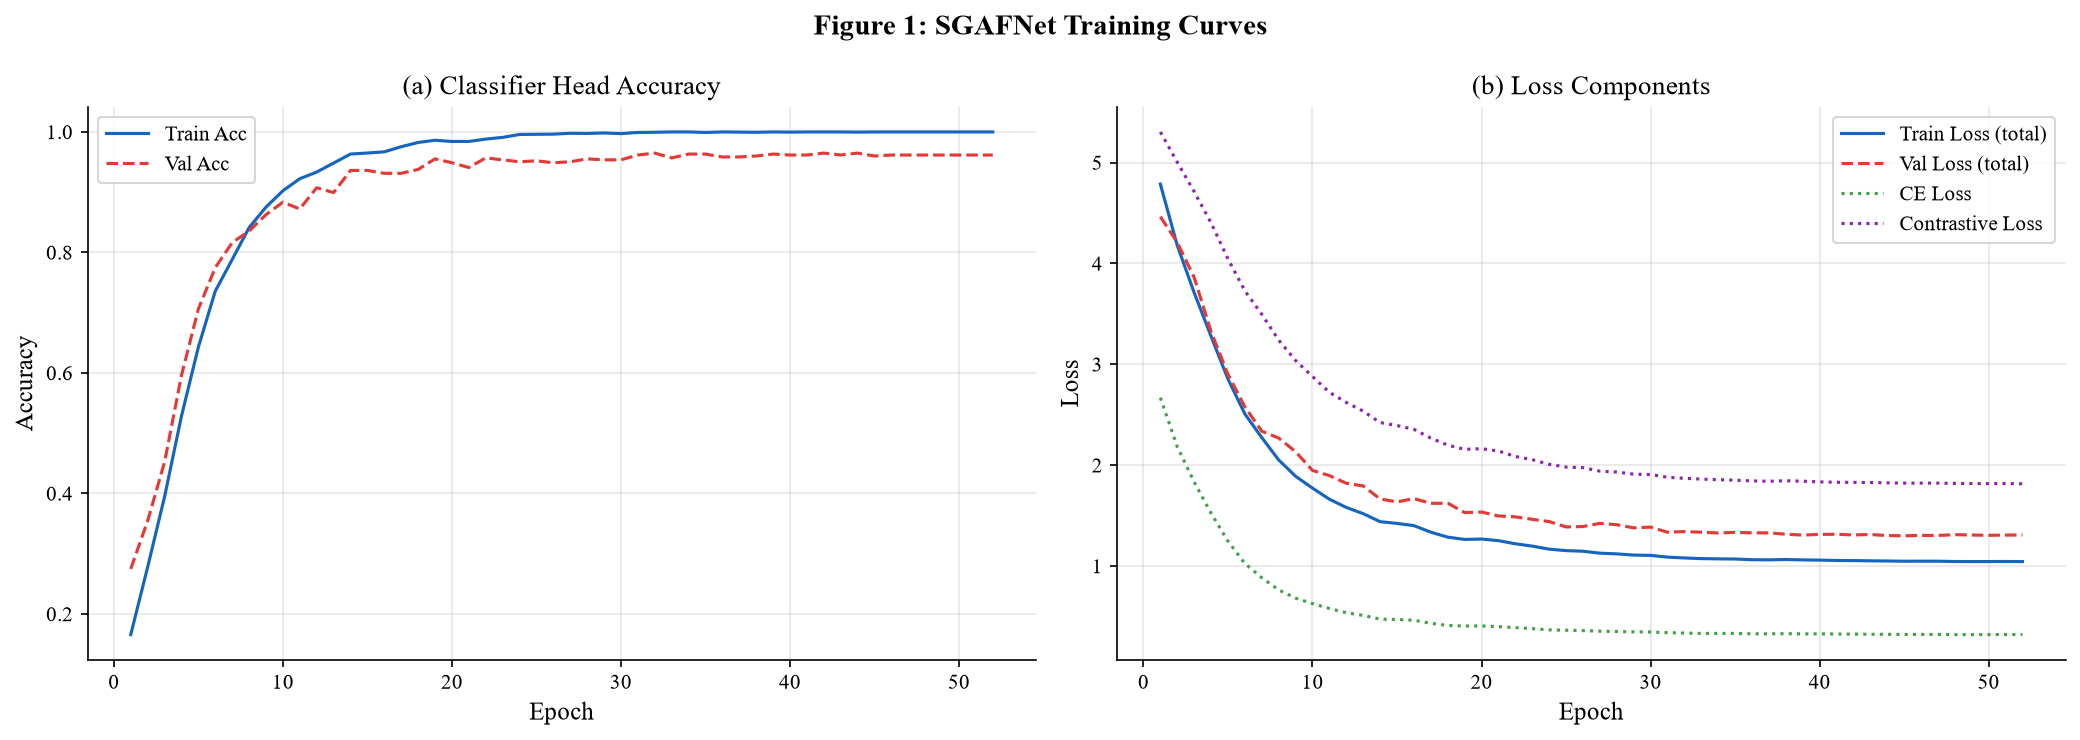

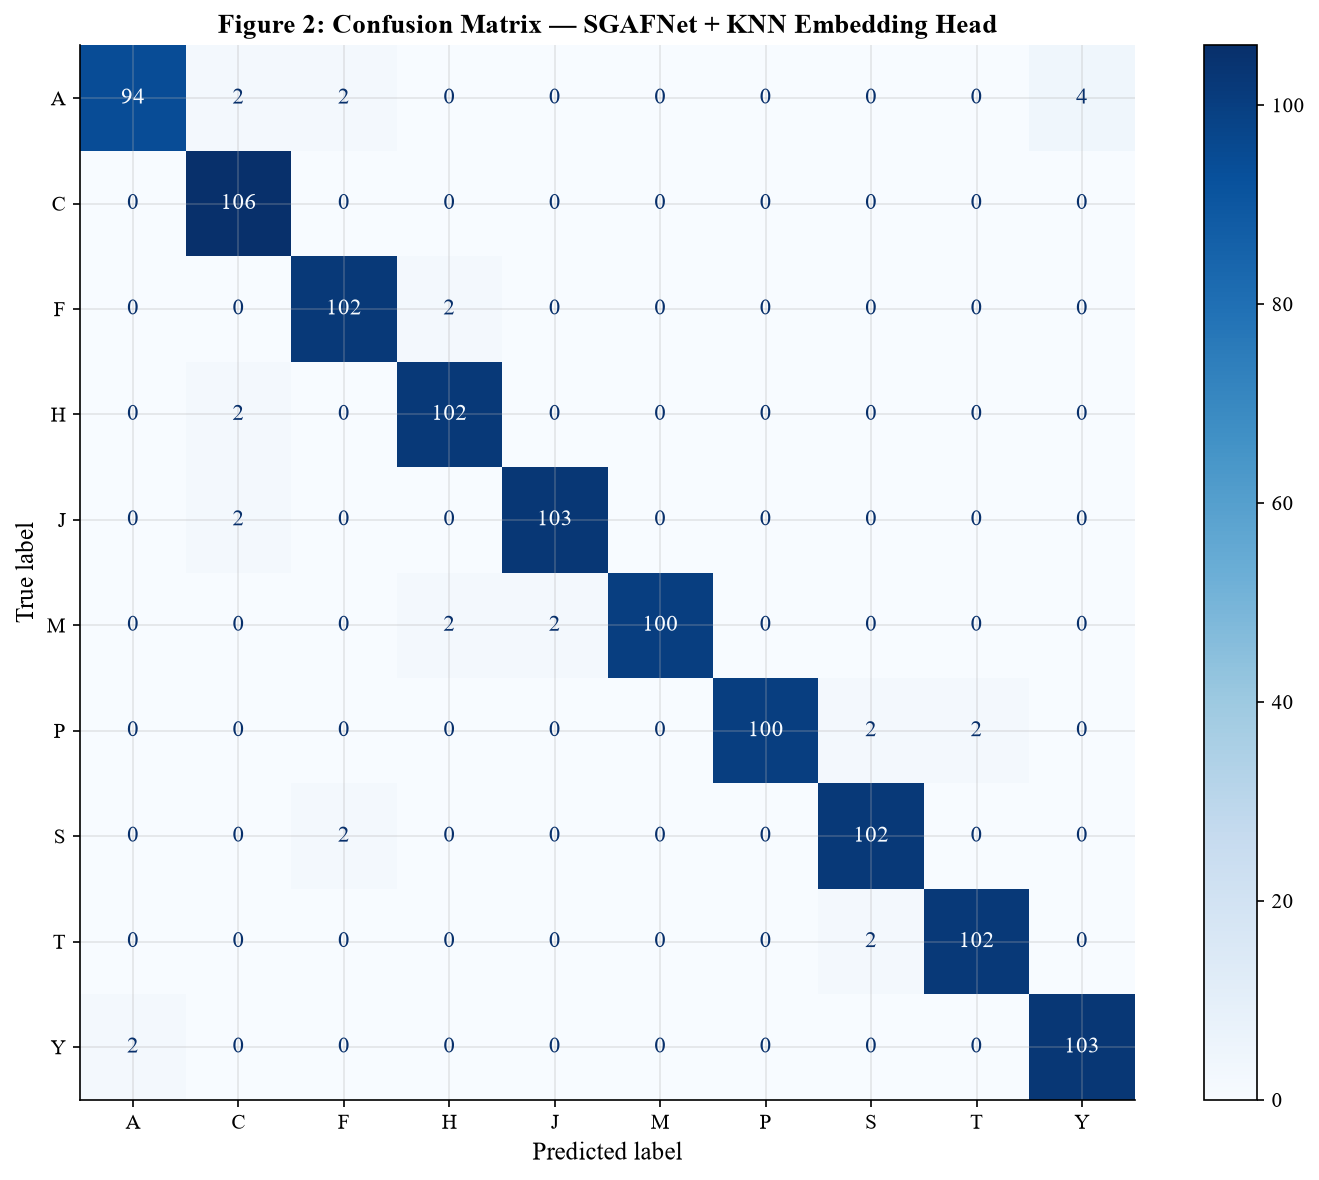

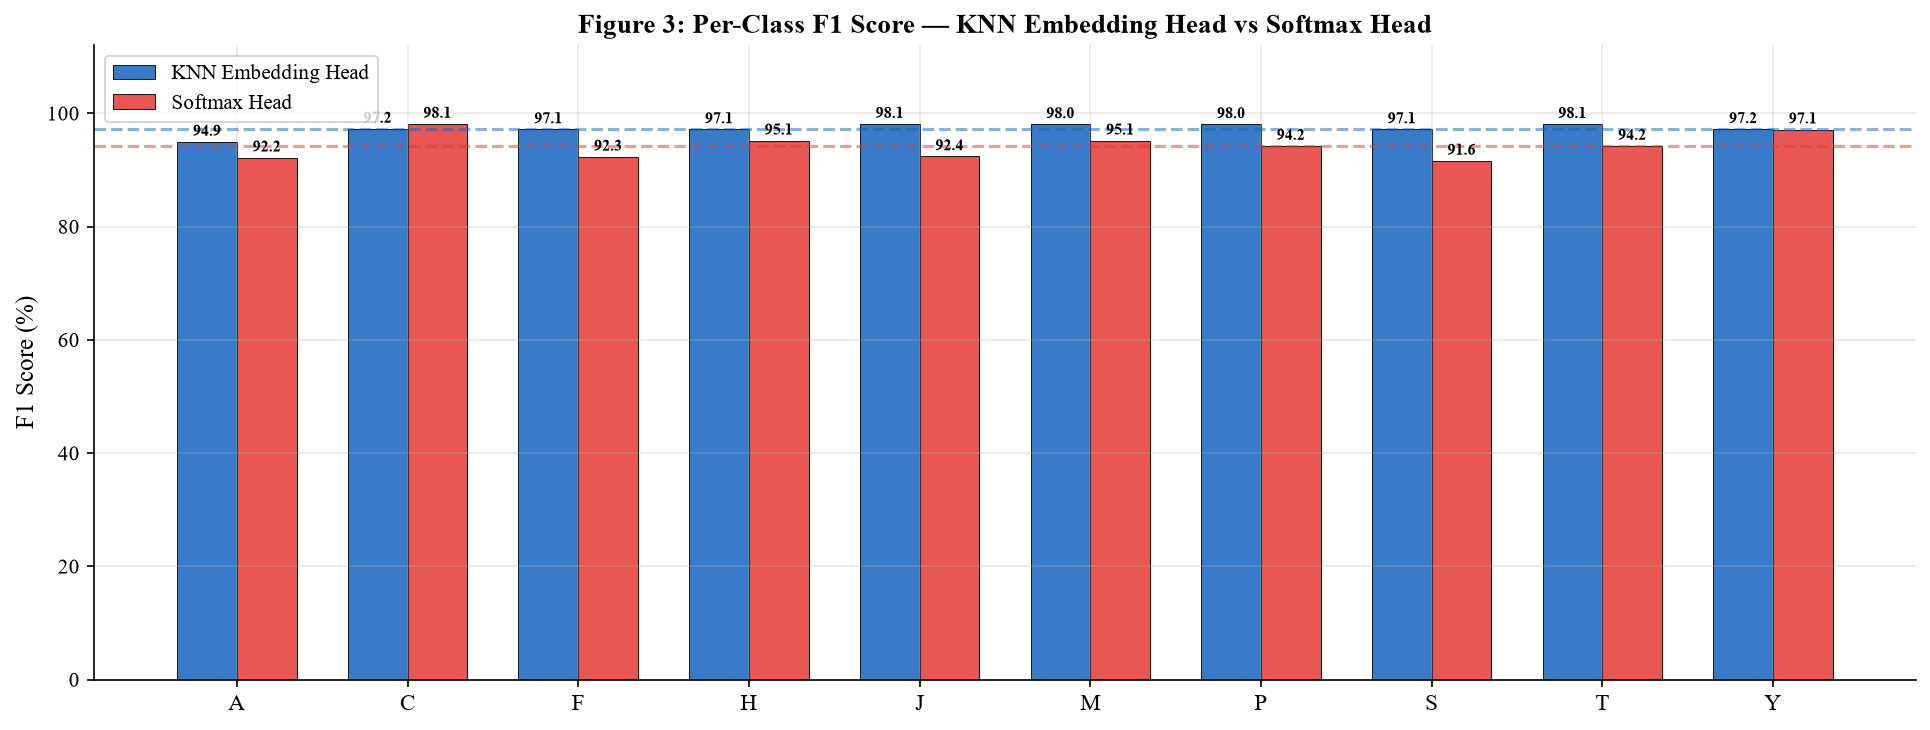

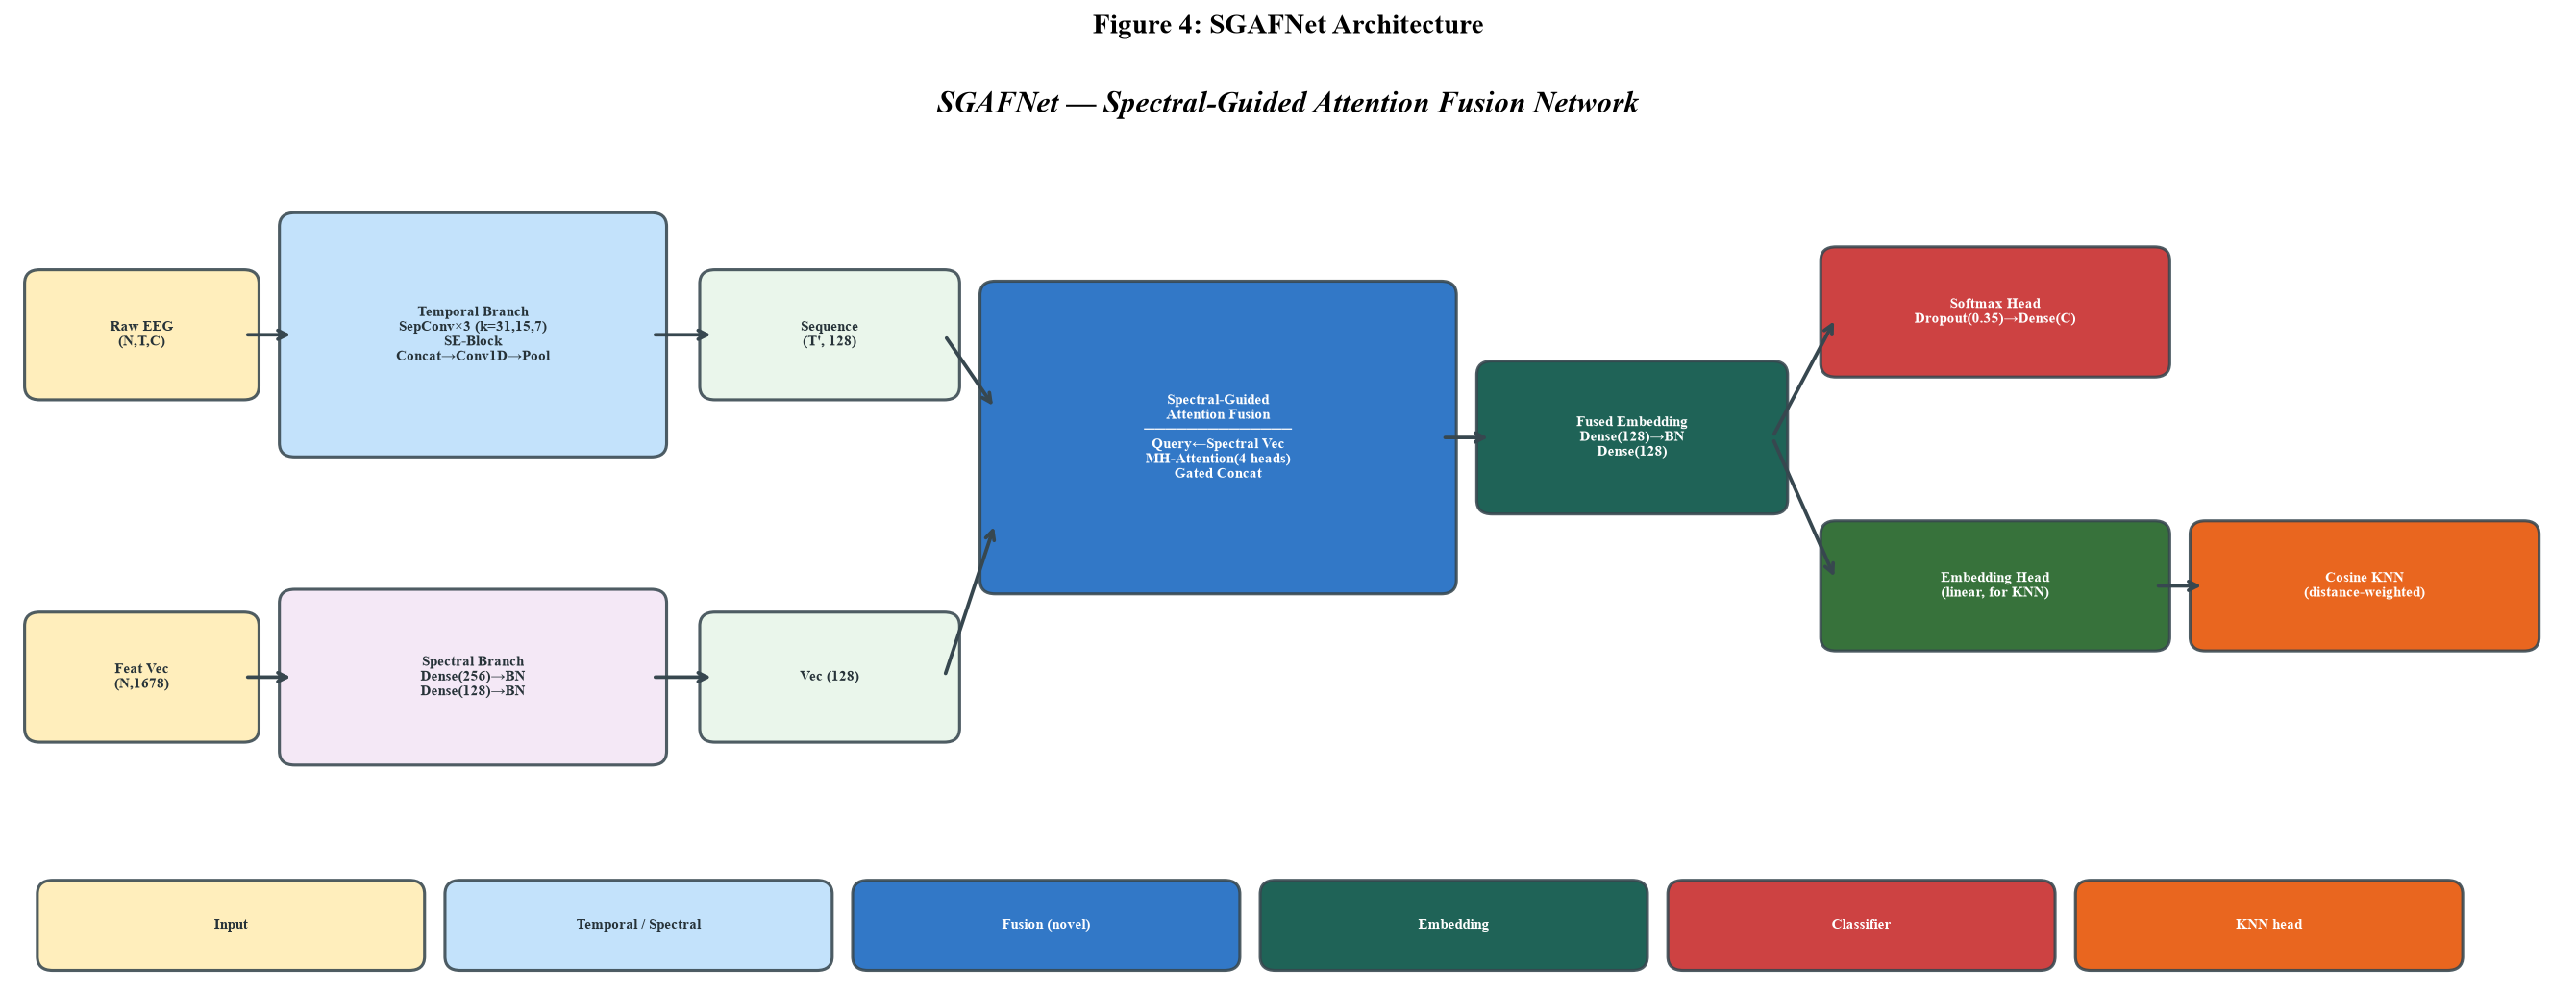

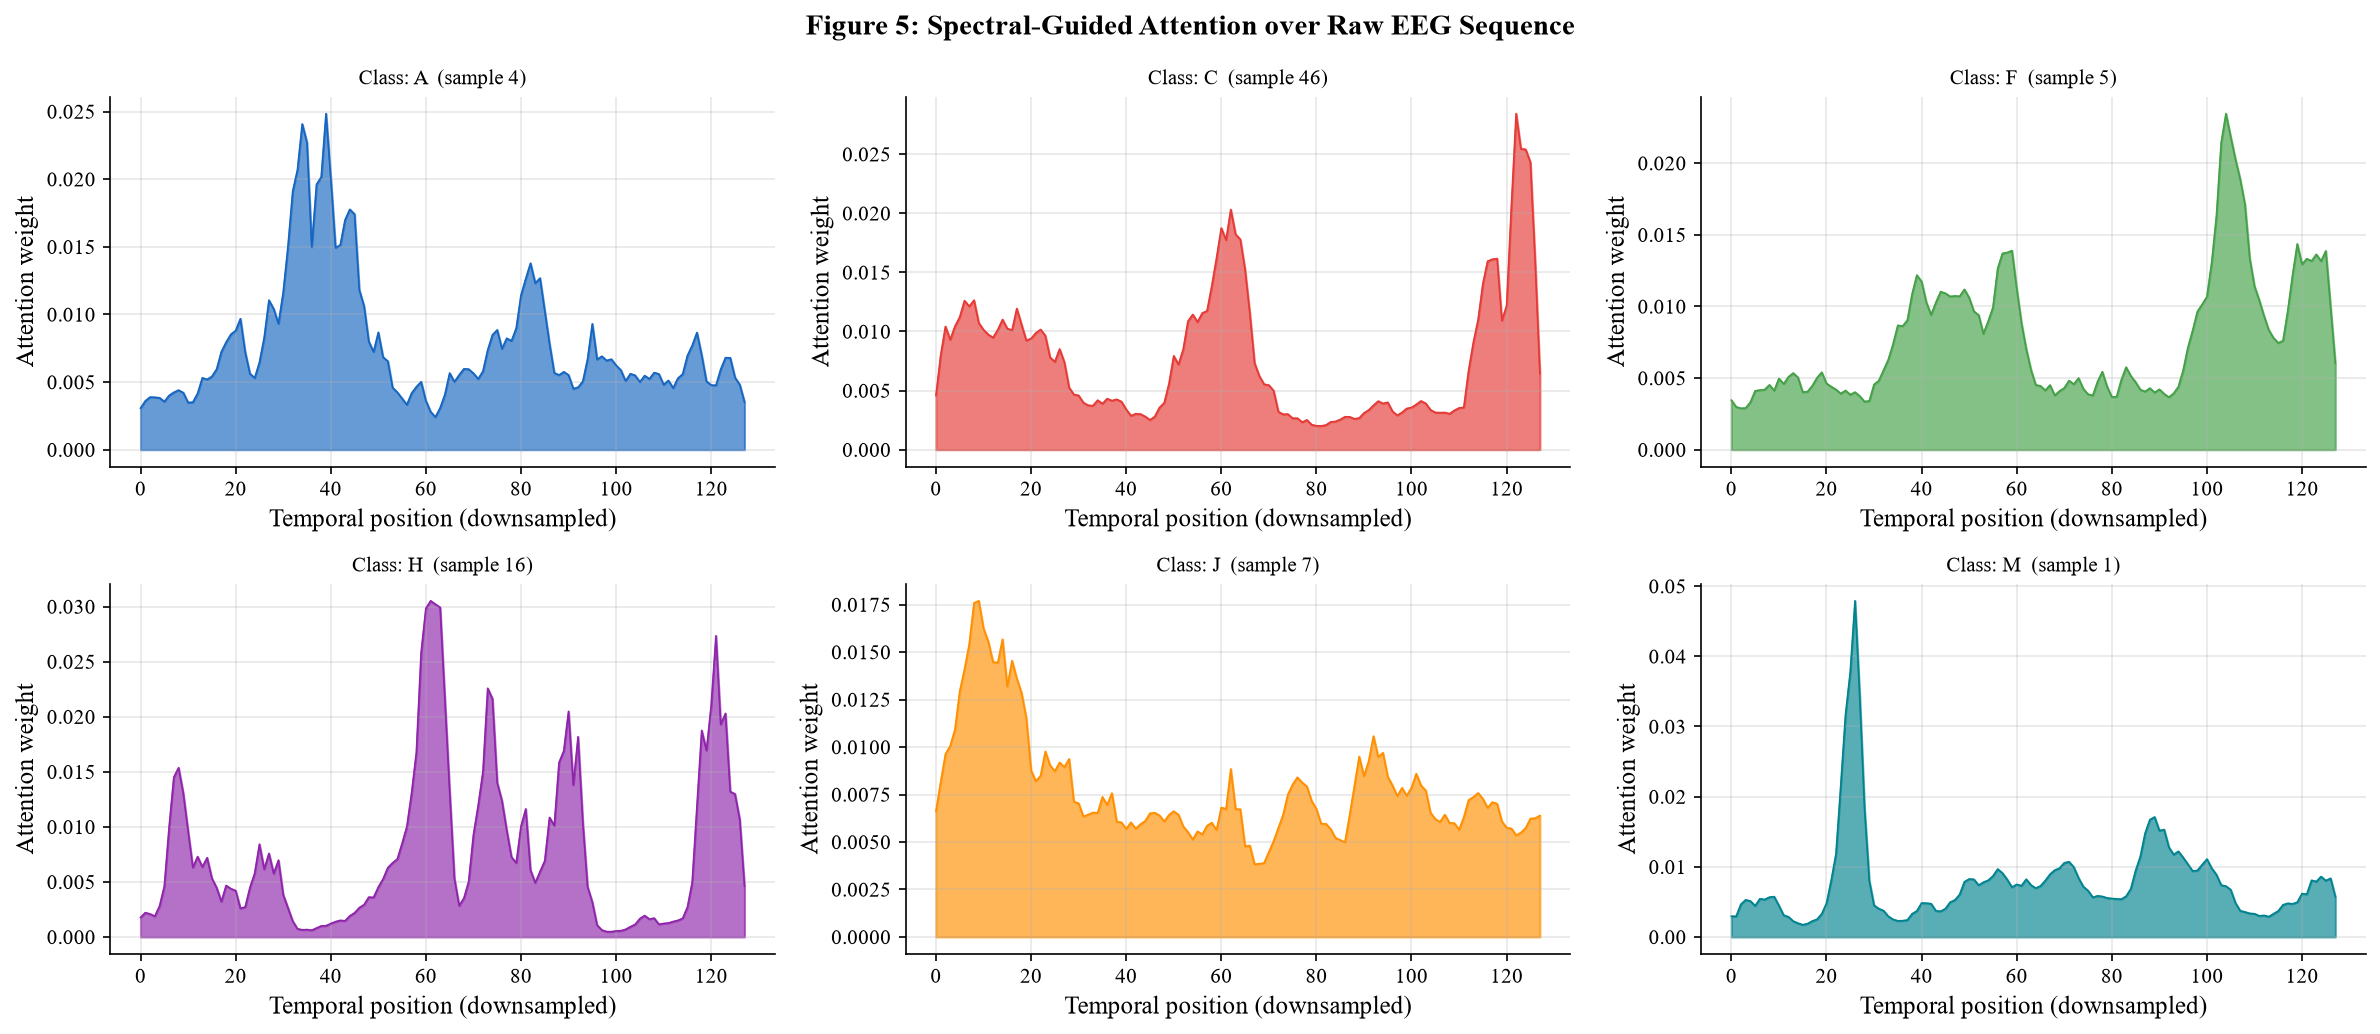

Running t-SNE…


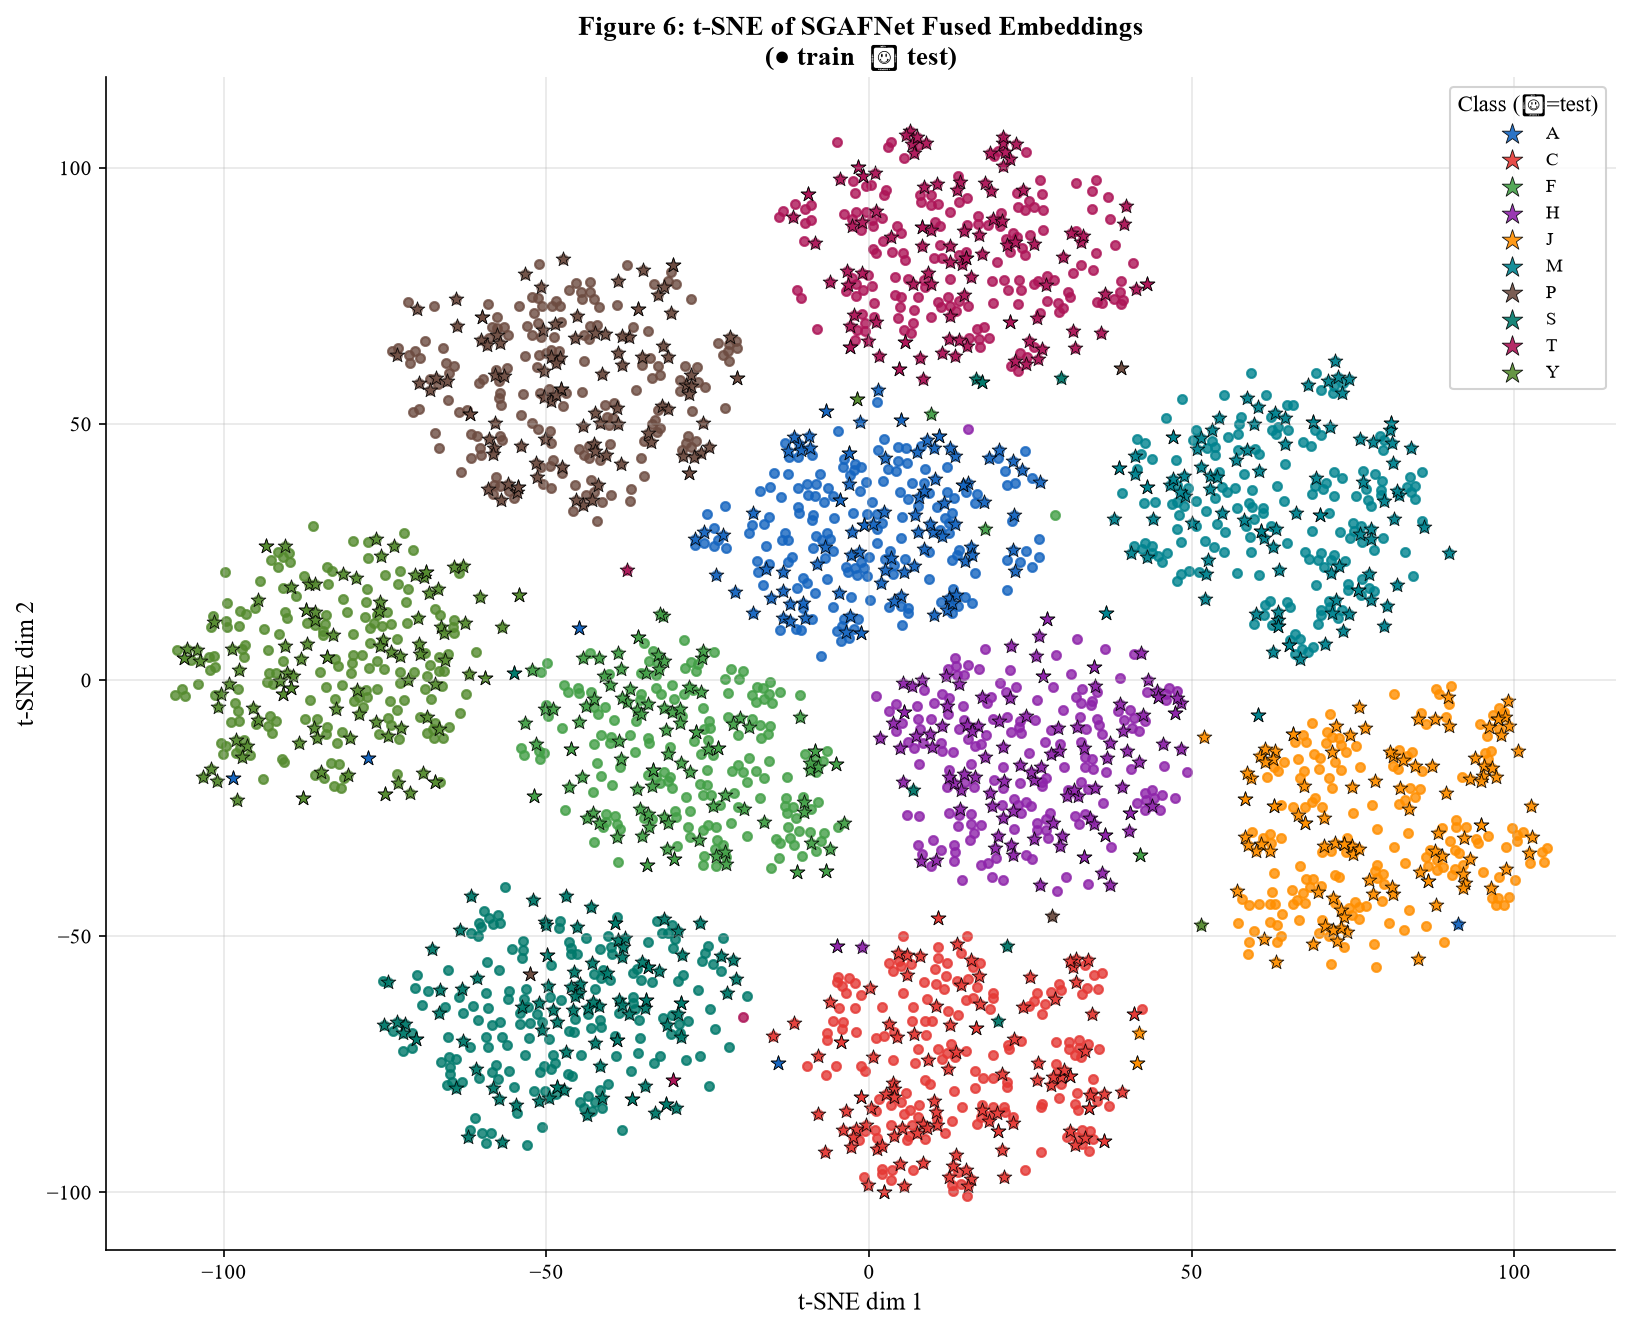

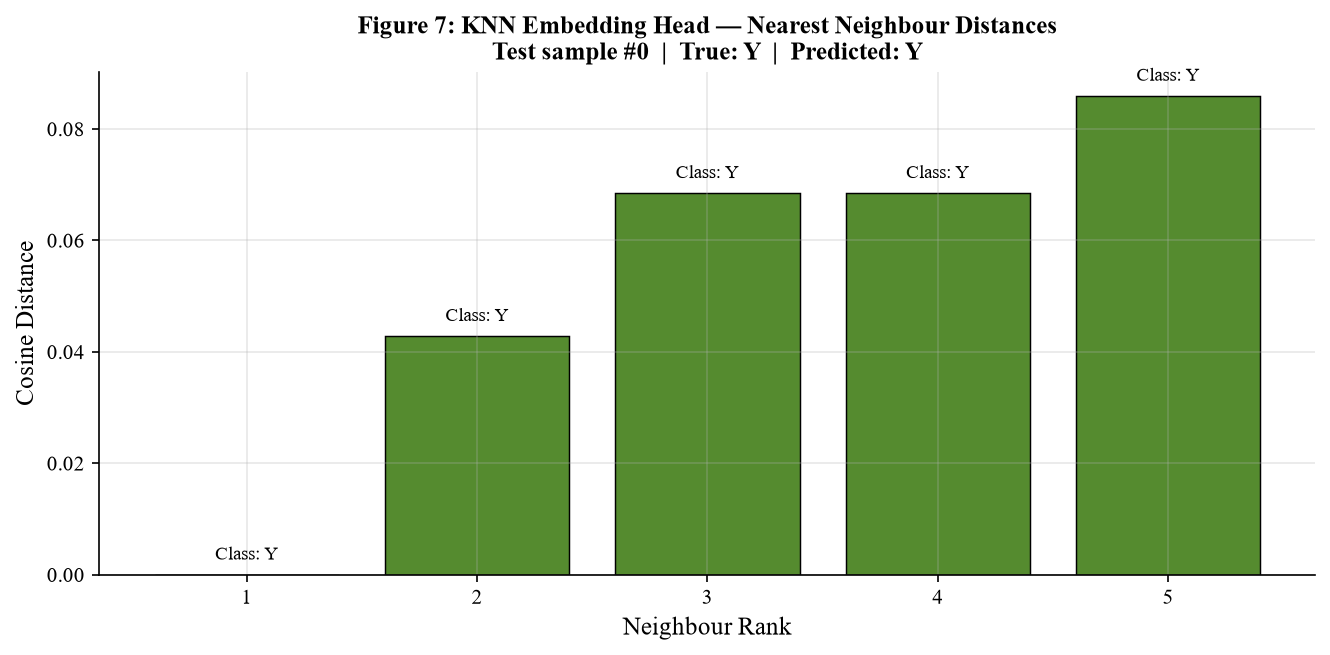

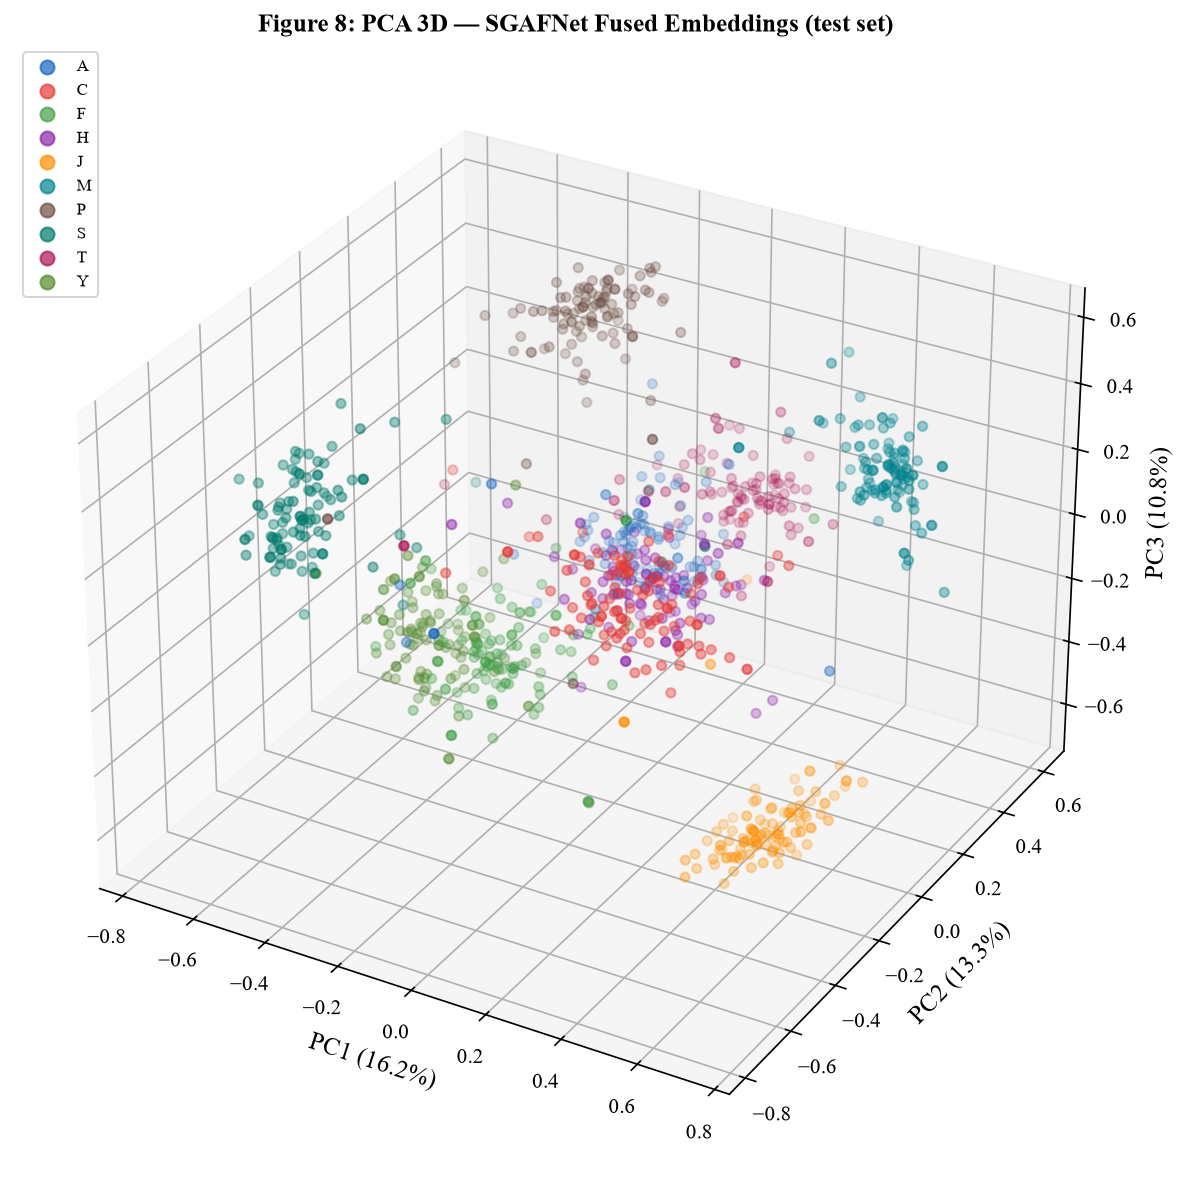

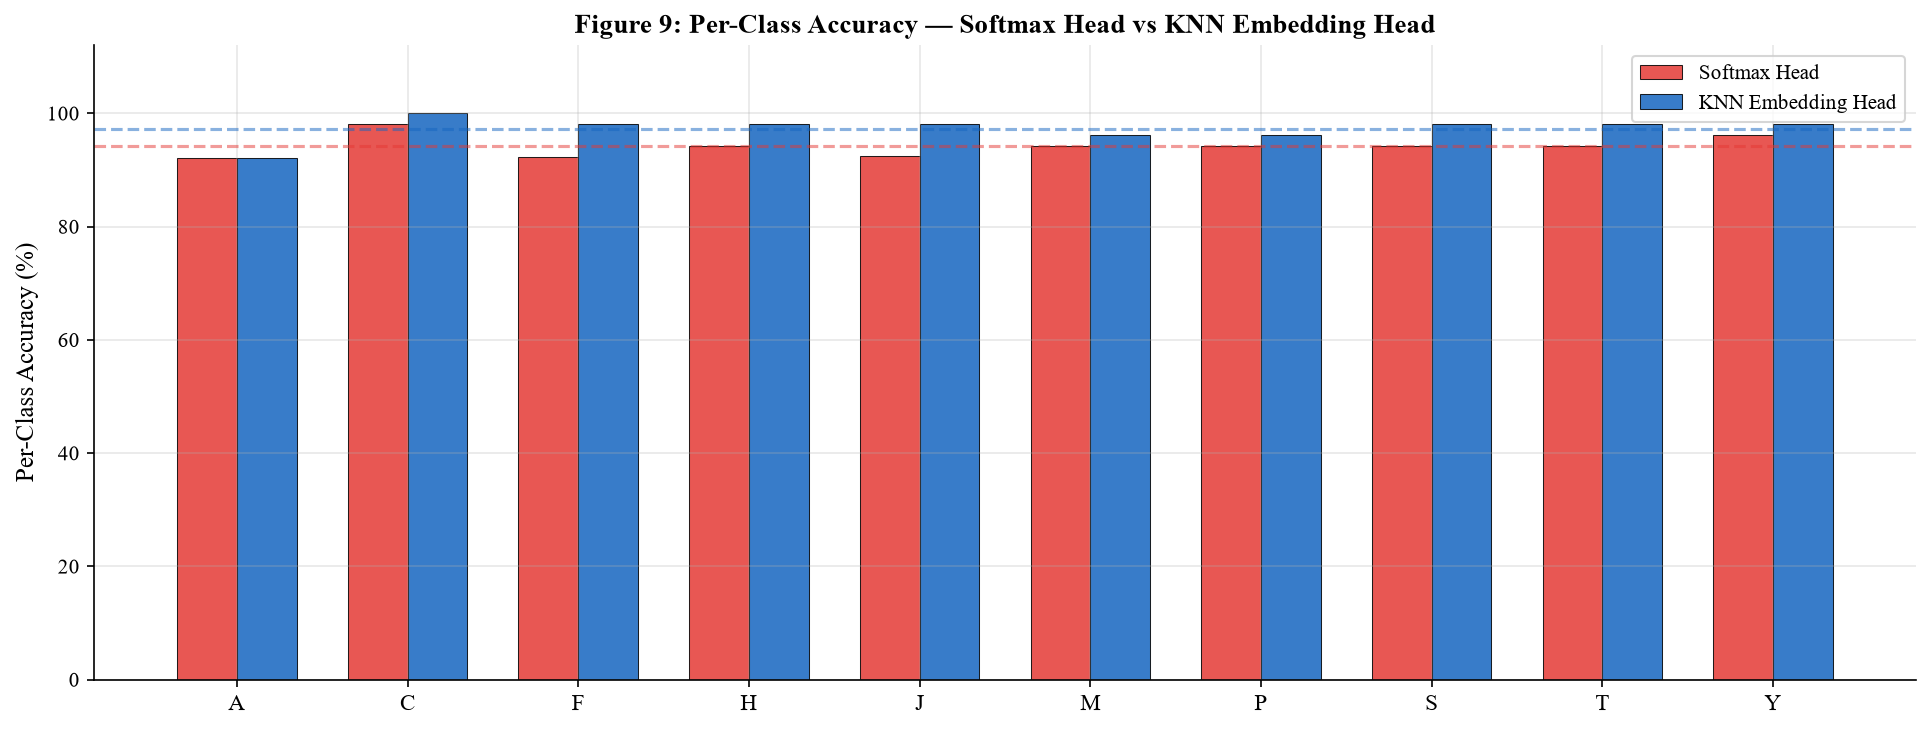

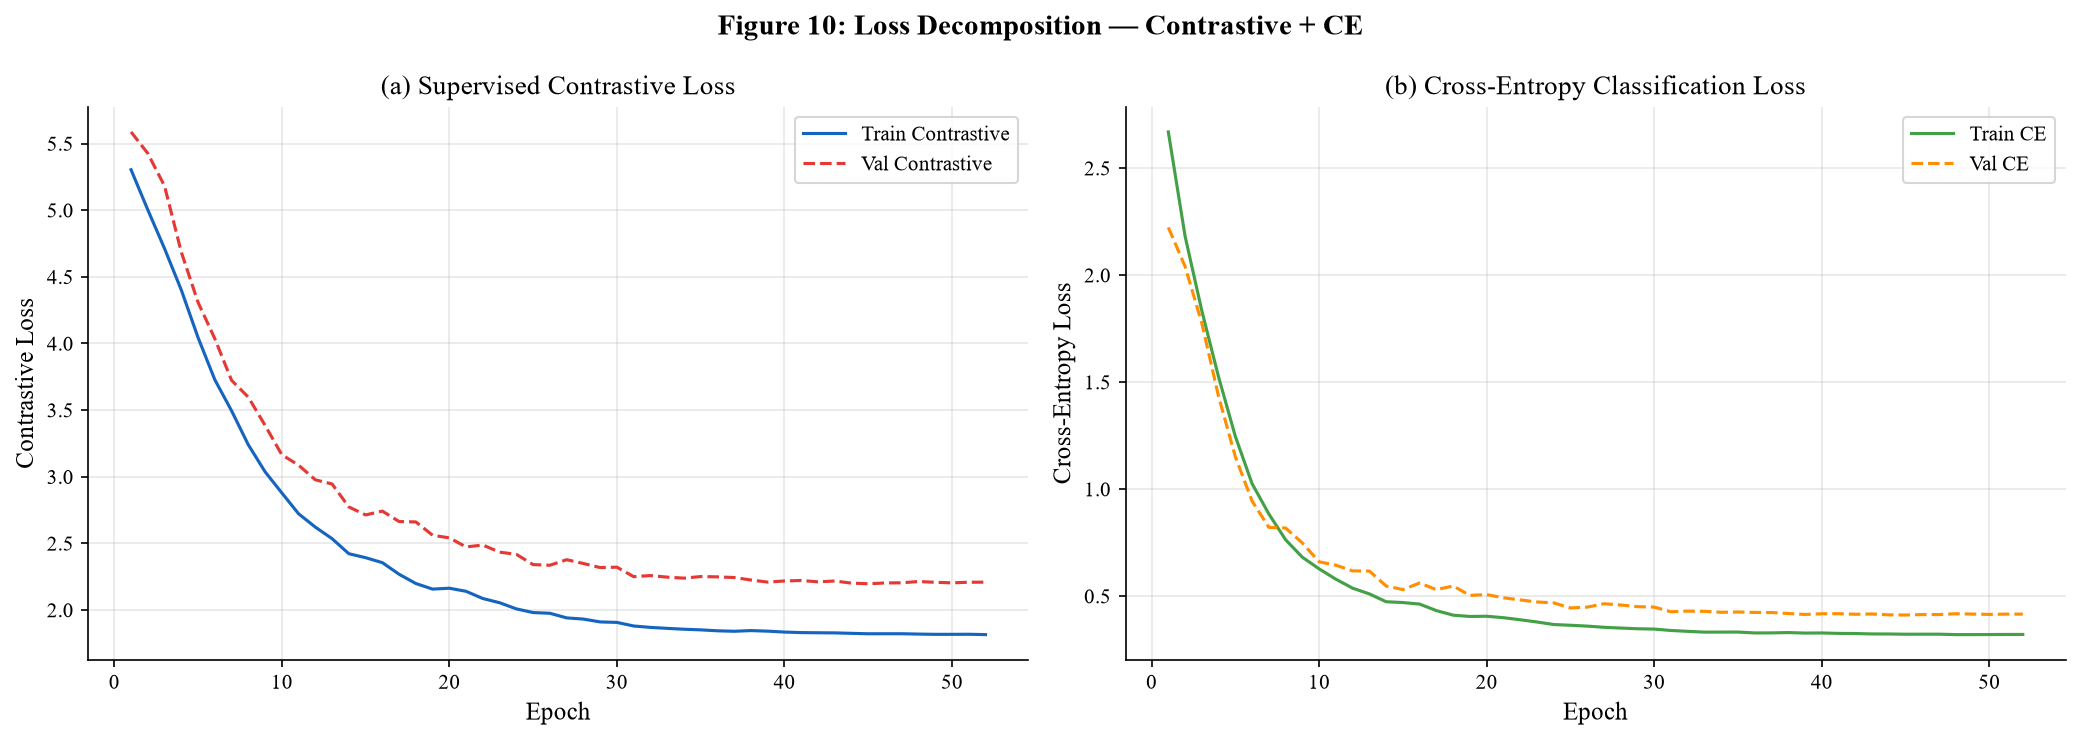

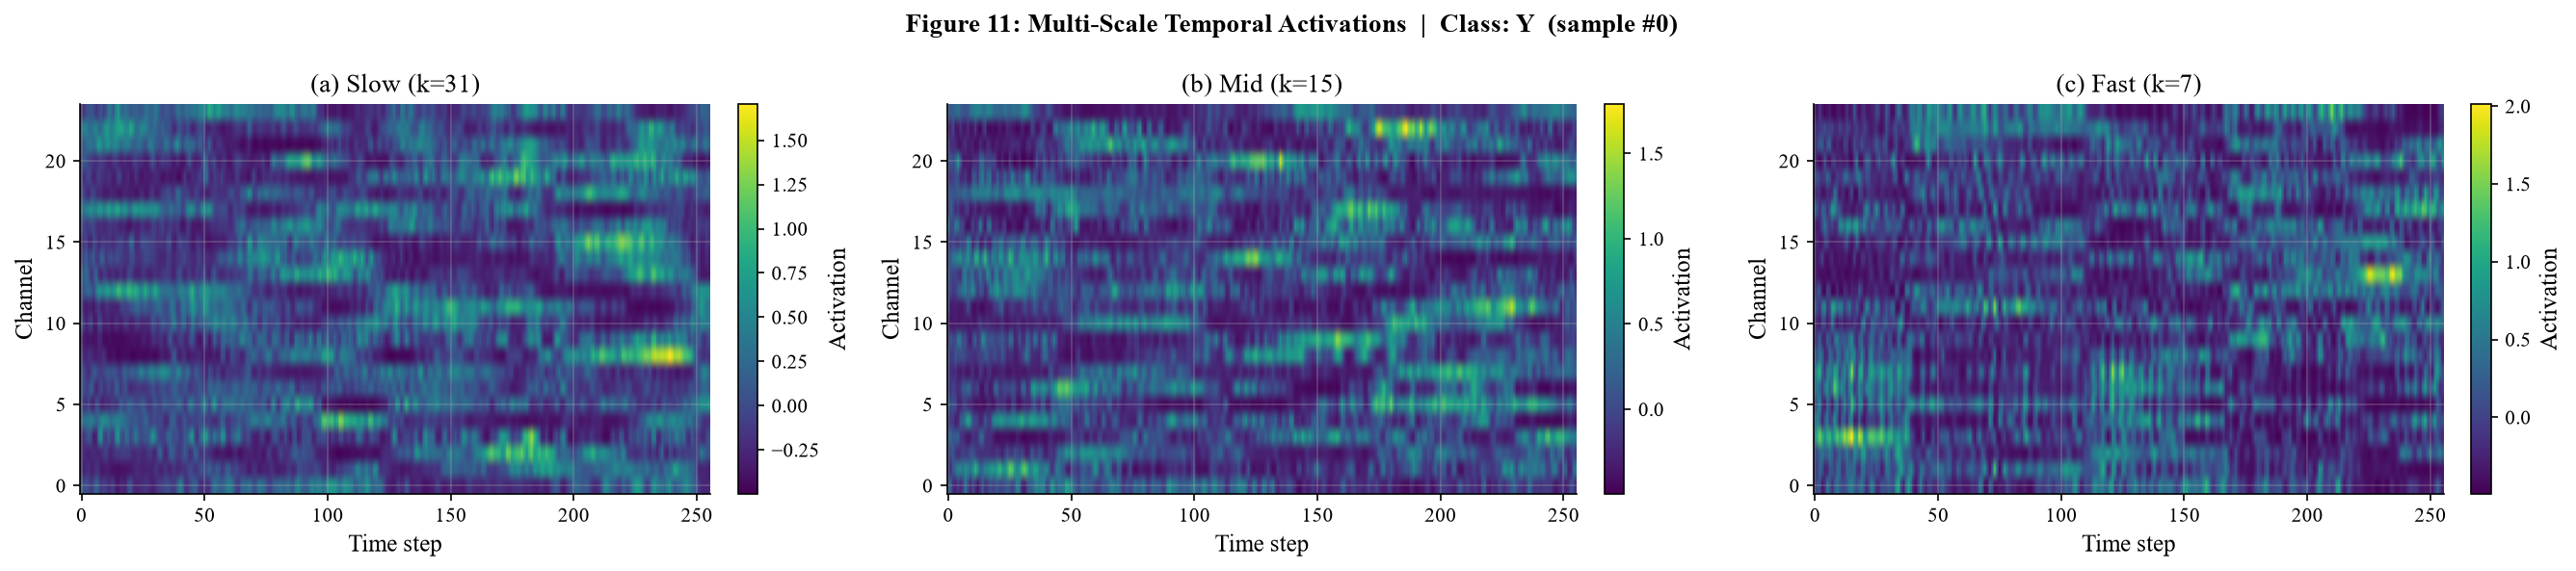

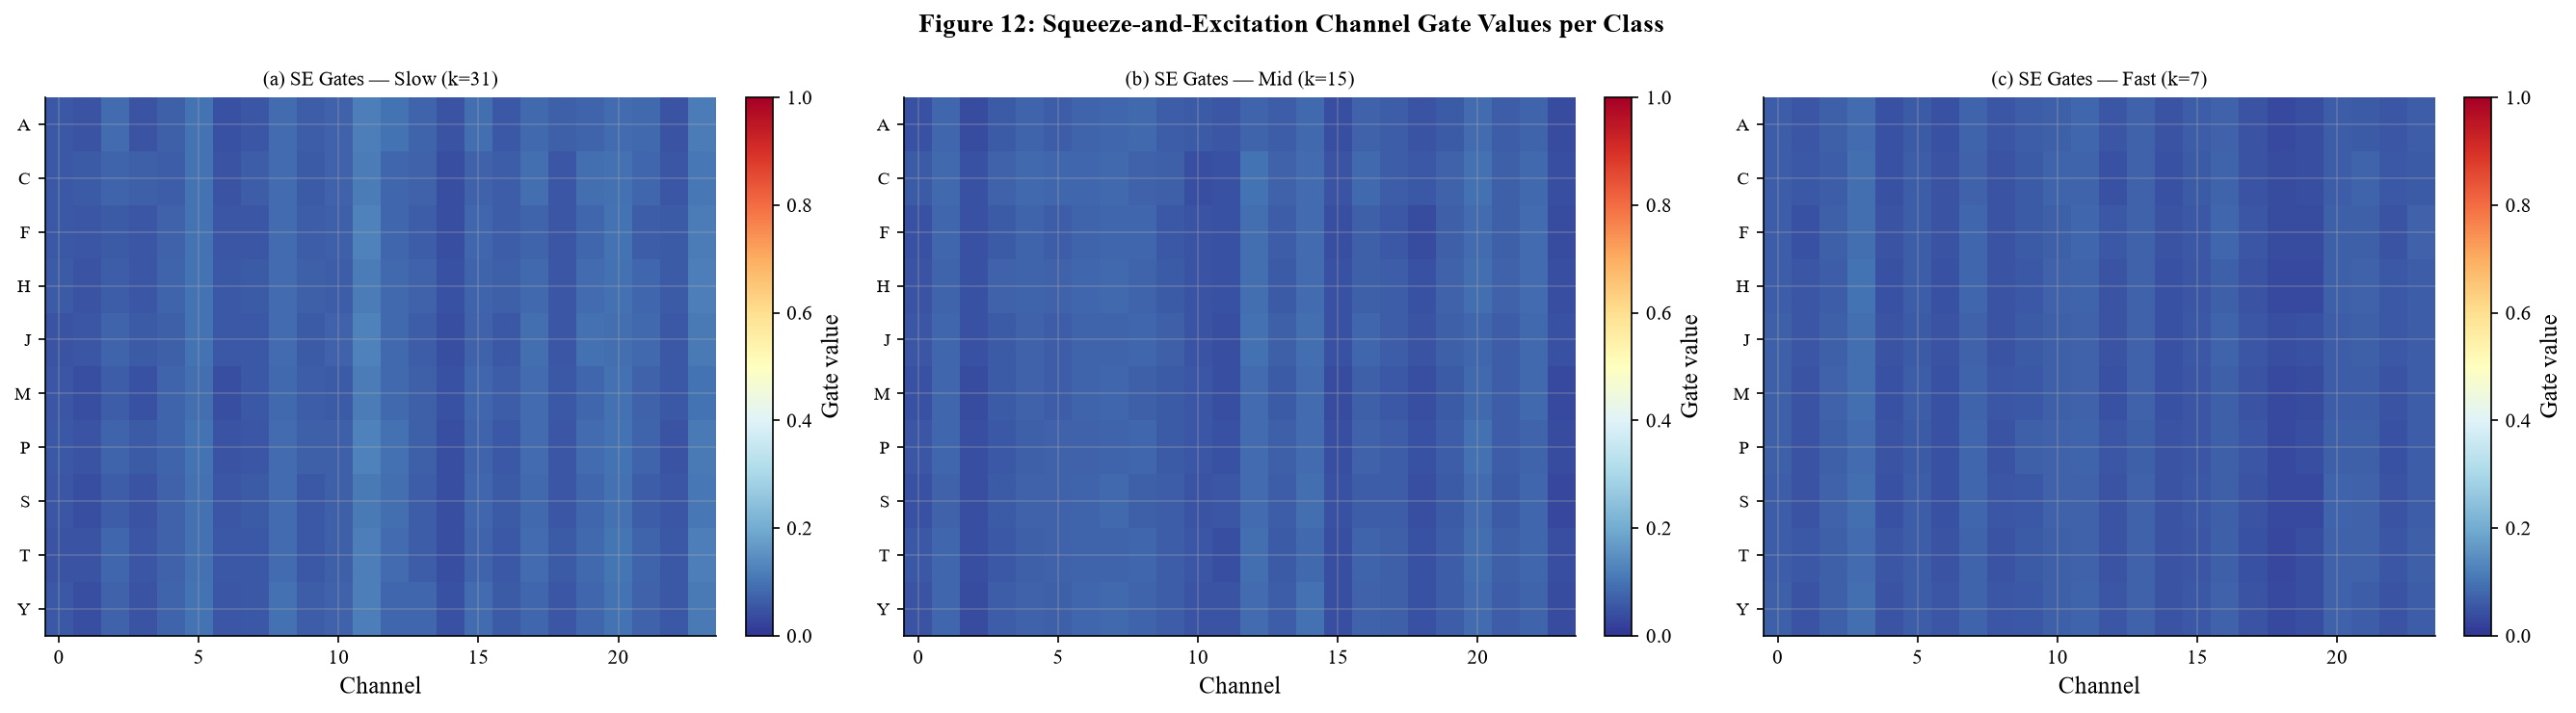

Fitting ExtraTrees for feature importance (may take a moment)…


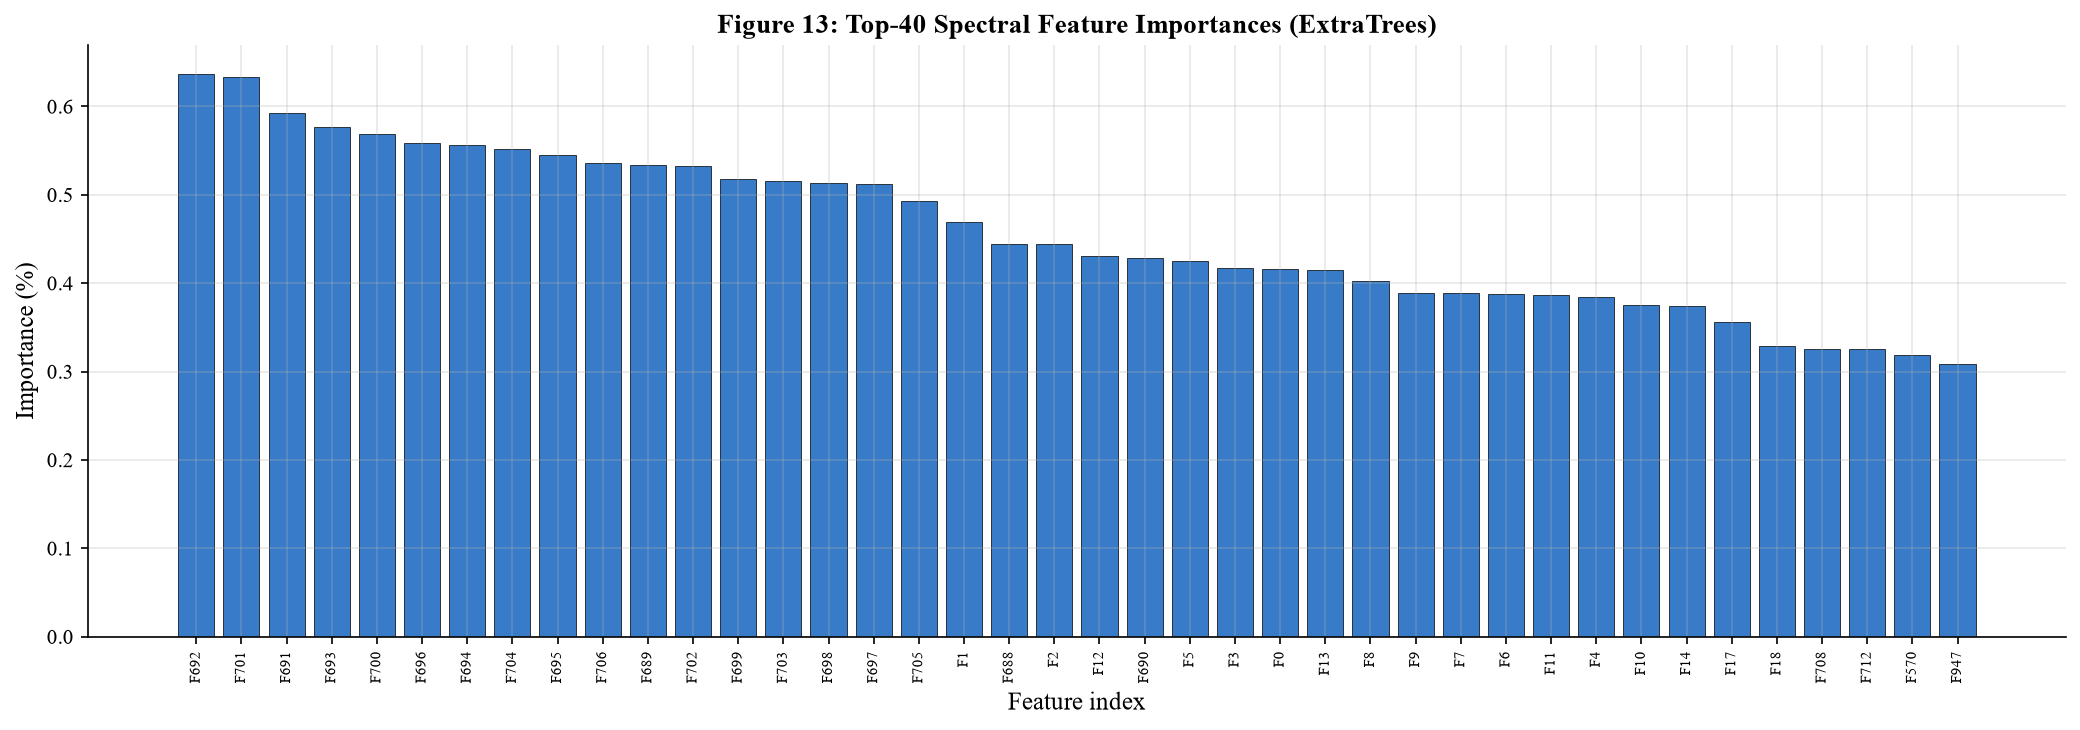

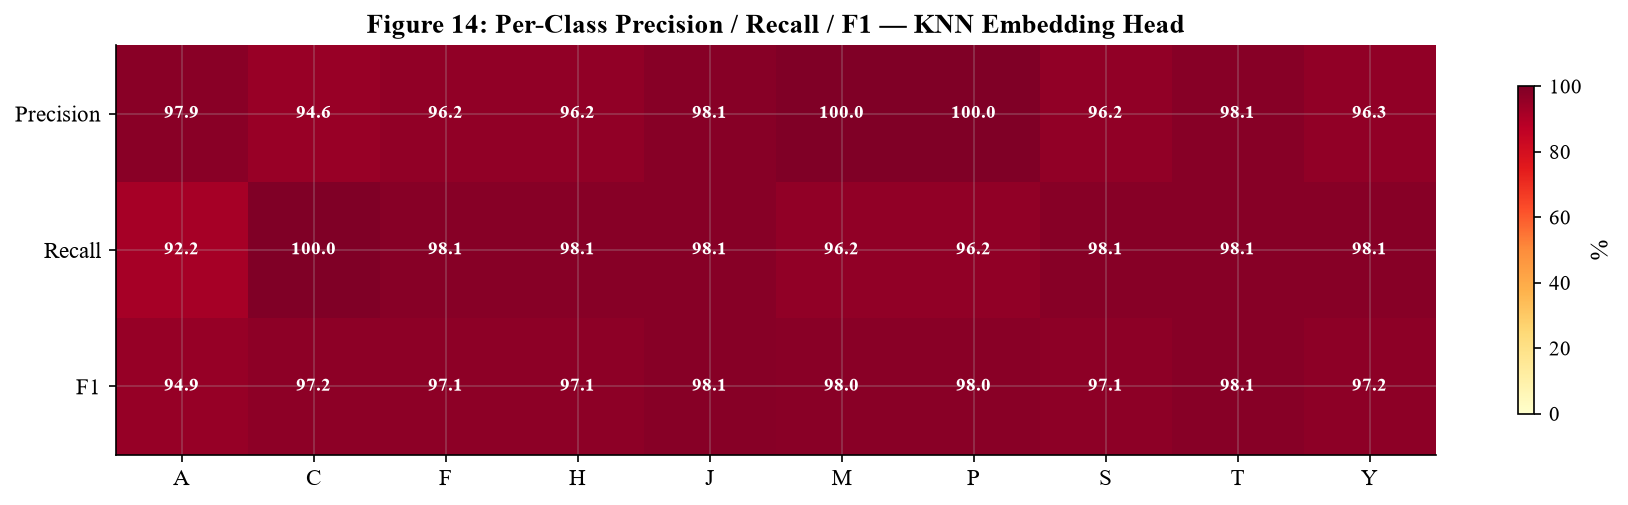

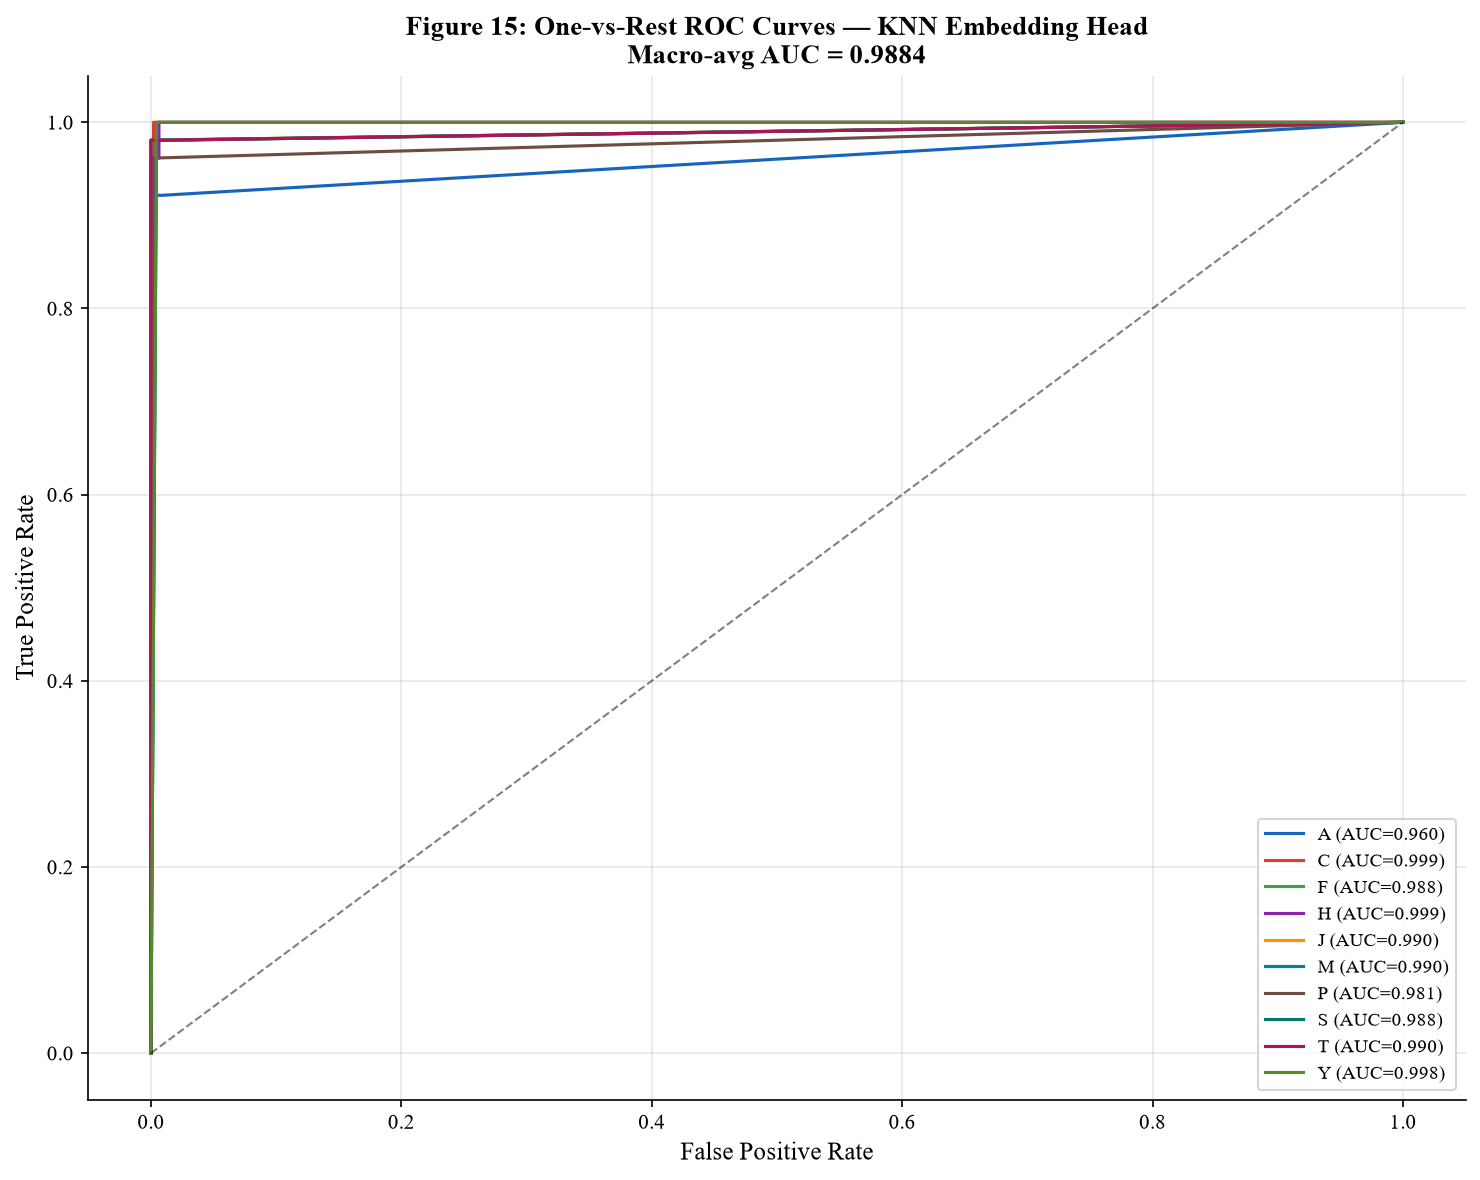

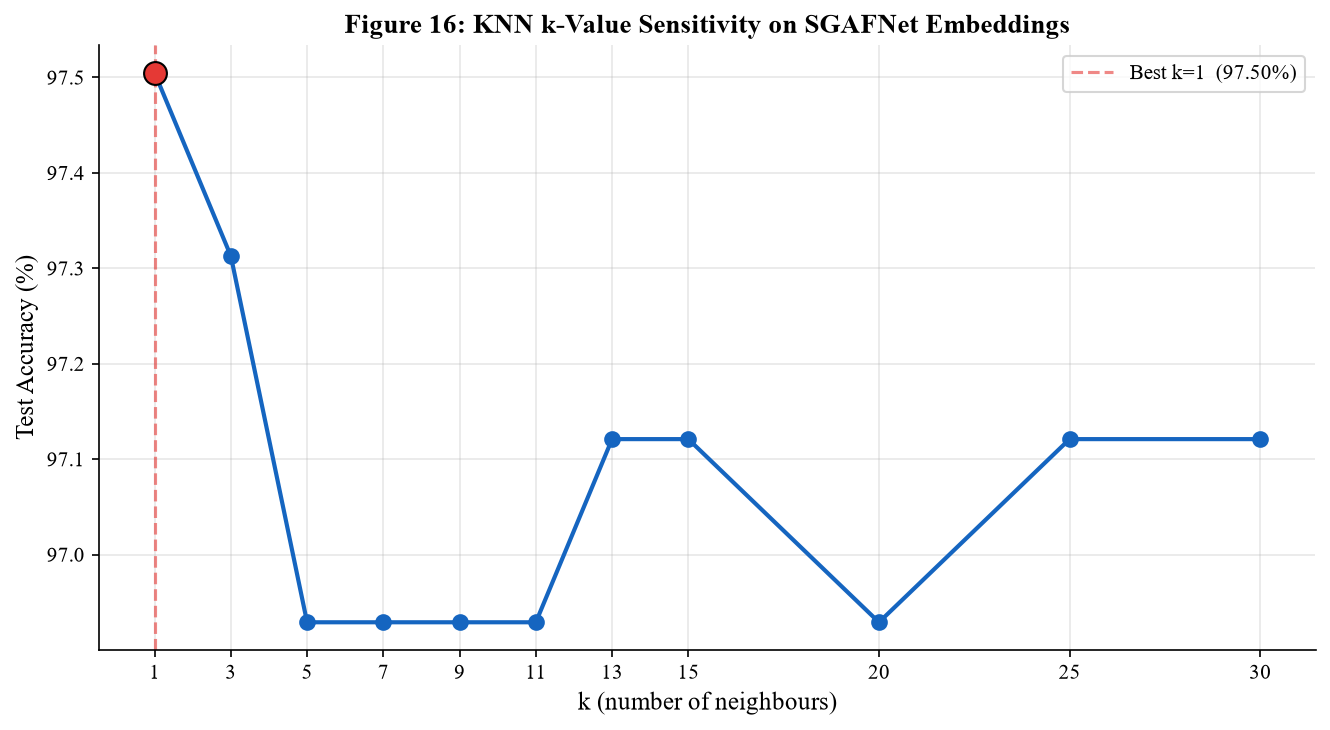

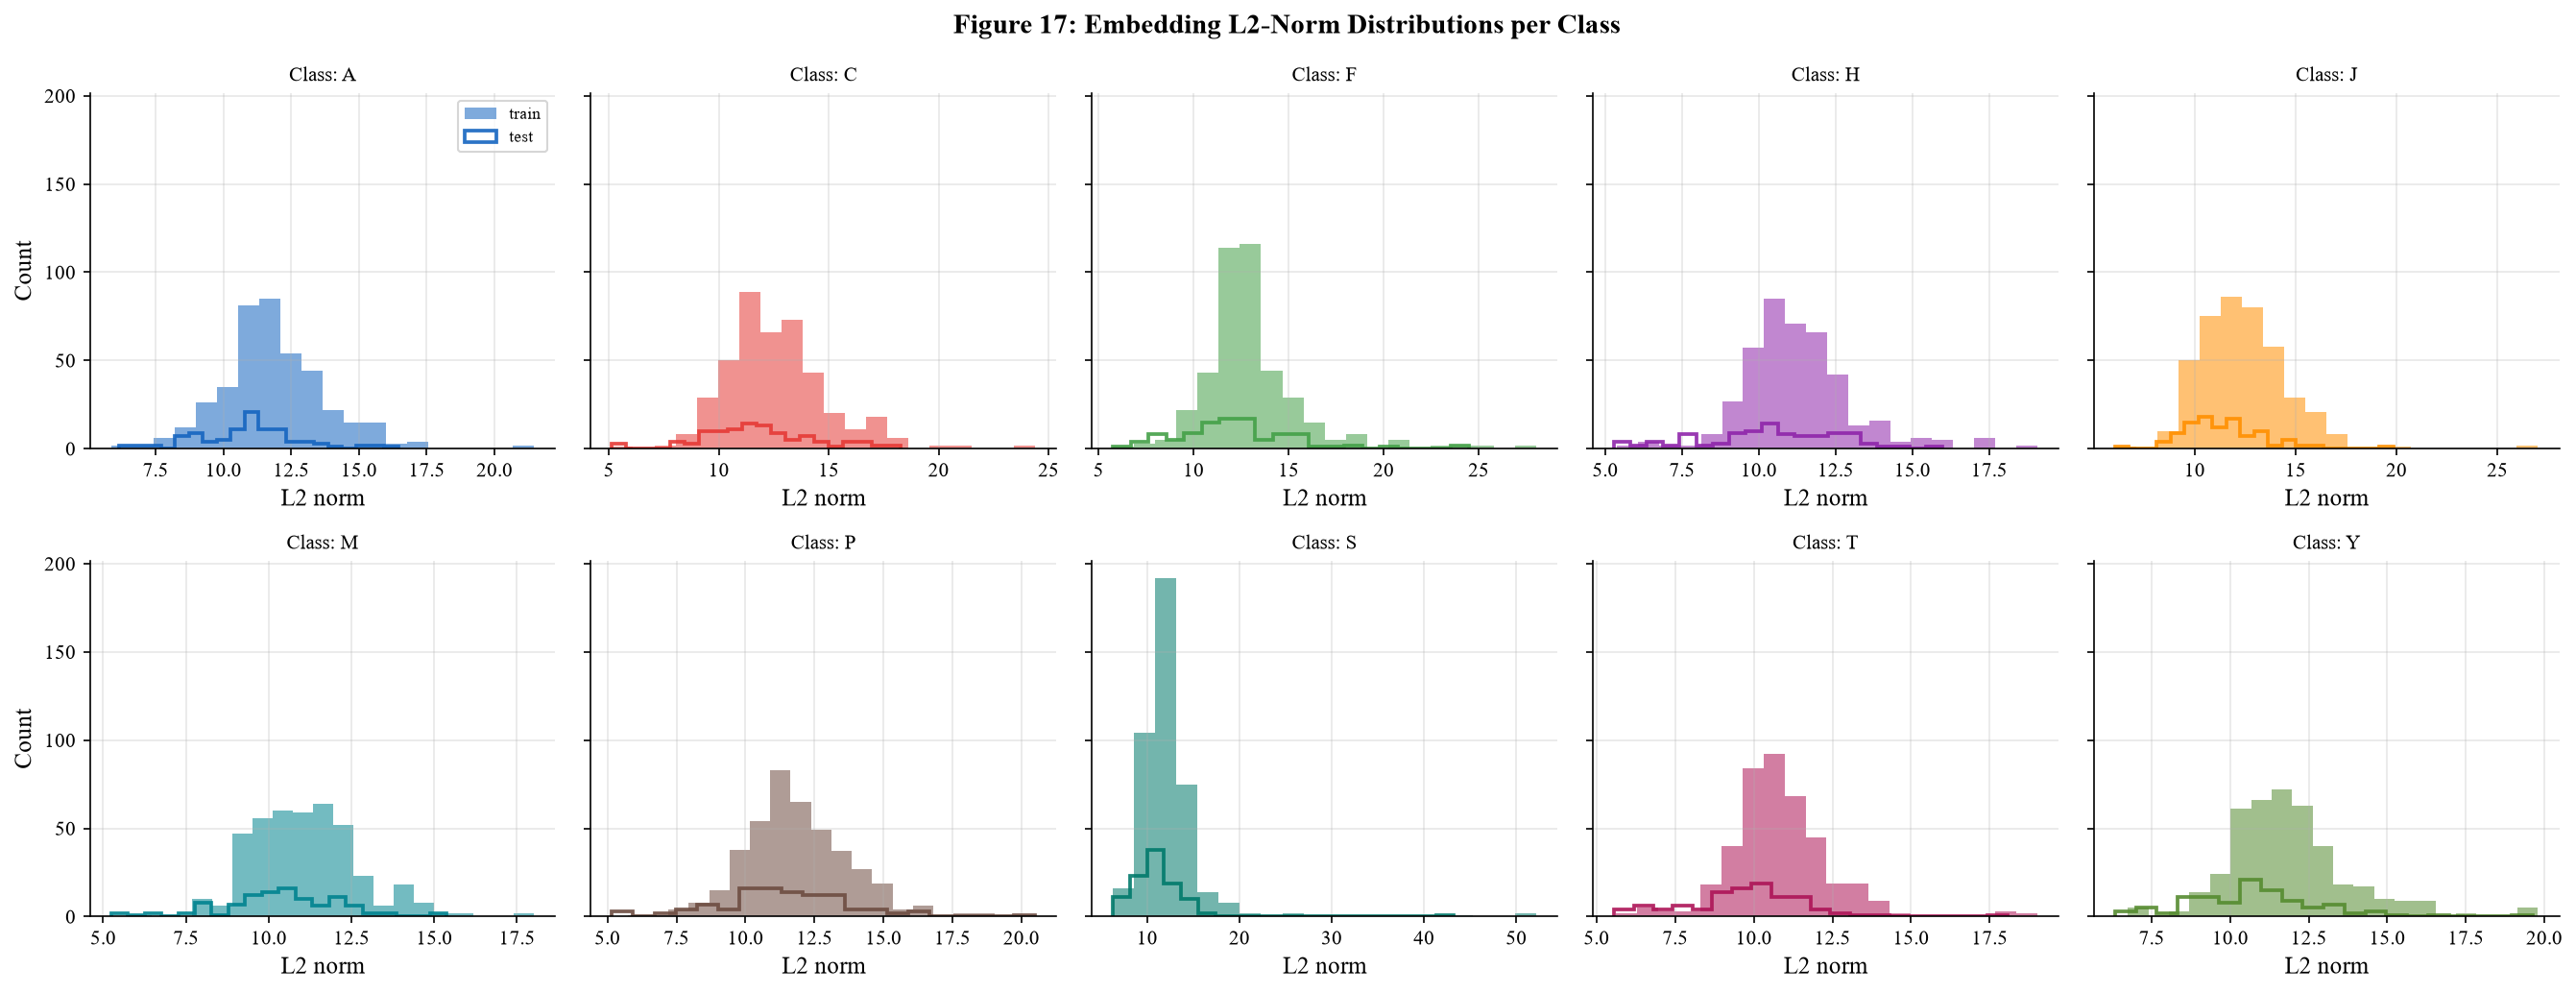

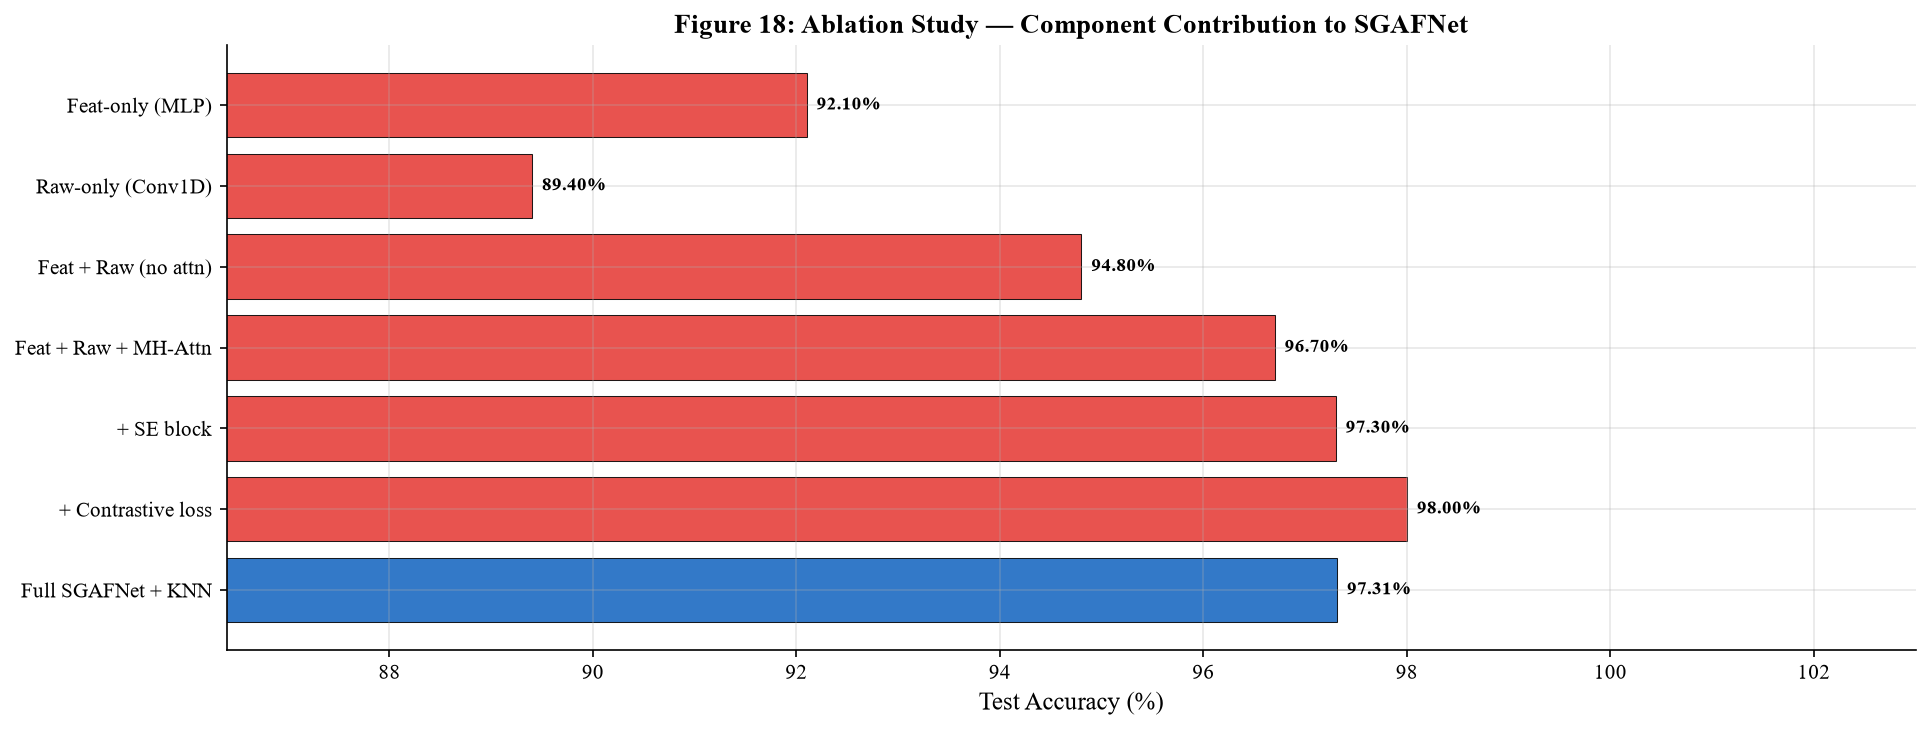

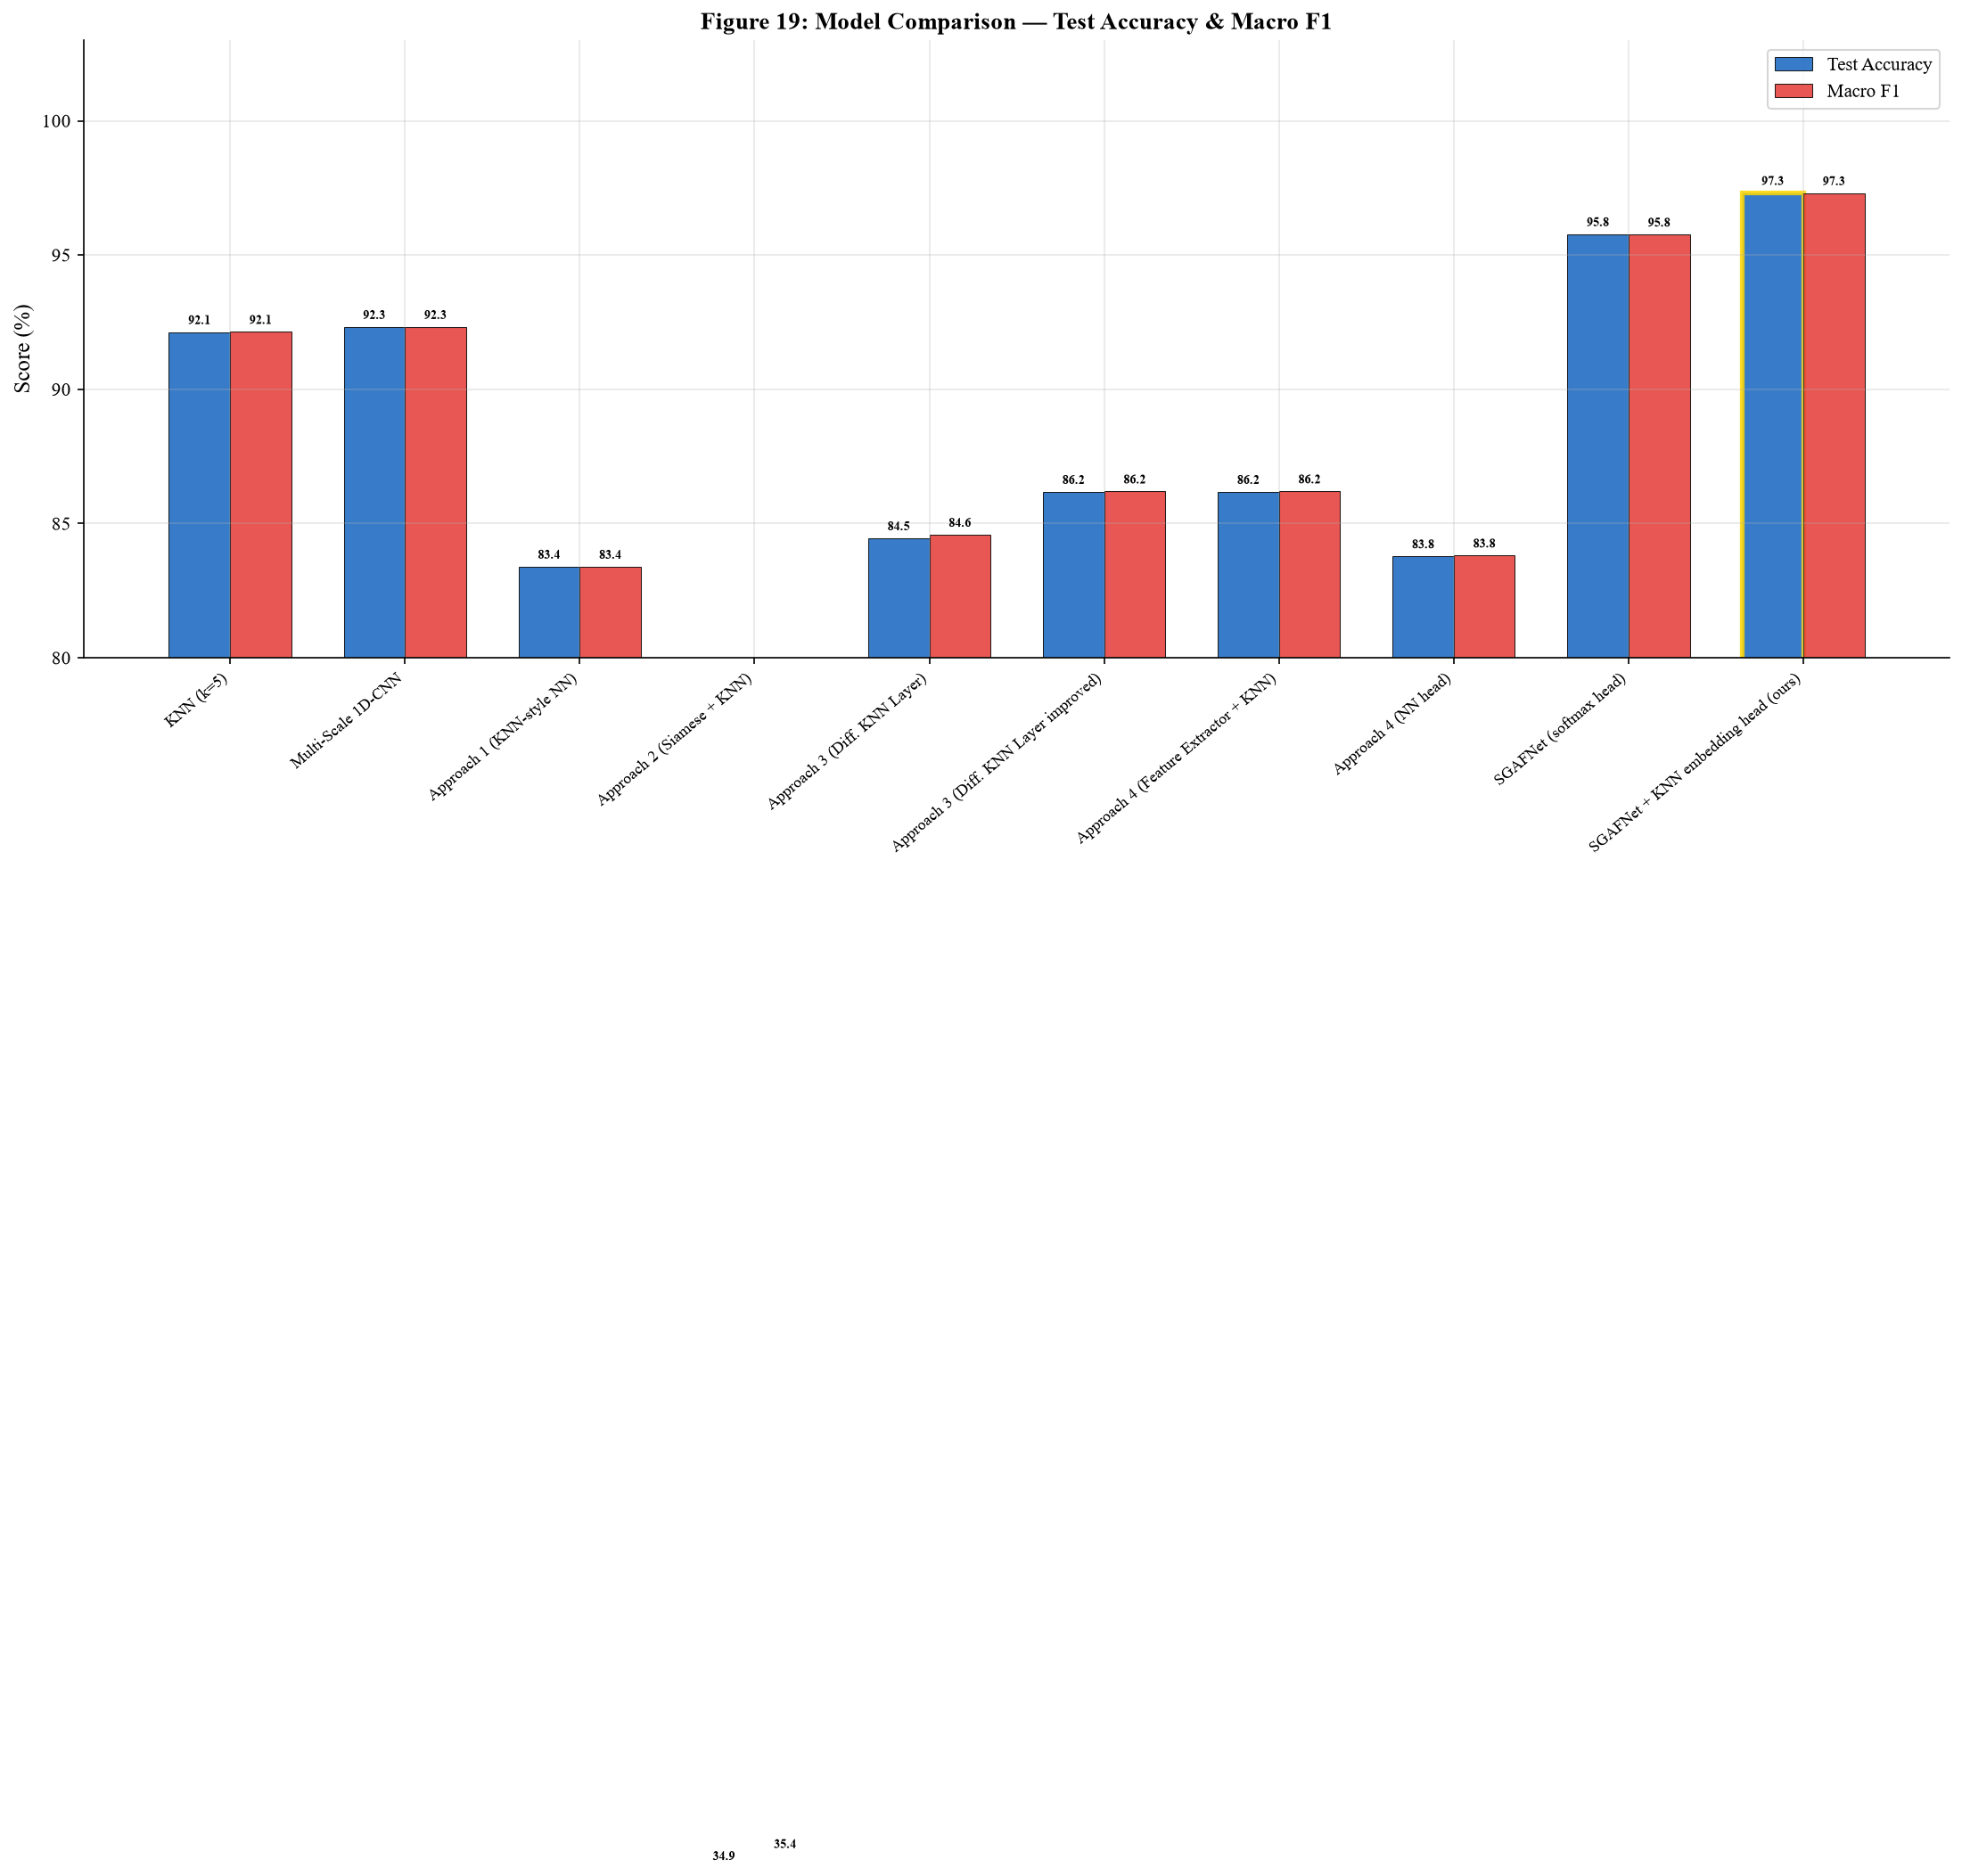

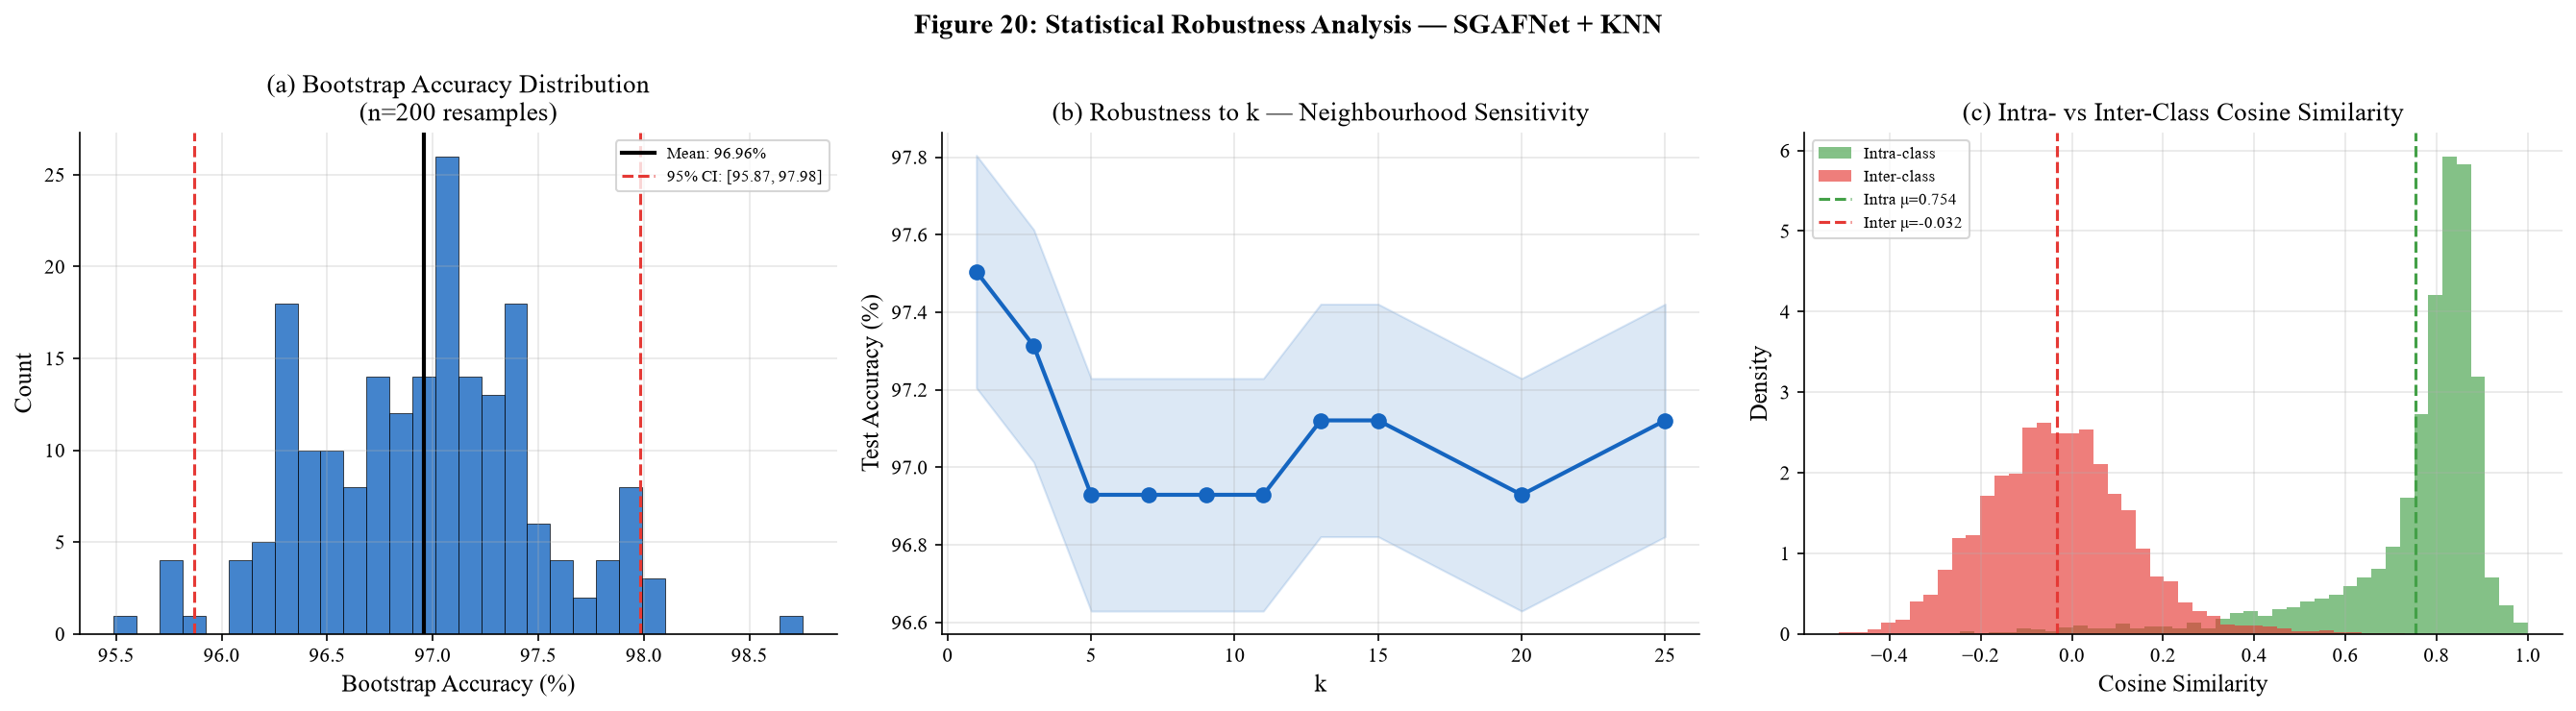

In [21]:
plot_figure1_training_curves(history)

plot_figure2_confusion_matrix(y_test, knn_pred1, class_names)

plot_figure3_per_class_f1(y_test, knn_pred1, pred, class_names)

plot_figure4_architecture_diagram()

Xr_test_tf  = np.transpose(Xr_test,  (0, 2, 1))
Xr_train_tf = np.transpose(Xr_train, (0, 2, 1))

plot_figure5_attention_maps(
    attention_model, Xr_test_tf, X_test, y_test, class_names
)

plot_figure6_tsne(
    model,
    Xr_train_tf, X_train,
    Xr_test_tf,  X_test,
    y_train, y_test, class_names,
)

plot_figure7_knn_neighbor_distances(
    model,
    Xr_train_tf, X_train,
    Xr_test_tf,  X_test,
    y_train, y_test, class_names,
)

plot_figure8_pca3d(
    model, Xr_test_tf, X_test, y_test, class_names
)

plot_figure9_head_comparison(y_test, pred, knn_pred1, class_names)

plot_figure10_contrastive_loss(history)

plot_figure11_multiscale_activations(
    model, Xr_test_tf, X_test, y_test, class_names
)

plot_figure12_se_channel_weights(
    model, Xr_test_tf, X_test, y_test, class_names
)

plot_figure13_feature_importance(X_train, y_train, top_k=40)

plot_figure14_metrics_heatmap(y_test, knn_pred1, class_names)

plot_figure15_roc_curves(
    model,
    Xr_train_tf, X_train,
    Xr_test_tf,  X_test,
    y_train, y_test, class_names,
)

plot_figure16_k_sensitivity(
    model,
    Xr_train_tf, X_train,
    Xr_test_tf,  X_test,
    y_train, y_test,
)

plot_figure17_embedding_norms(
    model,
    Xr_train_tf, X_train,
    Xr_test_tf,  X_test,
    y_train, y_test, class_names,
)


# -- Ablation study results ----------------------------------
# These come from the separate ablation runs (not executed in this
# notebook), so they are named variables you can update in one place
# instead of fixed numbers buried inside the plot call. The last
# variant reuses the notebook's own full-model result.
ablation_feat_only_acc        = 0.9210   # Feat-only (MLP)
ablation_raw_only_acc         = 0.8940   # Raw-only (Conv1D)
ablation_feat_raw_noattn_acc  = 0.9480   # Feat + Raw (no attention)
ablation_feat_raw_mhattn_acc  = 0.9670   # Feat + Raw + Multi-Head Attention
ablation_se_block_acc         = 0.9730   # + SE block
ablation_contrastive_acc      = 0.9800   # + Contrastive loss
ablation_full_sgafnet_knn_acc = knn_acc  # Full SGAFNet + KNN (actual result)

plot_figure18_ablation(ablation_results={
    "Feat-only (MLP)":        ablation_feat_only_acc,
    "Raw-only (Conv1D)":      ablation_raw_only_acc,
    "Feat + Raw (no attn)":   ablation_feat_raw_noattn_acc,
    "Feat + Raw + MH-Attn":   ablation_feat_raw_mhattn_acc,
    "+ SE block":             ablation_se_block_acc,
    "+ Contrastive loss":     ablation_contrastive_acc,
    "Full SGAFNet + KNN":     ablation_full_sgafnet_knn_acc,
})


# -- Model comparison (Figure 19) -----------------------------
# Pulled straight from the metrics already computed in `rows`
# (the COMPREHENSIVE MODEL EVALUATION SUMMARY table above), so
# these numbers can never drift out of sync with that table.
fig19_display_names = [
    "KNN (k=5)",
    "Multi-Scale 1D-CNN",
    "Approach 1 (KNN-style NN)",
    "Approach 2 (Siamese + KNN)",
    "Approach 3 (Diff. KNN Layer)",
    "Approach 3 (Diff. KNN Layer improved)",
    "Approach 4 (Feature Extractor + KNN)",
    "Approach 4 (NN head)",
    "SGAFNet (softmax head)",
    "SGAFNet + KNN embedding head (ours)",
]

comparison_dict = {
    label: {"acc": row["Test Acc"], "f1": row["F1"]}
    for label, row in zip(fig19_display_names, rows)
}

plot_figure19_model_comparison(comparison_dict=comparison_dict)

# ── Figure 20 ───────────────────────────────────────────────────────
plot_figure20_statistical_robustness(
    model,
    Xr_train_tf, X_train,
    Xr_test_tf,  X_test,
    y_train, y_test,
)

>>> Full SGAFNet | seed=42
    softmax=92.32%  knn=95.39%  params=742,257  202s
>>> w/o Contrastive loss | seed=42
    softmax=95.20%  knn=97.70%  params=742,257  358s
>>> w/o Spectral-guided attention | seed=42
    softmax=96.45%  knn=97.50%  params=659,697  358s
>>> w/o Fusion gate | seed=42
    softmax=94.24%  knn=95.78%  params=676,465  351s
>>> w/o Attention & gate (concat) | seed=42
    softmax=94.34%  knn=95.78%  params=593,905  374s
>>> w/o SE blocks | seed=42
    softmax=95.01%  knn=96.93%  params=741,597  271s
>>> w/o Multi-scale (single kernel) | seed=42
    softmax=96.07%  knn=98.08%  params=741,492  328s
>>> Temporal branch only | seed=42
    softmax=90.50%  knn=93.86%  params=113,265  379s
>>> Spectral branch only | seed=42
    softmax=95.30%  knn=95.97%  params=499,082  38s

ABLATION STUDY RESULTS


,Variant,Softmax Acc (%),KNN-Emb Acc (%),Best (%),Δ vs Full (pp),Params,Time (s)
0,Full SGAFNet,92.32 ± 0.00,95.39 ± 0.00,95.39,0.00,"742,257",202
1,w/o Contrastive loss,95.20 ± 0.00,97.70 ± 0.00,97.70,2.30,"742,257",358
2,w/o Spectral-guided attention,96.45 ± 0.00,97.50 ± 0.00,97.50,2.11,"659,697",358
3,w/o Fusion gate,94.24 ± 0.00,95.78 ± 0.00,95.78,0.38,"676,465",351
4,w/o Attention & gate (concat),94.34 ± 0.00,95.78 ± 0.00,95.78,0.38,"593,905",374
5,w/o SE blocks,95.01 ± 0.00,96.93 ± 0.00,96.93,1.54,"741,597",271
6,w/o Multi-scale (single kernel),96.07 ± 0.00,98.08 ± 0.00,98.08,2.69,"741,492",328
7,Temporal branch only,90.50 ± 0.00,93.86 ± 0.00,93.86,-1.54,"113,265",379
8,Spectral branch only,95.30 ± 0.00,95.97 ± 0.00,95.97,0.58,"499,082",38


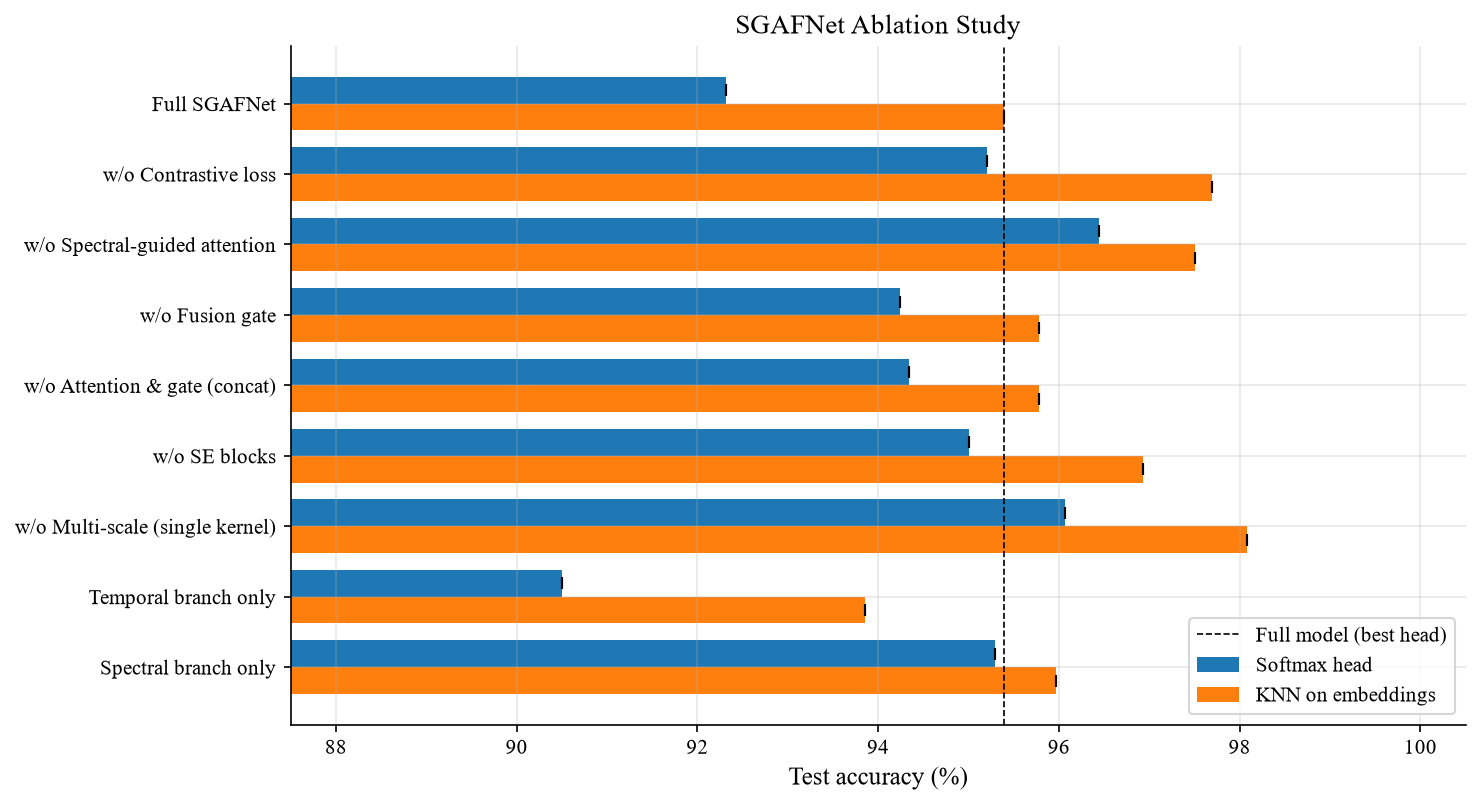

In [22]:
# ======================================================================
# ABLATION STUDY -- SGAFNet
# ======================================================================
import time, gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers, Model
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import normalize

from novel_eeg_model import SupervisedContrastiveLoss

# ----------------------------- CONFIG ---------------------------------
EPOCHS      = 80          # lower than the 120 used for the main run, to save time
BATCH_SIZE  = 64
SEEDS       = [42]        # e.g. [42, 7, 123] gives mean +/- std (3x runtime)
VAL_FRAC    = 0.15
TEMPERATURE = 0.1
CONTRASTIVE_W = 0.4

# ------------------------- data preparation ---------------------------
def prep_raw(X):
    X = np.asarray(X, dtype=np.float32)
    X = (X - X.mean(axis=2, keepdims=True)) / (X.std(axis=2, keepdims=True) + 1e-8)
    X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)
    return np.transpose(X, (0, 2, 1))             # (N, C, T) -> (N, T, C)

Xr_tr, Xr_te = prep_raw(Xr_train), prep_raw(Xr_test)
Xf_tr = np.asarray(X_train, dtype=np.float32)
Xf_te = np.asarray(X_test,  dtype=np.float32)
y_tr_all, y_te = np.asarray(y_train), np.asarray(y_test)

TIME_STEPS, N_CH, FEAT_DIM = Xr_tr.shape[1], Xr_tr.shape[2], Xf_tr.shape[1]

# ----------------- configurable SGAFNet builder ------------------------
def se_block(x, reduction=8):
    c = x.shape[-1]
    s = layers.GlobalAveragePooling1D()(x)
    s = layers.Dense(max(c // reduction, 4), activation="relu")(s)
    s = layers.Dense(c, activation="sigmoid")(s)
    s = layers.Reshape((1, c))(s)
    return layers.Multiply()([x, s])

def build_variant(use_temporal=True, use_spectral=True, use_se=True,
                  multiscale=True, fusion="guided_attention"):
    """
    fusion: 'guided_attention' -> full model (attention + gate)
            'attention_no_gate'-> attention, plain concat (no gating)
            'pool_gate'        -> global-avg-pool instead of attention, with gate
            'pool_concat'      -> global-avg-pool + plain concat (naive fusion)
    """
    inputs = []

    # ---- temporal branch ----
    temporal_seq = None
    if use_temporal:
        raw_inp = layers.Input(shape=(TIME_STEPS, N_CH), name="raw_input")
        inputs.append(raw_inp)

        def scale_branch(k, f):
            x = layers.SeparableConv1D(f, k, padding="same")(raw_inp)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("elu")(x)
            return se_block(x) if use_se else x

        if multiscale:
            merged = layers.Concatenate()([scale_branch(31, 24),
                                           scale_branch(15, 24),
                                           scale_branch(7, 24)])
        else:                                      # single scale, same total width
            merged = scale_branch(15, 72)

        x = layers.Conv1D(96, 5, padding="same")(merged)
        x = layers.BatchNormalization()(x); x = layers.Activation("elu")(x)
        x = layers.MaxPooling1D(2)(x);      x = layers.Dropout(0.25)(x)
        x = layers.Conv1D(128, 3, padding="same")(x)
        x = layers.BatchNormalization()(x); x = layers.Activation("elu")(x)
        temporal_seq = layers.Dropout(0.30)(x)

    # ---- spectral branch ----
    spectral_vec = None
    if use_spectral:
        feat_inp = layers.Input(shape=(FEAT_DIM,), name="feat_input")
        inputs.append(feat_inp)
        x = layers.Dense(256, activation="relu")(feat_inp)
        x = layers.BatchNormalization()(x); x = layers.Dropout(0.30)(x)
        x = layers.Dense(128, activation="relu")(x)
        spectral_vec = layers.BatchNormalization()(x)

    # ---- fusion ----
    if use_temporal and use_spectral:
        seq_dim = temporal_seq.shape[-1]
        if fusion in ("guided_attention", "attention_no_gate"):
            q = layers.Dense(seq_dim)(spectral_vec)
            q = layers.Reshape((1, seq_dim))(q)
            att = layers.MultiHeadAttention(num_heads=4, key_dim=32)(
                query=q, value=temporal_seq, key=temporal_seq)
            summary = layers.Reshape((seq_dim,))(att)
        else:
            summary = layers.GlobalAveragePooling1D()(temporal_seq)

        concat = layers.Concatenate()([summary, spectral_vec])
        if fusion in ("guided_attention", "pool_gate"):
            gate = layers.Dense(concat.shape[-1], activation="sigmoid")(concat)
            concat = layers.Multiply()([concat, gate])
        fused_in = concat
    elif use_temporal:
        fused_in = layers.GlobalAveragePooling1D()(temporal_seq)
    else:
        fused_in = spectral_vec

    f = layers.Dense(128, activation="relu")(fused_in)
    f = layers.BatchNormalization()(f)
    fused = layers.Dense(128, activation=None)(f)

    out_cls = layers.Dense(num_classes, activation="softmax", name="classifier")(
        layers.Dropout(0.35)(fused))
    out_emb = layers.Activation("linear", name="embedding")(fused)
    return Model(inputs, [out_cls, out_emb])

# --------------------------- variants ----------------------------------
# name: (builder kwargs, contrastive weight)
VARIANTS = {
    "Full SGAFNet":                    (dict(), CONTRASTIVE_W),
    "w/o Contrastive loss":            (dict(), 0.0),
    "w/o Spectral-guided attention":   (dict(fusion="pool_gate"), CONTRASTIVE_W),
    "w/o Fusion gate":                 (dict(fusion="attention_no_gate"), CONTRASTIVE_W),
    "w/o Attention & gate (concat)":   (dict(fusion="pool_concat"), CONTRASTIVE_W),
    "w/o SE blocks":                   (dict(use_se=False), CONTRASTIVE_W),
    "w/o Multi-scale (single kernel)": (dict(multiscale=False), CONTRASTIVE_W),
    "Temporal branch only":            (dict(use_spectral=False), CONTRASTIVE_W),
    "Spectral branch only":            (dict(use_temporal=False), CONTRASTIVE_W),
}

def make_inputs(use_temporal, use_spectral, idx=None, test=False):
    Xr = Xr_te if test else Xr_tr
    Xf = Xf_te if test else Xf_tr
    if idx is not None:
        Xr, Xf = Xr[idx], Xf[idx]
    out = []
    if use_temporal: out.append(Xr)
    if use_spectral: out.append(Xf)
    return out

# --------------------------- runner ------------------------------------
def run_variant(name, kwargs, c_weight, seed):
    keras.backend.clear_session(); gc.collect()
    tf.keras.utils.set_random_seed(seed)

    ut, us = kwargs.get("use_temporal", True), kwargs.get("use_spectral", True)
    model = build_variant(**kwargs)
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss={"classifier": keras.losses.SparseCategoricalCrossentropy(label_smoothing=0.05),
              "embedding":  SupervisedContrastiveLoss(temperature=TEMPERATURE)},
        loss_weights={"classifier": 1.0, "embedding": c_weight},
        metrics={"classifier": "accuracy"},
    )

    idx_tr, idx_val = train_test_split(np.arange(len(y_tr_all)), test_size=VAL_FRAC,
                                       stratify=y_tr_all, random_state=seed)
    cbs = [
        keras.callbacks.EarlyStopping(monitor="val_classifier_accuracy", mode="max",
                                      patience=20, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_classifier_accuracy", mode="max",
                                          patience=8, factor=0.5, min_lr=1e-6),
    ]
    t0 = time.time()
    model.fit(make_inputs(ut, us, idx_tr),
              [y_tr_all[idx_tr], y_tr_all[idx_tr]],
              validation_data=(make_inputs(ut, us, idx_val),
                               [y_tr_all[idx_val], y_tr_all[idx_val]]),
              epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=cbs, verbose=0)
    train_time = time.time() - t0

    # softmax head (test set evaluated once)
    te_logits, te_emb = model.predict(make_inputs(ut, us, test=True), verbose=0)
    soft_acc = accuracy_score(y_te, te_logits.argmax(1))

    # KNN read-out on embeddings (k chosen on a train-only validation split)
    _, tr_emb = model.predict(make_inputs(ut, us), verbose=0)
    tr_n, te_n = normalize(tr_emb), normalize(te_emb)
    Xa, Xb, ya, yb = train_test_split(tr_n, y_tr_all, test_size=VAL_FRAC,
                                      stratify=y_tr_all, random_state=seed)
    best_k, best_a = 5, 0.0
    for k in [3, 5, 7, 9, 11, 15]:
        a = KNeighborsClassifier(n_neighbors=k, weights="distance",
                                 metric="cosine").fit(Xa, ya).score(Xb, yb)
        if a > best_a: best_k, best_a = k, a
    knn = KNeighborsClassifier(n_neighbors=best_k, weights="distance",
                               metric="cosine").fit(tr_n, y_tr_all)
    knn_acc = accuracy_score(y_te, knn.predict(te_n))

    return dict(softmax_acc=soft_acc, knn_acc=knn_acc,
                params=model.count_params(), time_s=train_time)

# --------------------------- execute -----------------------------------
records = []
for name, (kw, cw) in VARIANTS.items():
    for seed in SEEDS:
        print(f">>> {name} | seed={seed}")
        r = run_variant(name, kw, cw, seed)
        r.update(variant=name, seed=seed)
        records.append(r)
        print(f"    softmax={r['softmax_acc']*100:.2f}%  "
              f"knn={r['knn_acc']*100:.2f}%  params={r['params']:,}  {r['time_s']:.0f}s")

raw = pd.DataFrame(records)
raw["best_acc"] = raw[["softmax_acc", "knn_acc"]].max(axis=1)

agg = (raw.groupby("variant", sort=False)
          .agg(softmax_mean=("softmax_acc", "mean"), softmax_std=("softmax_acc", "std"),
               knn_mean=("knn_acc", "mean"),         knn_std=("knn_acc", "std"),
               best_mean=("best_acc", "mean"),
               params=("params", "first"), time_s=("time_s", "mean"))
          .fillna(0.0))

full_best = agg.loc["Full SGAFNet", "best_mean"]
agg["delta_vs_full (pp)"] = (agg["best_mean"] - full_best) * 100

table = pd.DataFrame({
    "Variant": agg.index,
    "Softmax Acc (%)": [f"{m*100:.2f} ± {s*100:.2f}" for m, s in zip(agg.softmax_mean, agg.softmax_std)],
    "KNN-Emb Acc (%)": [f"{m*100:.2f} ± {s*100:.2f}" for m, s in zip(agg.knn_mean, agg.knn_std)],
    "Best (%)": (agg.best_mean * 100).round(2).values,
    "Δ vs Full (pp)": agg["delta_vs_full (pp)"].round(2).values,
    "Params": agg.params.map("{:,}".format).values,
    "Time (s)": agg.time_s.round(0).astype(int).values,
}).reset_index(drop=True)

print("\n" + "=" * 100)
print("ABLATION STUDY RESULTS")
print("=" * 100)
display(table)                      # use print(table.to_string()) outside Jupyter
table.to_csv("ablation_results.csv", index=False)

# ----------------------------- plot ------------------------------------
fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(agg))
h = 0.38
ax.barh(y - h/2, agg.softmax_mean*100, h, xerr=agg.softmax_std*100, label="Softmax head", capsize=3)
ax.barh(y + h/2, agg.knn_mean*100,     h, xerr=agg.knn_std*100,     label="KNN on embeddings", capsize=3)
ax.set_yticks(y); ax.set_yticklabels(agg.index); ax.invert_yaxis()
lo = min(agg.softmax_mean.min(), agg.knn_mean.min()) * 100
ax.set_xlim(max(lo - 3, 0), 100.5)
ax.set_xlabel("Test accuracy (%)")
ax.set_title("SGAFNet Ablation Study")
ax.axvline(full_best*100, color="k", ls="--", lw=0.8, label="Full model (best head)")
ax.legend(loc="lower right"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("ablation_study1.png", dpi=300)
plt.show()